# UTS Big Data & Predictive Analytics Lanjut (ST153) · Notebook **MASTER**
**Studi kasus:** pemantauan penyuntingan Wikipedia hampir real-time (Wikimedia EventStreams → Kafka → Spark → dashboard).

**PC Master** menjalankan broker Kafka, Spark Master (standalone), producer SSE, driver Spark (Soal 2–4), dan dashboard.
**4 PC Worker** menjalankan `UTS_Worker_1.ipynb` … `UTS_Worker_4.ipynb` sampai sel loop agen. Worker otomatis:
(1) menyalakan Spark Worker yang mendaftar ke `spark://MASTER_IP:7077`, (2) mengirim detak (heartbeat) ke Master lewat Kafka,
(3) menjadi anggota consumer group untuk uji decoupling (Soal 1c), dan (4) membuat salinan snapshot untuk `sc.textFile` (Soal 2).

```
 Wikimedia EventStreams (SSE, JSON)
           │  User-Agent, reconnect (Last-Event-ID)
           ▼
 Producer Python (thread di PC Master) ── pilih field, hash IP ──►  Kafka broker (PC Master)
                                                                    topic k1-wiki-raw · 8 partisi · key = wiki|title
           ┌───────────────────────────────┬─────────────────────────────┴────────────────┐
           ▼                               ▼                                              ▼
 Consumer group Worker 1–4        Spark Standalone Cluster                     Spark Structured Streaming
 (uji decoupling, Soal 1c)        RDD + DataFrame/SQL (Soal 2–3)               window 1 mnt, watermark 2 mnt (Soal 4)
                                                                                  │ foreachBatch + checkpoint
 Notebook Master ⇄ k1-kontrol / k1-status ⇄ Notebook Worker                       ▼
                                                                             Dashboard (notebook Master)
```

**Persiapan:**
1. Broker Kafka hidup di PC Master dengan `advertised.listeners=PLAINTEXT://MASTER_IP:9092`. Port 9092, 7077, 7078–7079, 8080, 4040 tidak diblokir firewall.
2. Semua PC memakai **Python (major.minor)** dan **PySpark** versi sama, serta Java (JDK 17/21 untuk Spark 4.x; 8/11/17 untuk Spark 3.5).
3. Windows: checkpoint Structured Streaming butuh `HADOOP_HOME` berisi `bin\winutils.exe` (dicek di Sel 2).
4. Jalankan Sel 1–5 di Master, lalu jalankan notebook Worker di 4 PC sampai loop agen berjalan, kemudian lanjutkan Sel 6 dan seterusnya.

Semua bukti (log, tabel, grafik) otomatis disimpan ke `laporan_uts/<kelompok>/` untuk bahan laporan.

## Sel 1 · Konfigurasi

In [1]:
!pip install confluent-kafka pyspark pandas matplotlib psutil     


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# ===== SEL 1: KONFIGURASI (ISI SESUAI KELOMPOK) =====

import os, sys, re, io, json, time, uuid, math, socket, hashlib, hmac, ipaddress, threading, subprocess, contextlib, random, shutil, platform
from pathlib import Path
from collections import Counter, defaultdict

# ---------------- ISI SESUAI KELOMPOK ANDA ----------------
KELOMPOK   = "JOGIS-GANK"                    # sama persis dengan notebook Worker
MASTER_IP  = "192.168.18.173"            # IP PC Master ini (= advertised.listeners broker Kafka)
N_WORKER   = 4                       # jumlah PC Worker
KONTAK_UA  = "kelompok-k1@students.amikom.ac.id"     # kontak di User-Agent (aturan Wikimedia)
SALT_HASH  = "ganti-kata-rahasia-kelompok"           # kunci HMAC penyamaran IP (jangan dibagikan)
# -----------------------------------------------------------

# --- Kafka ---
BOOTSTRAP     = f"{MASTER_IP}:9092"
TOPIC_RAW     = f"{KELOMPOK}-wiki-raw"        # data mentah dari SSE
TOPIC_KONTROL = f"{KELOMPOK}-kontrol"         # Master -> Worker (perintah)
TOPIC_STATUS  = f"{KELOMPOK}-status"          # Worker -> Master (detak & laporan)
PARTISI_RAW   = 8                             # = 4 Worker x 2 core (lihat tabel keputusan desain 1a)
RETENSI_JAM   = 72
GROUP_UJI     = f"{KELOMPOK}-wiki-pemroses"   # consumer group 4 Worker (Soal 1c)
KAFKA_HOME    = None                          # mis. r"C:\kafka" -> perintah CLI Kafka dijalankan otomatis untuk bukti 1b/1c

# --- Sumber data (Soal 1b) ---
MODE_SUMBER   = "sse"     # "sse" = Wikimedia / URL cadangan dosen | "file" = rekaman JSONL/SSE | "simulasi" = data tiruan (uji saja, BUKAN untuk laporan)
URL_SSE       = "https://stream.wikimedia.org/v2/stream/recentchange"
FILE_CADANGAN = None      # path berkas rekaman bila MODE_SUMBER = "file"
USER_AGENT    = f"UTS-BigData-AMIKOM/1.0 (kelompok {KELOMPOK}; pipeline Kafka-Spark tugas kuliah; {KONTAK_UA})"
TIMEOUT_BACA  = 60        # detik tanpa data -> koneksi dianggap macet lalu reconnect
DURASI_PRODUCER_MENIT = 10        # monitor 1b minimal 10 menit (producer tetap jalan sesudahnya)
TARGET_SNAPSHOT = 200_000         # Soal 2: minimal 200.000 pesan (atau seluruh yang terkumpul)

# --- Soal 1c ---
DETIK_FASE_JALAN = 60     # consumer berjalan normal
DETIK_BERHENTI   = 120    # consumer dihentikan sekitar 2 menit, producer tetap jalan
DETIK_KEJAR      = 120    # batas waktu consumer mengejar ketertinggalan

# --- Spark ---
MULAI_SPARK_MASTER   = True              # False bila Spark Master sudah dinyalakan manual
SPARK_MASTER_URL     = f"spark://{MASTER_IP}:7077"
CORE_PER_WORKER      = 2
MEMORI_EXECUTOR      = "1g"
PAKAI_KONEKTOR_KAFKA = True              # spark-sql-kafka-0-10 diunduh dari Maven saat sesi Spark PERTAMA dibuat
JAR_KAFKA_LOKAL      = None              # daftar path .jar bila tidak ada internet ke Maven
FOLDER_BERSAMA       = None              # mis. r"Z:\uts_k1" (folder jaringan, path sama di semua PC). None = salinan lokal tiap PC
SUMBER_SNAPSHOT      = "jsonl"           # Soal 2: "jsonl" (sc.textFile) | "kafka" (konektor mode batch)

# --- Soal 4 ---
MODE_STREAM        = "kafka" if PAKAI_KONEKTOR_KAFKA else "jembatan"   # "jembatan" = micro-batch manual Kafka -> berkas -> Spark
WATERMARK          = "2 minutes"
DETIK_UJI_TRIGGER  = {"10 seconds": 150, "30 seconds": 240}
DETIK_JEDA_RESTART = 60
MENIT_DASHBOARD    = 5

# --- Folder & identitas run ---
ROOT_DATA   = (Path("C:/Users/Public/uts_bigdata") if os.name == "nt" else Path("/tmp/uts_bigdata")) / KELOMPOK
LAPORAN_DIR = Path("laporan_uts") / KELOMPOK
for _d in (ROOT_DATA, LAPORAN_DIR / "bukti", LAPORAN_DIR / "grafik", LAPORAN_DIR / "log"):
    _d.mkdir(parents=True, exist_ok=True)
RUN_ID     = uuid.uuid4().hex[:6]
TOTAL_CORE = N_WORKER * CORE_PER_WORKER
RINGKASAN  = {"kelompok": KELOMPOK, "run_id": RUN_ID, "mulai": time.strftime("%Y-%m-%d %H:%M:%S")}
print(f"Kelompok {KELOMPOK} | Master {MASTER_IP} | Worker {N_WORKER} | RUN_ID {RUN_ID}")
print("Folder data :", ROOT_DATA.resolve())
print("Folder bukti:", LAPORAN_DIR.resolve())

Kelompok JOGIS-GANK | Master 192.168.18.173 | Worker 4 | RUN_ID 51bb3e
Folder data : C:\Users\Public\uts_bigdata\JOGIS-GANK
Folder bukti: C:\BigData\notebooks\laporan_uts\JOGIS-GANK


## Sel 2 · Utilitas, penyimpan bukti, dan cek lingkungan

In [3]:
# ===== SEL 2: Utilitas, bukti laporan, dan cek lingkungan =====
import urllib.request, urllib.error, urllib.parse, warnings
import pandas as pd
warnings.filterwarnings("ignore", message=".*(Arrow|pandas >= 3|does not yet fully support).*")
import matplotlib.pyplot as plt
from IPython.display import display, clear_output, HTML, Markdown
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 180)

BUKTI_DIR, GRAFIK_DIR, LOG_DIR = LAPORAN_DIR / "bukti", LAPORAN_DIR / "grafik", LAPORAN_DIR / "log"

def bukti(nama, isi):
    """Simpan bukti ke laporan_uts/<kelompok>/bukti/ (teks, DataFrame pandas, atau dict/list)."""
    if isinstance(isi, pd.DataFrame):
        p = BUKTI_DIR / f"{nama}.csv"; isi.to_csv(p, index=False)
    elif isinstance(isi, (dict, list)):
        p = BUKTI_DIR / f"{nama}.json"
        p.write_text(json.dumps(isi, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
    else:
        p = BUKTI_DIR / f"{nama}.txt"; p.write_text(str(isi), encoding="utf-8")
    return p

class _Tee:
    def __init__(self, *aliran):
        self.aliran = aliran
    def write(self, s):
        for a in self.aliran:
            a.write(s)
        return len(s)
    def flush(self):
        for a in self.aliran:
            if hasattr(a, "flush"):
                a.flush()

@contextlib.contextmanager
def catat(nama):
    """Semua print di dalam blok ini tampil di notebook DAN tersimpan sebagai bukti teks."""
    buf, lama = io.StringIO(), sys.stdout
    sys.stdout = _Tee(lama, buf)
    try:
        yield
    finally:
        sys.stdout = lama
        bukti(nama, buf.getvalue())

def simpan_grafik(fig, nama):
    p = GRAFIK_DIR / f"{nama}.png"
    fig.savefig(p, dpi=120, bbox_inches="tight")
    return p

def tabel_md(df):
    """DataFrame -> tabel Markdown (tanpa paket tambahan), untuk ditempel ke laporan."""
    kol = [str(c) for c in df.columns]
    baris = ["| " + " | ".join(kol) + " |", "|" + "|".join("---" for _ in kol) + "|"]
    for r in df.itertuples(index=False):
        baris.append("| " + " | ".join(str(v).replace("|", "\\|") for v in r) + " |")
    return "\n".join(baris)

_buka = urllib.request.build_opener(urllib.request.ProxyHandler({})).open    # akses lokal tanpa proxy
def ambil_json(url, timeout=5):
    with _buka(url, timeout=timeout) as r:
        return json.loads(r.read().decode("utf-8"))

def port_terbuka(host, port, timeout=1.5):
    try:
        with socket.create_connection((host, port), timeout=timeout):
            return True
    except OSError:
        return False

def ip_lokal():
    ips = set()
    try:
        ips |= {i[4][0] for i in socket.getaddrinfo(socket.gethostname(), None)}
    except socket.gaierror:
        pass
    try:
        s = socket.socket(socket.AF_INET, socket.SOCK_DGRAM); s.connect((MASTER_IP, 9092))
        ips.add(s.getsockname()[0]); s.close()
    except OSError:
        pass
    return ips

def versi_java():
    java = Path(os.environ["JAVA_HOME"]) / "bin" / "java" if os.environ.get("JAVA_HOME") else "java"
    try:
        r = subprocess.run([str(java), "-version"], capture_output=True, text=True, timeout=20)
        teks = (r.stderr or r.stdout).strip().splitlines()
        return next((b for b in teks if "version" in b), teks[0] if teks else "?")
    except Exception as e:
        return f"tidak ditemukan ({e.__class__.__name__})"

try:
    import psutil
except ImportError:
    psutil = None
import pyspark, confluent_kafka

LINGKUNGAN = {"host": socket.gethostname(), "os": platform.platform(), "python": platform.python_version(),
              "executable": sys.executable, "pyspark": pyspark.__version__,
              "confluent_kafka": confluent_kafka.version()[0], "librdkafka": confluent_kafka.libversion()[0],
              "pandas": pd.__version__, "java": versi_java(), "psutil": psutil is not None}
with catat("0_lingkungan_master"):
    for k, v in LINGKUNGAN.items():
        print(f"{k:<16}: {v}")
    if MASTER_IP not in ip_lokal() and not MASTER_IP.startswith("127."):
        print(f"\nPERINGATAN: MASTER_IP {MASTER_IP} tidak ditemukan di PC ini {sorted(ip_lokal())}. Periksa Sel 1.")
    if os.name == "nt":
        hh = os.environ.get("HADOOP_HOME")
        if not hh or not (Path(hh) / "bin" / "winutils.exe").exists():
            print("\nPERINGATAN Windows: HADOOP_HOME/bin/winutils.exe belum ada. Soal 2–3 tetap jalan, tetapi checkpoint"
                  " Structured Streaming (Soal 4) bisa gagal. Pasang winutils sesuai versi Hadoop Spark, set HADOOP_HOME, restart Jupyter.")
        if " " in str(Path(pyspark.__file__).parent):
            print("\nPERINGATAN: path PySpark mengandung spasi; skrip spark-class di Windows sering gagal. Pakai folder tanpa spasi.")
    print("\nKafka broker", BOOTSTRAP, "terjangkau:", port_terbuka(MASTER_IP, int(BOOTSTRAP.split(":")[1])))

host            : rafaul
os              : Windows-11-10.0.26300-SP0
python          : 3.14.8
executable      : C:\BigData\venv\Scripts\python.exe
pyspark         : 4.1.3
confluent_kafka : 2
librdkafka      : 2.16.0
pandas          : 3.0.6
java            : openjdk version "21.0.12.1" 2026-08-18 LTS
psutil          : True

Kafka broker 192.168.18.173:9092 terjangkau: True


## Sel 3 · Kafka: membuat topic, producer kontrol, dan fungsi offset
Topic mentah memakai keputusan desain Soal 1a (8 partisi, retensi 72 jam, replikasi 1).

In [4]:
# ===== SEL 3: Kafka - topic, producer kontrol, dan fungsi offset =====
from confluent_kafka import Producer, Consumer, TopicPartition, KafkaError, KafkaException
from confluent_kafka.admin import AdminClient, NewTopic, NewPartitions, ConfigResource

admin = AdminClient({"bootstrap.servers": BOOTSTRAP})
KONFIG_TOPIC_RAW = {"retention.ms": str(RETENSI_JAM * 3600 * 1000), "cleanup.policy": "delete"}

def buat_topic(nama, partisi, konfig=None):
    f = admin.create_topics([NewTopic(nama, num_partitions=partisi, replication_factor=1, config=konfig or {})],
                            request_timeout=15)[nama]
    try:
        f.result(); return "dibuat"
    except Exception as e:
        teks = str(e)
        return "sudah ada" if ("TOPIC_ALREADY_EXISTS" in teks or "already exists" in teks.lower()) else f"gagal: {teks[:90]}"

def partisi_topik(nama=TOPIC_RAW, timeout=10):
    t = admin.list_topics(timeout=timeout).topics.get(nama)     # tanpa argumen topic: tidak memicu auto-create
    return [] if t is None or t.error is not None else sorted(t.partitions)

_kons_wm = Consumer({"bootstrap.servers": BOOTSTRAP, "group.id": f"{KELOMPOK}-wm-{RUN_ID}", "enable.auto.commit": False})
_kunci_wm = threading.Lock()
def watermark(topik=TOPIC_RAW):
    """{partisi: (low, high)}; high = log-end-offset (offset pesan berikutnya)."""
    with _kunci_wm:
        return {p: _kons_wm.get_watermark_offsets(TopicPartition(topik, p), timeout=10) for p in partisi_topik(topik)}

def total_pesan(wm=None):
    wm = wm or watermark()
    return sum(hi - lo for lo, hi in wm.values())

def offset_grup(group, topik=TOPIC_RAW):
    """Offset ter-commit milik consumer group (setara kafka-consumer-groups --describe). -1001 = belum ada commit."""
    c = Consumer({"bootstrap.servers": BOOTSTRAP, "group.id": group, "enable.auto.commit": False})
    try:
        return {tp.partition: tp.offset for tp in c.committed([TopicPartition(topik, p) for p in partisi_topik(topik)], timeout=10)}
    finally:
        c.close()

def baca_rentang(rentang, per_pesan, topik=TOPIC_RAW, batas_diam=30):
    """Baca pesan offset [a, b) tiap partisi secara berurutan (partisi naik, offset naik)."""
    c = Consumer({"bootstrap.servers": BOOTSTRAP, "group.id": f"{KELOMPOK}-baca-{uuid.uuid4().hex[:6]}",
                  "enable.auto.commit": False, "auto.offset.reset": "earliest"})
    n = 0
    try:
        for p in sorted(rentang):
            a, b = rentang[p]
            if b <= a:
                continue
            c.assign([TopicPartition(topik, p, a)])
            pos, t_diam = a, time.time()
            while pos < b:
                msgs = c.consume(1000, timeout=1.0)
                if not msgs:
                    if time.time() - t_diam > batas_diam:
                        print(f"  peringatan: partisi {p} berhenti di offset {pos} (target {b})"); break
                    continue
                t_diam = time.time()
                for m in msgs:
                    if m.error() or m.partition() != p or m.offset() < pos:
                        continue
                    if m.offset() >= b:
                        pos = b; break
                    per_pesan(m); n += 1; pos = m.offset() + 1
            c.unassign()
    finally:
        c.close()
    return n

prod_kontrol = Producer({"bootstrap.servers": BOOTSTRAP, "acks": "all", "linger.ms": 5})
def kirim_kontrol(aksi, target="semua", **isi):
    """Perintah Master -> Worker. Selalu ke partisi 0 agar urutan perintah terjaga."""
    cmd = {"run": RUN_ID, "cmd_id": uuid.uuid4().hex[:8], "aksi": aksi, "target": target, "waktu": time.time(), **isi}
    prod_kontrol.produce(TOPIC_KONTROL, value=json.dumps(cmd).encode("utf-8"), partition=0)
    prod_kontrol.flush(10)
    return cmd["cmd_id"]

hasil_topic = {TOPIC_RAW: buat_topic(TOPIC_RAW, PARTISI_RAW, KONFIG_TOPIC_RAW),
               TOPIC_KONTROL: buat_topic(TOPIC_KONTROL, 1), TOPIC_STATUS: buat_topic(TOPIC_STATUS, 3)}
time.sleep(1)
p_raw = partisi_topik(TOPIC_RAW)
if 0 < len(p_raw) < PARTISI_RAW:                     # topic terlanjur dibuat otomatis dengan partisi kurang
    try:
        admin.create_partitions([NewPartitions(TOPIC_RAW, PARTISI_RAW)], request_timeout=15)[TOPIC_RAW].result()
        print(f"Partisi {TOPIC_RAW} ditambah dari {len(p_raw)} menjadi {PARTISI_RAW}"); time.sleep(1)
    except Exception as e:
        print("Tidak bisa menambah partisi:", e)

def deskripsi_topic(nama):
    t = admin.list_topics(timeout=10).topics.get(nama)
    if t is None:
        return pd.DataFrame()
    return pd.DataFrame([{"topic": nama, "partisi": p, "leader": pm.leader, "replika": list(pm.replicas), "isr": list(pm.isrs)}
                         for p, pm in sorted(t.partitions.items())])

def konfig_topic(nama):
    try:
        res = admin.describe_configs([ConfigResource("topic", nama)], request_timeout=10)
        return {k: v.value for k, v in list(res.values())[0].result().items()
                if k in ("retention.ms", "cleanup.policy", "compression.type", "min.insync.replicas", "max.message.bytes")}
    except Exception as e:
        return {"galat": str(e)[:80]}

with catat("1a_topic_kafka"):
    for nama, st in hasil_topic.items():
        print(f"{nama:<24} {st}")
    for nama in hasil_topic:
        d = deskripsi_topic(nama)
        print(f"\n{nama}: {len(d)} partisi | konfigurasi: {konfig_topic(nama)}")
        if len(d):
            print(d.to_string(index=False))
    if not partisi_topik(TOPIC_RAW):
        print("\nPERINGATAN: topic belum terbaca. Pastikan broker hidup; jika dibuat otomatis, cek num.partitions broker.")

JOGIS-GANK-wiki-raw      sudah ada
JOGIS-GANK-kontrol       sudah ada
JOGIS-GANK-status        sudah ada

JOGIS-GANK-wiki-raw: 8 partisi | konfigurasi: {'compression.type': 'producer', 'min.insync.replicas': '1', 'cleanup.policy': 'delete', 'retention.ms': '259200000', 'max.message.bytes': '1048588'}
              topic  partisi  leader replika isr
JOGIS-GANK-wiki-raw        0       1     [1] [1]
JOGIS-GANK-wiki-raw        1       1     [1] [1]
JOGIS-GANK-wiki-raw        2       1     [1] [1]
JOGIS-GANK-wiki-raw        3       1     [1] [1]
JOGIS-GANK-wiki-raw        4       1     [1] [1]
JOGIS-GANK-wiki-raw        5       1     [1] [1]
JOGIS-GANK-wiki-raw        6       1     [1] [1]
JOGIS-GANK-wiki-raw        7       1     [1] [1]

JOGIS-GANK-kontrol: 1 partisi | konfigurasi: {'compression.type': 'producer', 'min.insync.replicas': '1', 'cleanup.policy': 'delete', 'retention.ms': '604800000', 'max.message.bytes': '1048588'}
             topic  partisi  leader replika isr
JOGIS-GANK-ko

## Sel 4 · Pemantau Master: membaca status Worker dari Kafka
Thread latar membaca `k1-status` terus-menerus, jadi sel lain tetap bisa dijalankan.

In [5]:
# ===== SEL 4: Pemantau Master (thread latar) =====
class PemantauMaster:
    def __init__(self):
        self.lock = threading.Lock()
        self.worker, self.galat = {}, []
        self.ack = defaultdict(dict)              # cmd_id -> {worker: pesan}  (tanda perintah diterima)
        self.balasan = defaultdict(dict)          # cmd_id -> {worker: pesan}  (HASIL: pong, ledger, snapshot)
        self.konsumen = defaultdict(list)         # worker -> riwayat laporan consumer (assign, progres, selesai)
        self.log = []
        self._henti = threading.Event()
        self.c = Consumer({"bootstrap.servers": BOOTSTRAP, "group.id": f"{KELOMPOK}-master-{RUN_ID}", "enable.auto.commit": False})
        # assign langsung di offset akhir tiap partisi: tidak ada pesan status yang terlewat sejak titik ini
        self.c.assign([TopicPartition(TOPIC_STATUS, p, self.c.get_watermark_offsets(TopicPartition(TOPIC_STATUS, p), timeout=10)[1])
                       for p in partisi_topik(TOPIC_STATUS)])
        self.t = threading.Thread(target=self._loop, daemon=True)
        self.t.start()

    def _loop(self):
        while not self._henti.is_set():
            m = self.c.poll(0.5)
            if m is None or m.error():
                continue
            try:
                d = json.loads(m.value())
            except ValueError:
                continue
            d["_terima"] = time.time()
            j, w = d.get("jenis"), d.get("worker")
            with self.lock:
                self.log.append(d)
                del self.log[:-20000]
                if j == "hidup":
                    self.worker[w] = d
                elif j == "ack":
                    self.ack[d.get("cmd_id")][w] = d
                elif j in ("pong", "ledger", "snapshot"):
                    self.balasan[d.get("cmd_id")][w] = d
                elif j in ("assign", "revoke", "progres", "konsumen_mulai", "konsumen_dijeda", "konsumen_selesai"):
                    self.konsumen[w].append(d)
                elif j == "galat":
                    self.galat.append(d)
                if w in self.worker:
                    self.worker[w]["_terima"] = d["_terima"]

    def aktif(self, detik=20, hanya_agen=True):
        """Worker yang detaknya baru diterima. hanya_agen: hanya yang loop agennya (Sel 4 Worker) sudah berjalan."""
        with self.lock:
            return {w: d for w, d in self.worker.items()
                    if time.time() - d["_terima"] < detik and (d.get("agen") or not hanya_agen)}

    def tunggu_balasan(self, cmd_id, n, timeout=30):
        t0 = time.time()
        while time.time() - t0 < timeout:
            with self.lock:
                b = dict(self.balasan.get(cmd_id, {}))
            if len(b) >= n:
                return b
            time.sleep(0.3)
        with self.lock:
            return dict(self.balasan.get(cmd_id, {}))

    def berhenti(self):
        self._henti.set(); self.t.join(3); self.c.close()

if "pemantau" in globals():
    try:
        pemantau.berhenti()
    except Exception:
        pass
pemantau = PemantauMaster()

def tabel_worker():
    rows = []
    for w, d in sorted(pemantau.aktif(60, hanya_agen=False).items(), key=lambda kv: kv[1].get("nomor", 0)):
        rows.append({"worker": w, "nomor": d.get("nomor"), "ip": d.get("ip"), "detak (dtk lalu)": round(time.time() - d["_terima"], 1),
                     "agen_siap": bool(d.get("agen")),
                     "python": d.get("python"), "pyspark": d.get("pyspark"), "spark_worker": d.get("spark_worker"),
                     "konsumen": d.get("konsumen"), "cpu%": d.get("cpu"), "ram%": d.get("ram")})
    return pd.DataFrame(rows)

def tunggu_worker(n=N_WORKER, timeout=900, refresh=3):
    t0 = time.time()
    try:
        while time.time() - t0 < timeout:
            aktif = pemantau.aktif()
            clear_output(wait=True)
            print(f"Menunggu Worker lewat Kafka ({TOPIC_STATUS}) ... agen siap {len(aktif)}/{n} | {time.time() - t0:.0f} dtk"
                  "  (Worker siap setelah Sel 4 notebook Worker berjalan)")
            if aktif:
                display(tabel_worker())
            if len(aktif) >= n:
                print(f"\nSEMUA {n} WORKER TERHUBUNG."); return True
            time.sleep(refresh)
    except KeyboardInterrupt:
        print("Dihentikan.")
    print(f"Baru {len(pemantau.aktif())}/{n} Worker aktif. Jalankan notebook Worker yang belum, lalu ulangi sel ini.")
    return False

def ping_worker(timeout=15):
    t_kirim = time.time()
    cid = kirim_kontrol("PING")
    b = pemantau.tunggu_balasan(cid, len(pemantau.aktif()), timeout)
    return pd.DataFrame([{"worker": w, "waktu_respon_ms (Master→Kafka→Worker→Kafka→Master, termasuk jeda polling)": round((d["_terima"] - t_kirim) * 1000, 1)}
                         for w, d in sorted(b.items())])
print("Pemantau Master berjalan di latar.")

Pemantau Master berjalan di latar.


## Sel 5 · Spark Master (Standalone) di PC Master
Sel ini menyalakan `org.apache.spark.deploy.master.Master` dari instalasi PySpark. Setelah ini, **jalankan notebook Worker**
di 4 PC: masing-masing menyalakan Spark Worker yang mendaftar ke `spark://MASTER_IP:7077` dan mengirim detak lewat Kafka.

In [6]:
# ===== SEL 5: Spark Master daemon =====
SPARK_HOME_PIP = next((p for p in [Path(os.environ.get("SPARK_HOME", "")), Path(pyspark.__file__).parent, Path(pyspark.__file__).parents[2], Path("C:/spark"), Path("D:/spark")] if (p / "bin" / "spark-class.cmd").exists()), Path("C:/spark"))
SPARK_CLASS = SPARK_HOME_PIP / "bin" / ("spark-class.cmd" if os.name == "nt" else "spark-class")
PROSES = globals().get("PROSES", {})

def jalankan_daemon(nama, argumen, env_tambahan=None):
    env = dict(os.environ, SPARK_HOME=str(SPARK_HOME_PIP), **(env_tambahan or {}))
    log = open(LOG_DIR / f"{nama}.log", "ab")
    flags = subprocess.CREATE_NEW_PROCESS_GROUP if os.name == "nt" else 0
    return subprocess.Popen([str(SPARK_CLASS)] + argumen, stdout=log, stderr=subprocess.STDOUT, env=env,
                            cwd=str(LOG_DIR), creationflags=flags)

def hentikan_proses(proc):
    if proc is None or proc.poll() is not None:
        return
    if os.name == "nt":
        subprocess.run(["taskkill", "/PID", str(proc.pid), "/T", "/F"], capture_output=True)
    else:
        proc.terminate()

def status_cluster():
    try:
        d = ambil_json(f"http://{MASTER_IP}:8080/json/")
    except Exception as e:
        return {"galat": str(e)[:80], "workers": []}
    d["alive"] = [w for w in d.get("workers", []) if w.get("state") == "ALIVE"]
    return d

if MULAI_SPARK_MASTER and not port_terbuka(MASTER_IP, 7077):
    PROSES["spark_master"] = jalankan_daemon("spark-master", ["org.apache.spark.deploy.master.Master",
                                             "--host", MASTER_IP, "--port", "7077", "--webui-port", "8080"],
                                             {"SPARK_LOCAL_IP": MASTER_IP})
    for _ in range(90):
        if port_terbuka(MASTER_IP, 7077) and "galat" not in status_cluster():
            break
        time.sleep(1)
st = status_cluster()
if "galat" in st:
    print("Spark Master BELUM hidup:", st["galat"], f"\nCek log: {LOG_DIR / 'spark-master.log'}")
    print("Menyalakan manual:", f'"{SPARK_CLASS}" org.apache.spark.deploy.master.Master --host {MASTER_IP} --port 7077 --webui-port 8080')
else:
    print("Spark Master hidup :", st.get("url"), "| status:", st.get("status"))
    print("Master UI          :", f"http://{MASTER_IP}:8080   (tangkapan layar untuk laporan)")
    print("Worker terdaftar   :", len(st["alive"]))

Spark Master hidup : spark://192.168.18.173:7077 | status: ALIVE
Master UI          : http://192.168.18.173:8080   (tangkapan layar untuk laporan)
Worker terdaftar   : 7


## Sel 6 · Tunggu 4 Worker terhubung (Kafka + Spark)
Jalankan dulu notebook Worker di keempat PC. Sel ini menunggu detak Kafka, mengukur ping, mencocokkan versi,
lalu menunggu keempat Spark Worker berstatus ALIVE di Spark Master.

In [7]:
# ===== SEL 6: Tunggu Worker (Kafka) + cek versi + tunggu Spark Worker =====
import re, json, urllib.request

if "status_cluster" not in globals():
    def status_cluster(port_webui=8080):
        """Daftar Spark Worker ALIVE dari Web UI Spark Master (endpoint /json/)."""
        host = re.match(r"spark://([^:/]+)", SPARK_MASTER_URL).group(1)
        try:
            with urllib.request.urlopen(f"http://{host}:{port_webui}/json/", timeout=5) as r:
                d = json.load(r)
        except Exception:
            return {"alive": []}
        return {"alive": [w for w in d.get("workers", []) if w.get("state") == "ALIVE"]}

tunggu_worker(N_WORKER)
with catat("0_koneksi_worker"):
    print("Ping lewat Kafka (kontrol -> status):")
    print(ping_worker().to_string(index=False))
    tw = tabel_worker()
    info = [{"worker": w, "python": d.get("python"), "pyspark": d.get("pyspark"), "executable": d.get("executable"), "java": d.get("java")}
            for w, d in sorted(pemantau.aktif(60).items())]
    dv = pd.DataFrame(info)
    print("\nVersi di tiap PC (Master:", LINGKUNGAN["python"], "| pyspark", LINGKUNGAN["pyspark"], ")")
    print(dv.to_string(index=False) if len(dv) else "-")
    py_mm = ".".join(LINGKUNGAN["python"].split(".")[:2])
    beda = [r["worker"] for r in info if ".".join(str(r["python"]).split(".")[:2]) != py_mm or r["pyspark"] != LINGKUNGAN["pyspark"]]
    if beda:
        print("\nPERINGATAN: versi Python/PySpark berbeda di", beda, "-> job Spark bisa gagal. Samakan versinya.")
    SAMA_EXECUTABLE = bool(info) and all(r["executable"] == sys.executable for r in info)

def tunggu_spark_worker(n=N_WORKER, timeout=300):
    t0 = time.time()
    while time.time() - t0 < timeout:
        st = status_cluster()
        if len(st.get("alive", [])) >= n:
            break
        time.sleep(3)
    st = status_cluster()
    df = pd.DataFrame([{"host": w["host"], "port": w["port"], "core": w["cores"], "memori_mb": w["memory"], "status": w["state"],
                        "webui": w.get("webuiaddress")} for w in st.get("alive", [])])
    return df

with catat("0_spark_cluster_worker"):
    df_sw = tunggu_spark_worker()
    print(f"\nSpark Worker ALIVE di {SPARK_MASTER_URL}: {len(df_sw)}/{N_WORKER}")
    print(df_sw.to_string(index=False) if len(df_sw) else
          "(belum ada) -> pastikan Spark Master berjalan dan Web UI-nya bisa dibuka di http://<IP-Master>:8080, "
          "dan Spark Worker di tiap PC sudah dijalankan.")
RINGKASAN["worker_kafka"] = len(pemantau.aktif()); RINGKASAN["worker_spark"] = len(df_sw)

Menunggu Worker lewat Kafka (JOGIS-GANK-status) ... agen siap 4/4 | 0 dtk  (Worker siap setelah Sel 4 notebook Worker berjalan)


,worker,nomor,ip,detak (dtk lalu),agen_siap,python,pyspark,spark_worker,konsumen,cpu%,ram%
0,rafaul-w1,1,192.168.18.173,1.9,True,3.14.8,4.1.3,BERJALAN,-,9.5,81.8
1,rafaul-w2,2,192.168.18.173,2.2,True,3.14.8,4.1.3,BERJALAN,-,8.8,81.8
2,rafaul-w3,3,192.168.18.173,1.3,True,3.14.8,4.1.3,BERJALAN,-,10.2,81.8
3,rafaul-w4,4,192.168.18.173,0.8,True,3.14.8,4.1.3,BERJALAN,-,11.8,81.9



SEMUA 4 WORKER TERHUBUNG.
Ping lewat Kafka (kontrol -> status):
   worker  waktu_respon_ms (Master→Kafka→Worker→Kafka→Master, termasuk jeda polling)
rafaul-w1                                                                        6.8
rafaul-w2                                                                        6.5
rafaul-w3                                                                        6.7
rafaul-w4                                                                        6.9

Versi di tiap PC (Master: 3.14.8 | pyspark 4.1.3 )
   worker python pyspark                         executable                                       java
rafaul-w1 3.14.8   4.1.3 C:\BigData\venv\Scripts\python.exe openjdk version "21.0.12.1" 2026-08-18 LTS
rafaul-w2 3.14.8   4.1.3 C:\BigData\venv\Scripts\python.exe openjdk version "21.0.12.1" 2026-08-18 LTS
rafaul-w3 3.14.8   4.1.3 C:\BigData\venv\Scripts\python.exe openjdk version "21.0.12.1" 2026-08-18 LTS
rafaul-w4 3.14.8   4.1.3 C:\BigData\venv\Scrip

## Sel 7 · SparkSession ke Spark Standalone Cluster
Executor berjalan di 4 PC Worker. `PYSPARK_PYTHON` dipilih otomatis: path absolut bila sama di semua PC, selain itu `python`
dari PATH Worker (notebook Worker menaruh Python-nya di depan PATH saat menyalakan Spark Worker).

In [8]:
# ===== SEL 7: SparkSession cluster =====
from pyspark import SparkContext
from pyspark.sql import SparkSession, functions as F, types as T, Window

try:
    import pyarrow  # noqa: F401  (mempercepat toPandas bila ada)
    ADA_PYARROW = True
except ImportError:
    ADA_PYARROW = False

def paket_kafka():
    v = pyspark.__version__.split("+")[0]
    scala = "2.13" if int(v.split(".")[0]) >= 4 else "2.12"
    return f"org.apache.spark:spark-sql-kafka-0-10_{scala}:{v}"

def python_executor(mode):
    if mode != "cluster" or globals().get("SAMA_EXECUTABLE", False):
        return sys.executable
    return "python" if os.name == "nt" else "python3"

def buat_spark(mode="cluster", cores=None, nama=None):
    """mode 'cluster' = spark://MASTER_IP:7077 (4 Worker) | 'lokal' = local[cores] di PC Master (pembanding standalone)."""
    aktif = SparkSession.getActiveSession()
    if aktif is not None:
        aktif.stop()
    if SparkContext._active_spark_context is not None:
        SparkContext._active_spark_context.stop()
    os.environ["PYSPARK_PYTHON"] = python_executor(mode)
    os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
    b = (SparkSession.builder.appName(nama or f"{KELOMPOK}-uts-{mode}")
         .config("spark.sql.session.timeZone", "Asia/Jakarta")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.sql.shuffle.partitions", str(TOTAL_CORE))
         .config("spark.sql.streaming.forceDeleteTempCheckpointLocation", "true")
         .config("spark.sql.execution.arrow.pyspark.enabled", str(ADA_PYARROW).lower()))
    if mode == "cluster":
        b = (b.master(SPARK_MASTER_URL)
              .config("spark.driver.host", MASTER_IP).config("spark.driver.bindAddress", MASTER_IP)
              .config("spark.driver.port", "7078").config("spark.blockManager.port", "7079")
              .config("spark.cores.max", str(cores or TOTAL_CORE))
              .config("spark.executor.cores", str(min(CORE_PER_WORKER, cores or CORE_PER_WORKER)))
              .config("spark.executor.memory", MEMORI_EXECUTOR))
    else:
        b = (b.master(f"local[{cores or '*'}]")
              .config("spark.driver.host", "127.0.0.1").config("spark.driver.bindAddress", "127.0.0.1"))
    if PAKAI_KONEKTOR_KAFKA:                     # paket hanya terunduh saat JVM PERTAMA dibuat (lihat cek_konektor)
        b = b.config("spark.jars", ",".join(JAR_KAFKA_LOKAL)) if JAR_KAFKA_LOKAL else b.config("spark.jars.packages", paket_kafka())
    sp = b.getOrCreate()
    sp.sparkContext.setLogLevel("WARN")
    return sp

def rest(path, sp=None):
    sc_ = (sp or spark).sparkContext
    return ambil_json(f"{sc_.uiWebUrl}/api/v1/applications/{sc_.applicationId}{path}", timeout=15)

def tunggu_executor(n, timeout=90):
    t0 = time.time()
    while time.time() - t0 < timeout:
        try:
            ex = [e for e in rest("/executors") if e["id"] != "driver" and e.get("isActive", True)]
            if len(ex) >= n:
                return ex
        except Exception:
            pass
        time.sleep(2)
    return [e for e in rest("/executors") if e["id"] != "driver"]

def cek_konektor(sp):
    try:
        sp.read.format("kafka").option("kafka.bootstrap.servers", BOOTSTRAP).option("subscribe", TOPIC_RAW).load().schema
        return True
    except Exception as e:
        print("Konektor Kafka TIDAK tersedia:", str(e).splitlines()[0][:150])
        print("  -> perlu internet ke Maven saat sesi pertama, atau isi JAR_KAFKA_LOKAL. Jika notebook ini ditempel di bawah"
              " notebook praktikum yang sudah membuat sesi Spark, restart kernel dulu.")
        return False

spark = buat_spark("cluster")
sc = spark.sparkContext
with catat("0_sesi_spark_cluster"):
    print("Versi Spark        :", spark.version, "| PYSPARK_PYTHON executor:", os.environ["PYSPARK_PYTHON"])
    print("Master             :", sc.master)
    print("Spark UI aplikasi  :", sc.uiWebUrl, " | Master UI:", f"http://{MASTER_IP}:8080")
    executor = tunggu_executor(N_WORKER)
    print(f"Executor aktif     : {len(executor)}")
    for e in executor:
        print(f"   - executor {e['id']:>3} di {e['hostPort']:<22} core={e['totalCores']} memori={e['maxMemory'] / 1e6:.0f} MB")
    host_task = (sc.parallelize(range(TOTAL_CORE * 4), TOTAL_CORE * 4)
                   .map(lambda _: __import__("socket").gethostname()).countByValue())
    print("Sebaran task uji   :", dict(host_task))
    print("defaultParallelism :", sc.defaultParallelism)
KONEKTOR_OK = cek_konektor(spark) if PAKAI_KONEKTOR_KAFKA else False
print("Konektor Kafka siap:", KONEKTOR_OK)
RINGKASAN["spark"] = {"versi": spark.version, "executor": len(executor), "konektor_kafka": KONEKTOR_OK}

Versi Spark        : 4.1.3 | PYSPARK_PYTHON executor: C:\BigData\venv\Scripts\python.exe
Master             : spark://192.168.18.173:7077
Spark UI aplikasi  : http://192.168.18.173:4040  | Master UI: http://192.168.18.173:8080
Executor aktif     : 3
   - executor   3 di 192.168.18.68:7079     core=2 memori=456 MB
   - executor   2 di 192.168.18.53:7079     core=2 memori=456 MB
   - executor   0 di 192.168.18.113:7079    core=2 memori=456 MB
Sebaran task uji   : {'LAPTOP-DVI8RKSS': 18, 'LAPTOP-4SSHBGPC': 4, 'izxytzy': 10}
defaultParallelism : 6
Konektor Kafka siap: True


# Soal 1 — Ingestion data stream ke Apache Kafka
## 1a · Arsitektur end-to-end dan tabel keputusan desain topic mentah

Diagram disimpan: laporan_uts\JOGIS-GANK\grafik\1a_arsitektur.png


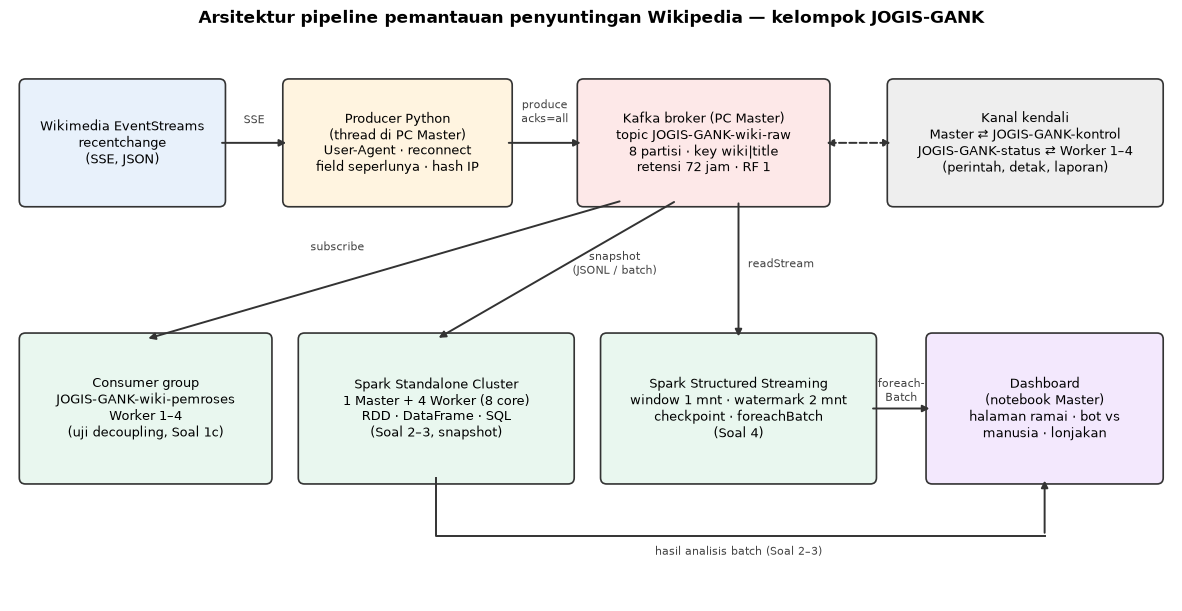

,Keputusan,Nilai,Alasan
0,Nama topic,JOGIS-GANK-wiki-raw,Awalan kelompok mencegah tabrakan dengan kelompok lain di broker yang sama; akhiran 'r...
1,Jumlah partisi,8,Sama dengan total core executor (4 Worker × 2 core): satu batch Kafka langsung menjadi...
2,Key pesan,wiki|title,Suntingan halaman yang sama selalu masuk partisi yang sama (urutan per halaman terjaga...
3,Replikasi,1,Lab hanya memiliki 1 broker dan faktor replikasi tidak boleh melebihi jumlah broker. R...
4,Retensi,72 jam (retention.ms=259200000),"Cukup untuk mengumpulkan ≥200.000 pesan, mengulang snapshot, dan menjalankan ulang str..."
5,Consumer group,JOGIS-GANK-wiki-pemroses (4 Worker); Spark menyimpan offset di checkpoint,"Dalam satu group, tiap partisi dibaca tepat satu Worker (pembagian kerja + failover sa..."
6,Kompresi & keandalan producer,"lz4, acks=all, enable.idempotence=true",lz4 menghemat jaringan dengan CPU rendah; acks=all + idempotence mencegah pesan hilang...


In [9]:
# ===== SOAL 1a: Diagram arsitektur + tabel keputusan desain =====
from matplotlib.patches import FancyBboxPatch

def gambar_arsitektur():
    fig, ax = plt.subplots(figsize=(15, 7.4))
    ax.set_xlim(0, 15); ax.set_ylim(0, 7.4); ax.axis("off")
    def kotak(x, y, w, h, teks, warna):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.08", fc=warna, ec="#333333", lw=1.2))
        ax.text(x + w / 2, y + h / 2, teks, ha="center", va="center", fontsize=9)
    def panah(x1, y1, x2, y2, teks=None, gaya="-|>", garis="-", dx=0.0, dy=0.22):
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                    arrowprops=dict(arrowstyle=gaya, lw=1.4, color="#333333", linestyle=garis))
        if teks:
            ax.text((x1 + x2) / 2 + dx, (y1 + y2) / 2 + dy, teks, ha="center", va="bottom", fontsize=8, color="#444444")
    kotak(0.2, 5.2, 2.5, 1.5, "Wikimedia EventStreams\nrecentchange\n(SSE, JSON)", "#E8F1FB")
    kotak(3.6, 5.2, 2.8, 1.5, "Producer Python\n(thread di PC Master)\nUser-Agent · reconnect\nfield seperlunya · hash IP", "#FFF4E0")
    kotak(7.4, 5.2, 3.1, 1.5, f"Kafka broker (PC Master)\ntopic {TOPIC_RAW}\n{PARTISI_RAW} partisi · key wiki|title\nretensi {RETENSI_JAM} jam · RF 1", "#FDE8E8")
    kotak(11.4, 5.2, 3.4, 1.5, f"Kanal kendali\nMaster ⇄ {TOPIC_KONTROL}\n{TOPIC_STATUS} ⇄ Worker 1–{N_WORKER}\n(perintah, detak, laporan)", "#EEEEEE")
    kotak(0.2, 1.6, 3.1, 1.8, f"Consumer group\n{GROUP_UJI}\nWorker 1–{N_WORKER}\n(uji decoupling, Soal 1c)", "#E9F7EF")
    kotak(3.8, 1.6, 3.4, 1.8, f"Spark Standalone Cluster\n1 Master + {N_WORKER} Worker ({TOTAL_CORE} core)\nRDD · DataFrame · SQL\n(Soal 2–3, snapshot)", "#E9F7EF")
    kotak(7.7, 1.6, 3.4, 1.8, "Spark Structured Streaming\nwindow 1 mnt · watermark 2 mnt\ncheckpoint · foreachBatch\n(Soal 4)", "#E9F7EF")
    kotak(11.9, 1.6, 2.9, 1.8, "Dashboard\n(notebook Master)\nhalaman ramai · bot vs\nmanusia · lonjakan", "#F3E8FD")
    panah(2.7, 5.95, 3.6, 5.95, "SSE")
    panah(6.4, 5.95, 7.4, 5.95, "produce\nacks=all")
    panah(10.5, 5.95, 11.4, 5.95, gaya="<|-|>", garis="--")
    panah(7.9, 5.2, 1.75, 3.4, "subscribe", dx=-0.6)
    panah(8.6, 5.2, 5.5, 3.4, "snapshot\n(JSONL / batch)", dx=0.75, dy=-0.1)
    panah(9.4, 5.2, 9.4, 3.4, "readStream", dx=0.55, dy=0.0)
    panah(11.1, 2.5, 11.9, 2.5, "foreach-\nBatch", dy=0.05)
    ax.plot([5.5, 5.5, 13.35], [1.6, 0.85, 0.85], color="#333333", lw=1.4)
    panah(13.35, 0.85, 13.35, 1.6)
    ax.text(9.4, 0.6, "hasil analisis batch (Soal 2–3)", ha="center", fontsize=8, color="#444444")
    ax.set_title(f"Arsitektur pipeline pemantauan penyuntingan Wikipedia — kelompok {KELOMPOK}", fontsize=12, fontweight="bold")
    return fig

fig = gambar_arsitektur()
print("Diagram disimpan:", simpan_grafik(fig, "1a_arsitektur"))
plt.show()

KEPUTUSAN = pd.DataFrame([
    ("Nama topic", TOPIC_RAW,
     "Awalan kelompok mencegah tabrakan dengan kelompok lain di broker yang sama; akhiran 'raw' menandai data mentah sebelum diolah."),
    ("Jumlah partisi", PARTISI_RAW,
     f"Sama dengan total core executor ({N_WORKER} Worker × {CORE_PER_WORKER} core): satu batch Kafka langsung menjadi "
     f"{PARTISI_RAW} task paralel dan habis dibagi {N_WORKER} consumer ({PARTISI_RAW // N_WORKER} partisi per Worker). Partisi bisa ditambah, tidak bisa dikurangi."),
    ("Key pesan", "wiki|title",
     "Suntingan halaman yang sama selalu masuk partisi yang sama (urutan per halaman terjaga, berguna untuk deteksi edit war), "
     "sementara beban tersebar karena jumlah halaman sangat banyak. Duplikat akibat reconnect SSE memiliki key sama sehingga jatuh di partisi yang sama."),
    ("Replikasi", 1,
     "Lab hanya memiliki 1 broker dan faktor replikasi tidak boleh melebihi jumlah broker. Risiko: jika PC Master mati, data tidak tersedia (keterbatasan)."),
    ("Retensi", f"{RETENSI_JAM} jam (retention.ms={RETENSI_JAM * 3600 * 1000})",
     "Cukup untuk mengumpulkan ≥200.000 pesan, mengulang snapshot, dan menjalankan ulang streaming selama masa ujian tanpa memenuhi disk PC Master."),
    ("Consumer group", f"{GROUP_UJI} (4 Worker); Spark menyimpan offset di checkpoint",
     "Dalam satu group, tiap partisi dibaca tepat satu Worker (pembagian kerja + failover saat Worker mati). "
     "Spark Structured Streaming tidak memakai commit group; offset dicatat di checkpointLocation."),
    ("Kompresi & keandalan producer", "lz4, acks=all, enable.idempotence=true",
     "lz4 menghemat jaringan dengan CPU rendah; acks=all + idempotence mencegah pesan hilang atau ganda dari sisi producer."),
], columns=["Keputusan", "Nilai", "Alasan"])
display(KEPUTUSAN)
bukti("1a_tabel_keputusan_desain", KEPUTUSAN)
_ = (BUKTI_DIR / "1a_tabel_keputusan_desain.md").write_text(tabel_md(KEPUTUSAN), encoding="utf-8")

**Risiko data skew bila key = `wiki`:** partisi ditentukan oleh `hash(key) % jumlah_partisi`, sehingga semua event dari satu wiki
masuk ke satu partisi. Karena `wikidatawiki` dan `enwiki` (ditambah `commonswiki`) menyumbang porsi besar aliran, partisi tempat
wiki tersebut jatuh menjadi *hot partition*: satu consumer/task Spark bekerja jauh lebih berat, sementara partisi lain nyaris kosong.
Akibatnya paralelisme semu, lag menumpuk di satu partisi, dan task Spark yang lambat (straggler) menahan seluruh stage.
Key `wiki|title` menyebar beban ke banyak halaman. Bukti kuantitatifnya ada di sel **1a (lanjutan)** setelah data terkumpul.

## 1b · Producer Python: SSE → Kafka
Producer berjalan di **thread latar** agar notebook tetap bisa dipakai. Fitur: header User-Agent deskriptif, reconnect
otomatis dengan backoff eksponensial dan `Last-Event-ID`, hanya field yang diperlukan, user anonim (IP / akun sementara)
disamarkan dengan HMAC-SHA256, event *canary* dibuang, key `wiki|title`, `acks=all`, idempotence, dan kompresi lz4.

In [10]:
# ===== SOAL 1b: Kelas producer SSE -> Kafka =====
POLA_AKUN_SEMENTARA = re.compile(r"^~\d{4}-\d+(-\d+)?$")       # akun sementara pengganti IP (mis. ~2026-12345-67)

def samarkan(user):
    """(user_tersamar, anon). IP & akun sementara -> 'anon-<12 hex HMAC>'. HMAC + kunci rahasia: hash IPv4 tidak bisa ditebak ulang."""
    if not user:
        return user, False
    try:
        ipaddress.ip_address(user); anon = True
    except ValueError:
        anon = bool(POLA_AKUN_SEMENTARA.match(user))
    if not anon:
        return user, False
    return "anon-" + hmac.new(SALT_HASH.encode(), user.encode(), hashlib.sha256).hexdigest()[:12], True

def ringkas_event(e):
    """Ambil hanya field yang diperlukan analisis. None = event dibuang."""
    meta = e.get("meta") or {}
    if meta.get("domain") == "canary" or not e.get("wiki") or e.get("title") is None:
        return None
    user, anon = samarkan(e.get("user"))
    pjg = e.get("length") or {}
    return {"id": e.get("id"), "type": e.get("type"), "wiki": e.get("wiki"), "server_name": e.get("server_name"),
            "title": e.get("title"), "namespace": e.get("namespace"), "user": user, "anon": anon,
            "bot": bool(e.get("bot")), "minor": e.get("minor"), "timestamp": e.get("timestamp"),
            "length": {"old": pjg.get("old"), "new": pjg.get("new")},
            "comment": (e.get("comment") or "")[:300], "meta_id": meta.get("id")}

WIKI_SIMULASI = [("wikidatawiki", 38), ("commonswiki", 17), ("enwiki", 15), ("dewiki", 4), ("idwiki", 4), ("frwiki", 3),
                 ("eswiki", 3), ("jawiki", 2), ("ruwiki", 2), ("itwiki", 2), ("zhwiki", 2), ("jvwiki", 1), ("arwiki", 1)]

class ProdusenWiki:
    def __init__(self):
        self.stat = Counter()
        self.galat, self.last_id, self.t_mulai = [], None, None
        self._henti = threading.Event()
        self._t = None
        self.p = Producer({"bootstrap.servers": BOOTSTRAP, "acks": "all", "enable.idempotence": True,
                           "compression.type": "lz4", "linger.ms": 50, "partitioner": "murmur2_random",
                           "queue.buffering.max.messages": 500000, "client.id": f"{KELOMPOK}-produsen-sse"})

    # --- pengiriman ---
    def _hasil(self, err, msg):
        if err is not None:
            self.stat["gagal_kirim"] += 1; self._catat_galat(f"kirim: {err}")
        else:
            self.stat["terkirim"] += 1

    def _kirim(self, e):
        r = ringkas_event(e)
        if r is None:
            self.stat["dibuang"] += 1; return
        key = f"{r['wiki']}|{r['title']}".encode("utf-8")
        val = json.dumps(r, separators=(",", ":"), ensure_ascii=False).encode("utf-8")
        while True:
            try:
                self.p.produce(TOPIC_RAW, key=key, value=val, on_delivery=self._hasil); break
            except BufferError:                        # antrean lokal penuh: tunggu sebentar
                self.p.poll(0.5)
        self.stat["diproduksi"] += 1
        self.p.poll(0)

    def _catat_galat(self, teks):
        self.galat.append((time.strftime("%H:%M:%S"), teks))
        del self.galat[:-200]

    # --- sumber SSE ---
    def _baca_sse(self):
        hdr = {"User-Agent": USER_AGENT, "Accept": "text/event-stream", "Cache-Control": "no-cache"}
        if self.last_id:
            hdr["Last-Event-ID"] = self.last_id          # lanjut dari event terakhir setelah putus
        req = urllib.request.Request(URL_SSE, headers=hdr)
        with urllib.request.urlopen(req, timeout=TIMEOUT_BACA) as resp:
            self.stat["koneksi"] += 1
            data, eid = [], None
            for raw in resp:
                if self._henti.is_set():
                    return
                baris = raw.decode("utf-8", "replace").rstrip("\r\n")
                if baris == "":                            # baris kosong = akhir satu event
                    if data:
                        if eid:
                            self.last_id = eid
                        try:
                            self._kirim(json.loads("\n".join(data)))
                        except ValueError:
                            self.stat["json_rusak"] += 1
                    data, eid = [], None
                    continue
                if baris.startswith(":"):                  # komentar / heartbeat server
                    continue
                kolom, _, nilai = baris.partition(":")
                nilai = nilai[1:] if nilai.startswith(" ") else nilai
                if kolom == "data":
                    data.append(nilai)
                elif kolom == "id":
                    eid = nilai
        raise ConnectionError("server menutup aliran")

    def _baca_file(self):
        with open(FILE_CADANGAN, encoding="utf-8") as f:
            for baris in f:
                if self._henti.is_set():
                    return
                baris = baris.strip()
                if baris.startswith("data:"):
                    baris = baris[5:].strip()
                if not baris.startswith("{"):
                    continue
                try:
                    self._kirim(json.loads(baris))
                except ValueError:
                    self.stat["json_rusak"] += 1
        self._henti.set()

    def _simulasi(self, laju=50.0):
        nama, bobot = zip(*WIKI_SIMULASI)
        rc = Counter()
        while not self._henti.is_set():
            w = random.choices(nama, weights=bobot)[0]; rc[w] += 1
            bot = random.random() < (0.5 if w == "wikidatawiki" else 0.15)
            tipe = random.choices(["edit", "new", "log", "categorize"], weights=[74, 5, 9, 12])[0]
            u = f"10.{random.randint(0, 255)}.{random.randint(0, 255)}.{random.randint(1, 254)}" if random.random() < 0.05 else f"User{random.randint(1, 500)}"
            lama = random.randint(100, 50000) if tipe == "edit" else None
            self._kirim({"meta": {"domain": "simulasi", "id": str(uuid.uuid4())}, "id": 10**6 + rc[w], "type": tipe, "wiki": w,
                         "server_name": f"{w}.simulasi", "title": f"Halaman {random.randint(1, 3000 if w == 'idwiki' else 20000)}",
                         "namespace": 0, "user": u, "bot": bot, "minor": False, "timestamp": int(time.time()),
                         "length": {"old": lama, "new": (lama or 0) + random.randint(-500, 1500)} if tipe in ("edit", "new") else None,
                         "comment": random.choice(["memperbaiki ejaan", "menambah kategori", "pembaruan data", "Membuat halaman berisi"])})
            time.sleep(random.expovariate(laju))

    # --- loop dengan reconnect ---
    def _loop(self):
        jeda = 1
        while not self._henti.is_set():
            n0 = self.stat["diproduksi"]
            try:
                {"sse": self._baca_sse, "file": self._baca_file, "simulasi": self._simulasi}[MODE_SUMBER]()
            except urllib.error.HTTPError as e:
                self._catat_galat(f"HTTP {e.code} {e.reason}")
                if e.code == 429:
                    jeda = max(jeda, 15)
            except Exception as e:
                self._catat_galat(f"{e.__class__.__name__}: {str(e)[:120]}")
            if self._henti.is_set():
                break
            if self.stat["diproduksi"] > n0:
                jeda = 1                                    # koneksi tadi sempat menghasilkan data
            self.stat["reconnect"] += 1
            self._henti.wait(jeda)
            jeda = min(jeda * 2, 60)
        self.p.flush(30)

    def mulai(self):
        if self._t and self._t.is_alive():
            print("Producer sudah berjalan."); return self
        self._henti.clear(); self.t_mulai = time.time()
        self._t = threading.Thread(target=self._loop, daemon=True, name="produsen-sse"); self._t.start()
        return self

    def berhenti(self):
        self._henti.set()
        if self._t:
            self._t.join(40)
        self.p.flush(30)

    def ringkas(self):
        dur = time.time() - (self.t_mulai or time.time())
        return {"berjalan": bool(self._t and self._t.is_alive()), "menit": round(dur / 60, 2), **self.stat,
                "laju_rata": round(self.stat["terkirim"] / dur, 2) if dur > 0 else 0, "galat_terakhir": self.galat[-1:] }

print("Kelas producer siap. Mode sumber:", MODE_SUMBER, "|", URL_SSE if MODE_SUMBER == "sse" else FILE_CADANGAN)
if MODE_SUMBER == "simulasi":
    print("PERINGATAN: mode simulasi hanya untuk uji alur; laporan UTS wajib memakai data EventStreams (atau cadangan dosen).")

Kelas producer siap. Mode sumber: sse | https://stream.wikimedia.org/v2/stream/recentchange


In [11]:
# ===== SOAL 1b: Jalankan producer (latar) + monitor minimal 10 menit =====
if "produsen" in globals() and produsen.ringkas()["berjalan"]:
    print("Producer sebelumnya masih berjalan, dipakai terus.")
else:
    produsen = ProdusenWiki().mulai()

def pantau_producer(menit=DURASI_PRODUCER_MENIT, jeda=10):
    """Tampilkan progres sampai producer berjalan >= `menit`. Producer TIDAK dihentikan setelah sel ini selesai."""
    log_baris = []
    t_sebelum, n_sebelum = time.time(), total_pesan()
    try:
        while (time.time() - produsen.t_mulai) < menit * 60:
            time.sleep(jeda)
            wm = watermark(); n = total_pesan(wm); t = time.time()
            laju = (n - n_sebelum) / (t - t_sebelum); t_sebelum, n_sebelum = t, n
            s = produsen.ringkas()
            log_baris.append(f"{time.strftime('%H:%M:%S')} | menit {s['menit']:5.2f} | terkirim {s.get('terkirim', 0):>8,} | "
                             f"di topic {n:>8,} | laju {laju:6.1f} pesan/dtk | dibuang {s.get('dibuang', 0):>5} | "
                             f"reconnect {s.get('reconnect', 0)} | gagal {s.get('gagal_kirim', 0)}")
            clear_output(wait=True)
            print(f"PRODUCER {URL_SSE if MODE_SUMBER == 'sse' else MODE_SUMBER} -> {TOPIC_RAW}  (target monitor {menit} menit)")
            print("\n".join(log_baris[-18:]))
            print("\nOffset tiap partisi (low → high):", {p: f"{lo}→{hi}" for p, (lo, hi) in wm.items()})
            if s["galat_terakhir"]:
                print("Galat terakhir:", s["galat_terakhir"][0])
    except KeyboardInterrupt:
        print("Monitor dihentikan (producer tetap berjalan).")
    bukti("1b_log_producer", "\n".join(log_baris))
    return log_baris

_log = pantau_producer()
print("\nRingkasan producer:", {k: v for k, v in produsen.ringkas().items() if k != "galat_terakhir"})

PRODUCER https://stream.wikimedia.org/v2/stream/recentchange -> JOGIS-GANK-wiki-raw  (target monitor 10 menit)
00:40:06 | menit  7.18 | terkirim   16,434 | di topic  371,464 | laju   34.8 pesan/dtk | dibuang     0 | reconnect 0 | gagal 0
00:40:16 | menit  7.34 | terkirim   16,945 | di topic  371,976 | laju   51.1 pesan/dtk | dibuang     0 | reconnect 0 | gagal 0
00:40:26 | menit  7.51 | terkirim   17,334 | di topic  372,373 | laju   39.6 pesan/dtk | dibuang     0 | reconnect 0 | gagal 0
00:40:36 | menit  7.68 | terkirim   17,796 | di topic  372,837 | laju   46.3 pesan/dtk | dibuang     0 | reconnect 0 | gagal 0
00:40:46 | menit  7.84 | terkirim   18,235 | di topic  373,281 | laju   44.3 pesan/dtk | dibuang     0 | reconnect 0 | gagal 0
00:40:56 | menit  8.01 | terkirim   18,624 | di topic  373,660 | laju   37.8 pesan/dtk | dibuang     0 | reconnect 0 | gagal 0
00:41:06 | menit  8.18 | terkirim   19,037 | di topic  374,065 | laju   40.4 pesan/dtk | dibuang     0 | reconnect 0 | gagal 0


In [12]:
# ===== SOAL 1b: Bukti Kafka - jumlah pesan, laju (pesan/detik), offset tiap partisi =====
def bukti_offset(jeda_ukur=60):
    wm1, t1 = watermark(), time.time()
    time.sleep(jeda_ukur)
    wm2, t2 = watermark(), time.time()
    df = pd.DataFrame([{"partisi": p, "offset_awal (low)": wm2[p][0], "offset_akhir (high)": wm2[p][1],
                        "jumlah_pesan": wm2[p][1] - wm2[p][0], f"bertambah_{jeda_ukur}dtk": wm2[p][1] - wm1.get(p, (0, 0))[1],
                        "laju_pesan_per_dtk": round((wm2[p][1] - wm1.get(p, (0, 0))[1]) / (t2 - t1), 2)} for p in sorted(wm2)])
    return df, (t2 - t1)

def perintah_cli_kafka(grup=None):
    ext, sub = (".bat", "windows") if os.name == "nt" else (".sh", "")
    b = (Path(KAFKA_HOME) / "bin" / sub) if KAFKA_HOME else Path("<KAFKA_HOME>/bin") / sub
    cmd = {"describe topic": [str(b / f"kafka-topics{ext}"), "--bootstrap-server", BOOTSTRAP, "--describe", "--topic", TOPIC_RAW],
           "offset tiap partisi": [str(b / f"kafka-get-offsets{ext}"), "--bootstrap-server", BOOTSTRAP, "--topic", TOPIC_RAW],
           "offset (Kafka lama)": [str(b / f"kafka-run-class{ext}"), "kafka.tools.GetOffsetShell", "--bootstrap-server", BOOTSTRAP,
                                   "--topic", TOPIC_RAW, "--time", "-1"],
           "contoh pesan": [str(b / f"kafka-console-consumer{ext}"), "--bootstrap-server", BOOTSTRAP, "--topic", TOPIC_RAW,
                            "--from-beginning", "--max-messages", "3", "--property", "print.key=true",
                            "--property", "print.partition=true", "--property", "print.offset=true"]}
    if grup:
        cmd["consumer group"] = [str(b / f"kafka-consumer-groups{ext}"), "--bootstrap-server", BOOTSTRAP, "--describe", "--group", grup]
    return cmd

def jalankan_cli_kafka(grup=None, nama_bukti="1b_cli_kafka"):
    with catat(nama_bukti):
        for judul, c in perintah_cli_kafka(grup).items():
            print(f"\n$ {' '.join(c)}")
            if not KAFKA_HOME:
                continue
            if not Path(c[0]).exists():
                print("  (skrip tidak ada di versi Kafka ini)"); continue
            try:
                r = subprocess.run(c, capture_output=True, text=True, timeout=60)
                print((r.stdout or "") + (r.stderr or "")[-1500:])
            except Exception as e:
                print("  gagal:", e)
        if not KAFKA_HOME:
            print("\nKAFKA_HOME belum diisi: jalankan perintah di atas di terminal PC Master lalu ambil tangkapan layar.")

with catat("1b_offset_dan_laju"):
    df_off, dur = bukti_offset(60)
    tot = int(df_off["jumlah_pesan"].sum())
    umur = time.time() - produsen.t_mulai
    print(f"Topic {TOPIC_RAW} | {len(df_off)} partisi | jumlah pesan = {tot:,}")
    print(f"Laju terukur dari offset ({dur:.0f} dtk): {df_off[df_off.columns[4]].sum() / dur:.2f} pesan/dtk")
    print(f"Laju rata-rata sejak producer mulai ({umur / 60:.1f} menit): {produsen.stat['terkirim'] / umur:.2f} pesan/dtk")
    print(df_off.to_string(index=False))
    print("\nStatistik producer:", {k: v for k, v in produsen.ringkas().items() if k != "galat_terakhir"})
bukti("1b_offset_partisi", df_off)
jalankan_cli_kafka()
RINGKASAN["1b"] = {"pesan": tot, "laju_offset": round(df_off[df_off.columns[4]].sum() / dur, 2),
                   "menit_producer": round(umur / 60, 1), "reconnect": produsen.stat["reconnect"], "dibuang": produsen.stat["dibuang"]}

Topic JOGIS-GANK-wiki-raw | 8 partisi | jumlah pesan = 385,910
Laju terukur dari offset (60 dtk): 39.73 pesan/dtk
Laju rata-rata sejak producer mulai (13.0 menit): 39.70 pesan/dtk
 partisi  offset_awal (low)  offset_akhir (high)  jumlah_pesan  bertambah_60dtk  laju_pesan_per_dtk
       0                  0                46251         46251              295                4.92
       1                  0                50267         50267              393                6.55
       2                  0                45853         45853              288                4.80
       3                  0                46309         46309              288                4.80
       4                  0                46472         46472              264                4.40
       5                  0                54561         54561              356                5.93
       6                  0                48534         48534              238                3.97
       7            

## 1a (lanjutan) · Bukti kuantitatif risiko skew bila key = `wiki`
Mengambil sampel pesan terbaru, lalu menghitung partisi tujuan dengan partitioner murmur2 (sama dengan Java/Spark) untuk
key `wiki` dibanding key yang dipakai (`wiki|title`). Ketepatan fungsi hash dicek terhadap partisi asli setiap pesan.

Sampel 60,000 pesan terbaru dari 8 partisi. Cek murmur2: 60,000/60,000 (100.00%) sama dengan partisi asli.

Porsi 8 wiki teratas:
  commonswiki       19,632  ( 32.7%)
  wikidatawiki      11,091  ( 18.5%)
  enwiki             7,389  ( 12.3%)
  kaawiki            4,888  (  8.1%)
  elwiktionary       3,006  (  5.0%)
  arwiki             1,156  (  1.9%)
  frwiki               888  (  1.5%)
  ruwiki               859  (  1.4%)

Keseimbangan beban partisi (ideal: maks/rata-rata = 1, koef_variasi = 0):
                                  maks/rata-rata  min/rata-rata  koef_variasi  partisi_terberat_%
key = wiki (simulasi)                       4.51           0.13          1.38                56.3
key = wiki|title (simulasi)                 1.00           1.00          0.00                12.5
key = wiki|title (asli di topic)            1.00           1.00          0.00                12.5


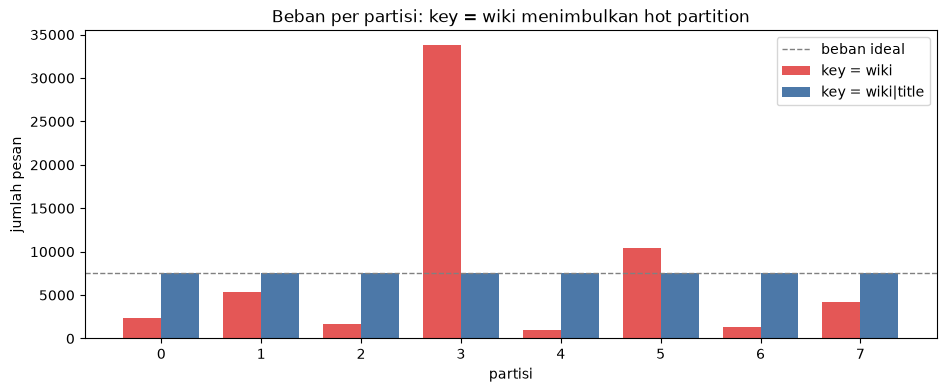

In [13]:
# ===== SOAL 1a (lanjutan): Analisis skew partisi =====
def murmur2(data):
    """Implementasi murmur2 Kafka (Java Utils.murmur2) -> bilangan 32-bit."""
    m, r, panjang = 0x5BD1E995, 24, len(data)
    h = (0x9747B28C ^ panjang) & 0xFFFFFFFF
    for i in range(panjang // 4):
        k = int.from_bytes(data[4 * i:4 * i + 4], "little")
        k = (k * m) & 0xFFFFFFFF; k ^= k >> r; k = (k * m) & 0xFFFFFFFF
        h = (h * m) & 0xFFFFFFFF; h ^= k
    sisa, idx = panjang % 4, panjang & ~3
    if sisa == 3: h ^= data[idx + 2] << 16
    if sisa >= 2: h ^= data[idx + 1] << 8
    if sisa >= 1:
        h ^= data[idx]; h = (h * m) & 0xFFFFFFFF
    h ^= h >> 13; h = (h * m) & 0xFFFFFFFF; h ^= h >> 15
    return h

def partisi_murmur2(key_bytes, n):
    return (murmur2(key_bytes) & 0x7FFFFFFF) % n

def sampel_terbaru(n_maks=60000):
    wm = watermark(); P = len(wm)
    rentang = {p: (max(lo, hi - n_maks // P), hi) for p, (lo, hi) in wm.items()}
    data = []
    baca_rentang(rentang, lambda m: data.append((m.partition(), m.key(), json.loads(m.value()))))
    return data, P

sampel, P = sampel_terbaru()
cocok = sum(partisi_murmur2(k, P) == p for p, k, _ in sampel)
jml_wiki = Counter(d["wiki"] for _, _, d in sampel)
beban_wiki, beban_judul, beban_asli = Counter(), Counter(), Counter(p for p, _, _ in sampel)
for p, k, d in sampel:
    beban_wiki[partisi_murmur2(d["wiki"].encode("utf-8"), P)] += 1
    beban_judul[partisi_murmur2(k, P)] += 1

def statistik(beban):
    v = [beban.get(p, 0) for p in range(P)]
    rata = sum(v) / P
    sd = (sum((x - rata) ** 2 for x in v) / P) ** 0.5
    return {"maks/rata-rata": round(max(v) / rata, 2), "min/rata-rata": round(min(v) / rata, 2), "koef_variasi": round(sd / rata, 3),
            "partisi_terberat_%": round(100 * max(v) / sum(v), 1)}

with catat("1a_bukti_skew"):
    print(f"Sampel {len(sampel):,} pesan terbaru dari {P} partisi. Cek murmur2: {cocok:,}/{len(sampel):,} "
          f"({100 * cocok / max(len(sampel), 1):.2f}%) sama dengan partisi asli.")
    print("\nPorsi 8 wiki teratas:")
    for w, n in jml_wiki.most_common(8):
        print(f"  {w:<16} {n:>7,}  ({100 * n / len(sampel):5.1f}%)")
    banding = pd.DataFrame({"key = wiki (simulasi)": statistik(beban_wiki), "key = wiki|title (simulasi)": statistik(beban_judul),
                            "key = wiki|title (asli di topic)": statistik(beban_asli)}).T
    print("\nKeseimbangan beban partisi (ideal: maks/rata-rata = 1, koef_variasi = 0):")
    print(banding.to_string())
bukti("1a_bukti_skew_tabel", banding.reset_index().rename(columns={"index": "skema_key"}))

fig, ax = plt.subplots(figsize=(11, 4))
x = range(P); w = 0.38
ax.bar([i - w / 2 for i in x], [beban_wiki.get(i, 0) for i in x], w, label="key = wiki", color="#E45756")
ax.bar([i + w / 2 for i in x], [beban_judul.get(i, 0) for i in x], w, label="key = wiki|title", color="#4C78A8")
ax.axhline(len(sampel) / P, ls="--", color="gray", lw=1, label="beban ideal")
ax.set(title="Beban per partisi: key = wiki menimbulkan hot partition", xlabel="partisi", ylabel="jumlah pesan")
ax.set_xticks(list(x)); ax.legend()
simpan_grafik(fig, "1a_skew_partisi"); plt.show()
RINGKASAN["1a_skew"] = banding.to_dict()

## 1c · Uji decoupling (consumer dihentikan ±2 menit, producer tetap jalan)
Consumer = 4 Worker dalam satu consumer group (commit manual setelah diproses, *at-least-once*). Master memberi perintah lewat
`k1-kontrol`: **jalan → berhenti ±2 menit → lanjut → berhenti**. Setiap Worker mencatat *ledger* offset yang diproses, lalu Master
menghitung pesan hilang (offset yang tidak pernah diproses) dan pesan ganda (offset yang diproses lebih dari sekali).

In [14]:
# ===== SOAL 1c: Fungsi bantu uji decoupling =====
def tabel_lag(grup):
    wm, com = watermark(), offset_grup(grup)
    return pd.DataFrame([{"partisi": p, "committed": com.get(p, -1001), "log_end": hi,
                          "lag": hi - (com[p] if com.get(p, -1) >= 0 else lo)} for p, (lo, hi) in sorted(wm.items())])

def laporan_konsumen(sesi, jenis=None):
    with pemantau.lock:
        return [(w, d) for w, daftar in pemantau.konsumen.items() for d in daftar
                if d.get("sesi") == sesi and (jenis is None or d.get("jenis") == jenis)]

def hentikan_konsumen(sesi, crash=False):
    """Penghentian dua fase: (1) JEDA = semua Worker berhenti memproses & commit selagi group stabil, (2) STOP = keluar dari group.
    Tanpa fase 1, Worker yang keluar duluan memicu rebalance sehingga commit Worker lain ditolak (REBALANCE_IN_PROGRESS) -> pesan ganda."""
    if not crash:
        kirim_kontrol("KONSUMEN_JEDA", sesi=sesi)
        tunggu_konsumen(sesi, "konsumen_dijeda", timeout=60)
    kirim_kontrol("KONSUMEN_STOP", sesi=sesi, crash=crash)
    return tunggu_konsumen(sesi, "konsumen_selesai", timeout=60)

def tunggu_konsumen(sesi, jenis, n=N_WORKER, timeout=60):
    t0 = time.time()
    while time.time() - t0 < timeout:
        if len({w for w, _ in laporan_konsumen(sesi, jenis)}) >= n:
            return True
        time.sleep(0.5)
    return False

def pantau_lag(grup, detik, judul, jeda=10):
    riwayat, t0 = [], time.time()
    while True:
        df = tabel_lag(grup)
        riwayat.append({"detik": round(time.time() - t0), "total_lag": int(df["lag"].sum()), "log_end": int(df["log_end"].sum())})
        clear_output(wait=True)
        print(f"[{judul}] {time.time() - t0:5.0f}/{detik} dtk | total lag = {int(df['lag'].sum()):,} | total log_end = {int(df['log_end'].sum()):,}")
        print(df.to_string(index=False))
        if time.time() - t0 >= detik:
            return riwayat
        time.sleep(min(jeda, max(0.5, detik - (time.time() - t0))))

def gabung_cakupan(ledgers, p):
    """Hitung berapa kali tiap offset diproses (sweep line atas rentang [a, b] dari semua Worker & sesi)."""
    ev = []
    for led in ledgers:
        for a, b in led.get(str(p), []):
            ev += [(a, 1), (b + 1, -1)]
    ev.sort()
    seg, cak, prev = [], 0, None
    for pos, d in ev:
        if prev is not None and pos > prev:
            seg.append((prev, pos - 1, cak))
        cak += d; prev = pos
    return seg                                          # [(awal, akhir, cakupan)]

def analisis_hilang_ganda(ledgers, awal, akhir):
    rows = []
    for p in sorted(akhir):
        seg = gabung_cakupan(ledgers, p)
        a0, b0 = awal[p], akhir[p]
        diproses = sum((min(b, b0 - 1) - max(a, a0) + 1) * c for a, b, c in seg if b >= a0 and a < b0)
        ganda = sum((min(b, b0 - 1) - max(a, a0) + 1) * (c - 1) for a, b, c in seg if c > 1 and b >= a0 and a < b0)
        tertutup = sum(min(b, b0 - 1) - max(a, a0) + 1 for a, b, c in seg if c > 0 and b >= a0 and a < b0)
        rows.append({"partisi": p, "rentang_uji": f"[{a0}, {b0})", "pesan_seharusnya": b0 - a0, "diproses_total": diproses,
                     "hilang": (b0 - a0) - tertutup, "ganda": ganda})
    return pd.DataFrame(rows)

def efektif(com, wm):
    """Offset ter-commit; -1001 (belum pernah commit) diganti offset awal partisi."""
    return {p: (o if o >= 0 else wm[p][0]) for p, o in com.items()}

def ambil_ledger(grup, n=N_WORKER, timeout=40):
    cid = kirim_kontrol("LAPORAN_LEDGER", group=grup)
    b = pemantau.tunggu_balasan(cid, n, timeout)
    return [lg for d in b.values() for lg in d.get("ledger", {}).values()], b

def kunci_dedup(d):
    return f"{d.get('wiki')}:{d['id']}" if d.get("id") is not None else f"{d.get('wiki')}:uuid:{d.get('meta_id')}"

def dedup_dari_ledger(ledgers, awal, akhir):
    """Pemrosesan idempoten: hitung berapa event UNIK (kunci wiki+id) di antara semua pemrosesan (termasuk ganda)."""
    kunci_offset = {}
    baca_rentang({p: (awal[p], akhir[p]) for p in akhir}, lambda m: kunci_offset.__setitem__((m.partition(), m.offset()), kunci_dedup(json.loads(m.value()))))
    total, unik = 0, set()
    for p in akhir:
        for a, b, c in gabung_cakupan(ledgers, p):
            for o in range(max(a, awal[p]), min(b, akhir[p] - 1) + 1):
                k = kunci_offset.get((p, o))
                if k is not None:
                    total += c; unik.add(k)
    return total, len(unik), len(kunci_offset)
print("Fungsi uji decoupling siap.")

Fungsi uji decoupling siap.


FASE C: consumer mengejar ketertinggalan ... lag = 20 (18 dtk)
Consumer group: JOGIS-GANK-wiki-pemroses-51bb3e | Worker yang mengirim ledger: ['rafaul-w1', 'rafaul-w2', 'rafaul-w3', 'rafaul-w4']
Lama consumer berhenti: 120 dtk (target 120 dtk); producer tetap mengirim selama itu

1) Consumer melanjutkan dari offset terakhir yang di-commit:
 partisi  committed_saat_berhenti  offset_pertama_setelah_lanjut  lanjut_tepat  menumpuk_selama_berhenti
       0                    46673                          46673          True                       626
       1                    50867                          50867          True                       750
       2                    46258                          46258          True                       594
       3                    46728                          46728          True                       633
       4                    46945                          46945          True                       564
       5                    

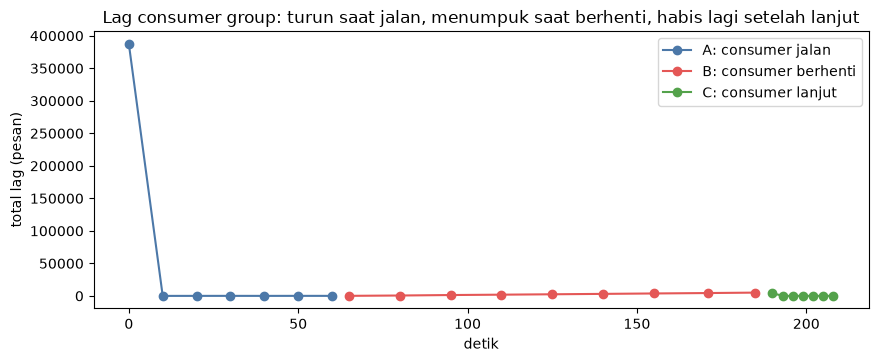

In [15]:
# ===== SOAL 1c: Jalankan uji decoupling =====
GRUP_1C = f"{GROUP_UJI}-{RUN_ID}"            # group baru agar uji bersih; dicatat untuk perintah kafka-consumer-groups
wm_awal = watermark()
awal_uji = {p: lo for p, (lo, hi) in wm_awal.items()}      # group baru + auto.offset.reset=earliest -> mulai dari offset paling awal
fase = {}

# Fase A: consumer berjalan
kirim_kontrol("KONSUMEN_MULAI", group=GRUP_1C, topic=TOPIC_RAW, sesi=1)
print("Menunggu 4 Worker bergabung ke group", GRUP_1C, "...", tunggu_konsumen(1, "assign", timeout=90))
fase["A_jalan"] = pantau_lag(GRUP_1C, DETIK_FASE_JALAN, "FASE A: consumer berjalan")

# Fase B: consumer dihentikan, producer tetap jalan
print("Menghentikan consumer (jeda + commit, lalu keluar group) ...", hentikan_konsumen(1))
time.sleep(2)
com_stop, wm_stop, t_stop = offset_grup(GRUP_1C), watermark(), time.time()
fase["B_berhenti"] = pantau_lag(GRUP_1C, DETIK_BERHENTI, "FASE B: consumer BERHENTI, producer tetap jalan", jeda=15)
wm_lanjut = watermark()

# Fase C: consumer dijalankan kembali dengan group yang sama
t_lanjut = time.time()
kirim_kontrol("KONSUMEN_MULAI", group=GRUP_1C, topic=TOPIC_RAW, sesi=2)
tunggu_konsumen(2, "assign", timeout=90)
t0, fase["C_lanjut"] = time.time(), []
while time.time() - t0 < DETIK_KEJAR:
    df_c = tabel_lag(GRUP_1C); lag = int(df_c["lag"].sum())
    fase["C_lanjut"].append({"detik": round(time.time() - t0), "total_lag": lag, "log_end": int(df_c["log_end"].sum())})
    clear_output(wait=True); print(f"FASE C: consumer mengejar ketertinggalan ... lag = {lag:,} ({time.time() - t0:.0f} dtk)")
    if lag < 50 and time.time() - t0 > 15:
        break
    time.sleep(3)
hentikan_konsumen(2)
time.sleep(2)
com_akhir = offset_grup(GRUP_1C)
ledgers, balasan_ledger = ambil_ledger(GRUP_1C)

with catat("1c_uji_decoupling"):
    print(f"Consumer group: {GRUP_1C} | Worker yang mengirim ledger: {sorted(balasan_ledger)}")
    print(f"Lama consumer berhenti: {t_lanjut - t_stop:.0f} dtk (target {DETIK_BERHENTI} dtk); producer tetap mengirim selama itu\n")
    # (1) lanjut dari offset terakhir
    pertama = {}
    for w, d in laporan_konsumen(2, "konsumen_selesai"):
        for p, o in d.get("offset_pertama", {}).items():
            pertama[int(p)] = min(o, pertama.get(int(p), o))
    cs = efektif(com_stop, wm_stop)
    df_lanjut = pd.DataFrame([{"partisi": p, "committed_saat_berhenti": cs[p], "offset_pertama_setelah_lanjut": pertama.get(p),
                               "lanjut_tepat": pertama.get(p) == cs[p] if pertama.get(p) is not None else "tidak ada pesan baru",
                               "menumpuk_selama_berhenti": wm_lanjut[p][1] - cs[p]} for p in sorted(cs)])
    print("1) Consumer melanjutkan dari offset terakhir yang di-commit:")
    print(df_lanjut.to_string(index=False))
    print(f"   Pesan yang menumpuk selama consumer berhenti: {int(df_lanjut['menumpuk_selama_berhenti'].sum()):,} "
          "(producer tidak terganggu = decoupling)\n")
    # (2) hilang / ganda
    akhir_uji = efektif(com_akhir, wm_awal)
    df_hg = analisis_hilang_ganda(ledgers, awal_uji, akhir_uji)
    print("2) Pesan hilang / ganda dalam rentang [offset awal, committed akhir):")
    print(df_hg.to_string(index=False))
    tot_hilang, tot_ganda = int(df_hg["hilang"].sum()), int(df_hg["ganda"].sum())
    print(f"   TOTAL: seharusnya {int(df_hg['pesan_seharusnya'].sum()):,} | diproses {int(df_hg['diproses_total'].sum()):,} | "
          f"hilang {tot_hilang} | ganda {tot_ganda}")
    gagal = {w: sum(d.get("commit_gagal", 0) for s in (1, 2) for w2, d in laporan_konsumen(s, "konsumen_selesai") if w2 == w)
             for w in sorted({w for s in (1, 2) for w, _ in laporan_konsumen(s, "konsumen_selesai")})}
    print(f"   Commit gagal per Worker (mis. REBALANCE_IN_PROGRESS): {gagal}")
    if tot_ganda:
        print("   Pesan ganda muncul karena ada pesan yang sudah diproses tetapi commit-nya gagal/terlambat saat rebalance,"
              " lalu dibaca ulang oleh pemilik partisi berikutnya: inilah sifat at-least-once.")
    # (3) pemrosesan tahan duplikat
    tot_proses, n_unik, n_pesan = dedup_dari_ledger(ledgers, awal_uji, akhir_uji)
    print(f"\n3) Pemrosesan idempoten dengan kunci wiki+id: {tot_proses:,} kali diproses -> {n_unik:,} event unik "
          f"(dari {n_pesan:,} offset; selisih offset vs kunci = duplikat dari sumber/reconnect SSE).")
bukti("1c_lanjut_dari_offset", df_lanjut); bukti("1c_hilang_ganda", df_hg)
bukti("1c_riwayat_lag", [{"fase": k, **r} for k, v in fase.items() for r in v])
jalankan_cli_kafka(GRUP_1C, "1c_cli_kafka_consumer_group")
RINGKASAN["1c"] = {"group": GRUP_1C, "hilang": tot_hilang, "ganda": tot_ganda, "diproses": tot_proses, "unik": n_unik,
                   "menumpuk_saat_berhenti": int(df_lanjut["menumpuk_selama_berhenti"].sum())}

fig, ax = plt.subplots(figsize=(10, 3.6))
mulai = 0
for nama_fase, warna, label in (("A_jalan", "#4C78A8", "A: consumer jalan"), ("B_berhenti", "#E45756", "B: consumer berhenti"),
                                 ("C_lanjut", "#54A24B", "C: consumer lanjut")):
    r = fase.get(nama_fase) or []
    if r:
        ax.plot([mulai + x["detik"] for x in r], [x["total_lag"] for x in r], marker="o", color=warna, label=label)
        mulai += r[-1]["detik"] + 5
ax.set(title="Lag consumer group: turun saat jalan, menumpuk saat berhenti, habis lagi setelah lanjut", xlabel="detik", ylabel="total lag (pesan)")
ax.legend(); simpan_grafik(fig, "1c_lag"); plt.show()

In [16]:
# ===== SOAL 1c (opsional): Simulasi crash - proses tanpa commit, lalu lanjut =====
JALANKAN_SIMULASI_CRASH = True
if JALANKAN_SIMULASI_CRASH:
    kirim_kontrol("KONSUMEN_MULAI", group=GRUP_1C, topic=TOPIC_RAW, sesi=3)
    tunggu_konsumen(3, "assign", timeout=90); time.sleep(10)
    kirim_kontrol("KONSUMEN_TAHAN_COMMIT")          # Worker tetap memproses tetapi berhenti commit
    time.sleep(15)
    hentikan_konsumen(3, crash=True)                     # "crash": keluar tanpa commit terakhir
    time.sleep(2)
    com_crash = offset_grup(GRUP_1C)
    kirim_kontrol("KONSUMEN_MULAI", group=GRUP_1C, topic=TOPIC_RAW, sesi=4)
    tunggu_konsumen(4, "assign", timeout=90); time.sleep(20)
    hentikan_konsumen(4)
    time.sleep(2)
    com_akhir2 = efektif(offset_grup(GRUP_1C), wm_awal)
    ledgers2, _ = ambil_ledger(GRUP_1C)
    with catat("1c_simulasi_crash"):
        df_crash = analisis_hilang_ganda(ledgers2, awal_uji, com_akhir2)
        print("Setelah simulasi crash (diproses tetapi belum di-commit -> diulang setelah lanjut):")
        print(df_crash.to_string(index=False))
        tp_, nu_, no_ = dedup_dari_ledger(ledgers2, awal_uji, com_akhir2)
        print(f"\nTOTAL ganda = {int(df_crash['ganda'].sum()):,}, hilang = {int(df_crash['hilang'].sum())}. "
              f"Dengan kunci wiki+id: {tp_:,} pemrosesan -> {nu_:,} event unik. Duplikat tidak mengubah hasil (idempoten).")
    bukti("1c_simulasi_crash_tabel", df_crash)
    RINGKASAN["1c_crash"] = {"ganda": int(df_crash["ganda"].sum()), "hilang": int(df_crash["hilang"].sum())}

Setelah simulasi crash (diproses tetapi belum di-commit -> diulang setelah lanjut):
 partisi rentang_uji  pesan_seharusnya  diproses_total  hilang  ganda
       0  [0, 47817)             47817           47888       0     71
       1  [0, 52361)             52361           52437       0     76
       2  [0, 47411)             47411           47476       0     65
       3  [0, 47977)             47977           48066       0     89
       4  [0, 48159)             48159           48218       0     59
       5  [0, 56751)             56751           56844       0     93
       6  [0, 50150)             50150           50207       0     57
       7  [0, 49295)             49295           49361       0     66

TOTAL ganda = 576, hilang = 0. Dengan kunci wiki+id: 400,497 pemrosesan -> 399,921 event unik. Duplikat tidak mengubah hasil (idempoten).


**Penjelasan 1c (bahan laporan):**
* **Decoupling:** producer menulis ke log Kafka yang persisten, consumer membaca dengan kecepatannya sendiri. Saat consumer berhenti,
  pesan menumpuk sebagai *lag*; setelah lanjut, consumer membaca dari **offset ter-commit** consumer group (tabel 1).
* **Garansi *at-least-once*:** Worker meng-commit offset **setelah** pesan diproses. Jika Worker mati di antara "selesai diproses" dan
  "commit", pesan itu diproses lagi setelah restart (ganda), tetapi tidak ada yang hilang. Simulasi crash memperlihatkannya.
  Sebaliknya, commit **sebelum** proses (*at-most-once*) berisiko kehilangan pesan.
* **Tahan duplikat:** setiap event punya kunci unik `wiki + id` (rc_id). Hasil disimpan/dihitung per kunci (upsert, `dropDuplicates`,
  atau set kunci terlihat), sehingga pemrosesan ulang tidak menggandakan hitungan. Duplikat dari reconnect SSE juga tersaring
  (key Kafka `wiki|title` membuat duplikat jatuh di partisi yang sama, jadi cukup dicek lokal per partisi).

# Soal 2 — Pemrosesan dengan Spark RDD
## 2.0 · Snapshot topic (minimal 200.000 pesan, atau seluruh yang terkumpul)
Offset akhir snapshot dibekukan (= high watermark saat ini) agar semua percobaan memakai data yang sama.
* `SUMBER_SNAPSHOT = "jsonl"`: topic diekspor ke berkas JSONL lalu dibaca `sc.textFile`. Executor membaca berkas dari disk PC-nya
  sendiri, jadi berkas harus ada di **path yang sama di semua PC**: pakai `FOLDER_BERSAMA`, atau (bawaan) Master memerintahkan
  keempat Worker menulis salinan identik dari rentang offset yang sama, lalu kesamaannya dibuktikan dengan checksum MD5.
* `SUMBER_SNAPSHOT = "kafka"`: dibaca langsung dengan konektor Spark–Kafka mode batch (`startingOffsets`/`endingOffsets`).

In [17]:
# ===== SOAL 2.0: Snapshot topic =====
import socket, random

LANJUT_SNAPSHOT_BARU = False   # True hanya bila memang ingin membuat snapshot BARU (offset berubah, berkas lama tidak dipakai lagi)

def tunggu_target(target=TARGET_SNAPSHOT, batas_menit=120, jeda=15):
    t0 = time.time()
    try:
        while total_pesan() < target and time.time() - t0 < batas_menit * 60:
            clear_output(wait=True)
            n = total_pesan()
            laju = produsen.ringkas()["laju_rata"]
            sisa = (target - n) / laju / 60 if laju else float("nan")
            print(f"Pesan di topic: {n:,}/{target:,} | laju rata-rata {laju} pesan/dtk | perkiraan sisa {sisa:.1f} menit "
                  "(Interrupt untuk memakai data yang sudah ada)")
            time.sleep(jeda)
    except KeyboardInterrupt:
        print("Memakai seluruh data yang sudah terkumpul.")
    return total_pesan()

def md5_berkas(p, blok=1 << 20):
    h = hashlib.md5()
    with open(p, "rb") as f:
        while b := f.read(blok):
            h.update(b)
    return h.hexdigest()

def ekspor_jsonl(path, awal, akhir):
    """Tulis pesan [awal, akhir) ke JSONL: partisi naik, offset naik -> isi berkas deterministik (MD5 sama di semua PC).
    Aman bila beberapa proses menulis path yang sama: .tmp unik per proses, ganti nama dicoba ulang, dan dianggap
    berhasil bila berkas final sudah ada dengan MD5 yang sama."""
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(f"{path.name}.{socket.gethostname()}.{os.getpid()}.tmp")
    md5, t0 = hashlib.md5(), time.time()
    with open(tmp, "wb") as f:
        def tulis(m):
            b = m.value() + b"\n"; f.write(b); md5.update(b)
        n = baca_rentang({p: (awal[p], akhir[p]) for p in akhir}, tulis)
    hasil = md5.hexdigest()
    for _ in range(10):
        try:
            os.replace(tmp, path)
            break
        except OSError:
            time.sleep(0.5 + random.random())
            if path.exists() and md5_berkas(path) == hasil:
                break
    else:
        raise RuntimeError(f"Gagal menyelesaikan {path}")
    try: tmp.unlink(missing_ok=True)
    except OSError: pass
    return {"baris": n, "md5": hasil, "detik": round(time.time() - t0, 1), "mb": round(path.stat().st_size / 1e6, 1)}

# --- Pengaman: jangan membuat snapshot baru bila yang lama sudah dipakai oleh sel-sel berikutnya ---
if "SNAP_PATH" in globals() and Path(SNAP_PATH).exists() and not LANJUT_SNAPSHOT_BARU:
    raise RuntimeError(
        f"Snapshot sudah ada: {SNAP_PATH}. Menjalankan ulang sel ini mengubah offset (producer masih menulis) sehingga "
        "MD5 tidak lagi cocok dengan salinan di Worker dan hasil Soal 2-5 berubah. Set LANJUT_SNAPSHOT_BARU = True "
        "dan ganti RUN_ID bila memang ingin snapshot baru.")

n_ada = tunggu_target()
wm_snap = watermark()
SNAP_AWAL = {p: lo for p, (lo, hi) in wm_snap.items()}
SNAP_AKHIR = {p: hi for p, (lo, hi) in wm_snap.items()}
SNAP_FOLDER = (Path(FOLDER_BERSAMA) / KELOMPOK if FOLDER_BERSAMA else ROOT_DATA) / "snapshot"
SNAP_PATH = SNAP_FOLDER / f"wiki_snapshot_{RUN_ID}.jsonl"
with catat("2_snapshot"):
    print(f"Snapshot {TOPIC_RAW}: {sum(SNAP_AKHIR[p] - SNAP_AWAL[p] for p in SNAP_AKHIR):,} pesan | offset per partisi:")
    print({p: f"{SNAP_AWAL[p]}..{SNAP_AKHIR[p] - 1}" for p in sorted(SNAP_AKHIR)})
    if SUMBER_SNAPSHOT == "kafka" and KONEKTOR_OK:
        print("Sumber RDD: konektor Spark-Kafka mode batch (tanpa berkas).")
    else:
        if SUMBER_SNAPSHOT == "kafka":
            print("Konektor tidak tersedia -> beralih ke JSONL + sc.textFile.")
        SUMBER_SNAPSHOT = "jsonl"
        info_master = ekspor_jsonl(SNAP_PATH, SNAP_AWAL, SNAP_AKHIR)
        print(f"Master menulis {SNAP_PATH}: {info_master}")
        aksi = "CEK_FILE" if FOLDER_BERSAMA else "SNAPSHOT"
        for percobaan in range(1, 4):
            cid = kirim_kontrol(aksi, path=str(SNAP_PATH), topic=TOPIC_RAW,
                                awal={str(p): o for p, o in SNAP_AWAL.items()}, akhir={str(p): o for p, o in SNAP_AKHIR.items()})
            bal = pemantau.tunggu_balasan(cid, N_WORKER, timeout=600)
            df_salin = pd.DataFrame([{"pc": "MASTER", **info_master}] +
                                    [{"pc": w, **{k: d.get(k) for k in ("baris", "md5", "detik", "mb", "galat")}} for w, d in sorted(bal.items())])
            df_salin["md5_sama"] = df_salin["md5"] == info_master["md5"]
            print(f"\nPercobaan {percobaan} - {'Pemeriksaan folder bersama' if FOLDER_BERSAMA else 'Salinan identik di tiap Worker'} (path sama: {SNAP_PATH}):")
            print(df_salin.to_string(index=False))
            if len(bal) >= N_WORKER and df_salin["md5_sama"].all():
                print("\nSemua PC punya berkas identik.")
                break
            time.sleep(5)          # jeda agar penulisan berkas antar-Worker tidak bertabrakan, lalu kirim ulang perintah
        else:
            print("\nPERINGATAN: belum semua PC punya berkas identik setelah 3 percobaan. Periksa notebook Worker "
                  "(pastikan ekspor_jsonl versi baru terpasang) atau salin berkas manual ke path yang sama.")
RINGKASAN["snapshot"] = {"pesan": sum(SNAP_AKHIR[p] - SNAP_AWAL[p] for p in SNAP_AKHIR), "sumber": SUMBER_SNAPSHOT, "path": str(SNAP_PATH)}

Snapshot JOGIS-GANK-wiki-raw: 402,171 pesan | offset per partisi:
{0: '0..48045', 1: '0..52775', 2: '0..47658', 3: '0..48228', 4: '0..48406', 5: '0..57081', 6: '0..50403', 7: '0..49567'}
Master menulis C:\Users\Public\uts_bigdata\JOGIS-GANK\snapshot\wiki_snapshot_51bb3e.jsonl: {'baris': 402171, 'md5': 'cf9a984a51b0de368c833b564471510c', 'detik': 14.9, 'mb': 167.4}

Percobaan 1 - Salinan identik di tiap Worker (path sama: C:\Users\Public\uts_bigdata\JOGIS-GANK\snapshot\wiki_snapshot_51bb3e.jsonl):
       pc    baris                              md5  detik    mb                                                                                                                                                                                                                                                                                       galat  md5_sama
   MASTER 402171.0 cf9a984a51b0de368c833b564471510c   14.9 167.4                                                                           

## 2a · Parsing JSON ke dict dengan penanganan data rusak (accumulator) + sebaran partisi (`glom()`)

Baris dibaca            : 402,174 (termasuk 3 baris uji rusak)
Valid (dict)            : 402,171
Gagal parse JSON        : 2   <- accumulator
Field wajib kosong      : 1   <- accumulator
Event unik (wiki+id)    : 402,171  -> duplikat dibuang 0

Jumlah partisi RDD      : 17 (snapshot) -> parsed 17
Elemen per partisi glom : [24576, 25600, 24576, 25600, 24576, 25600, 24576, 25600, 25600, 24576, 25600, 24576, 25600, 24576, 25600, 25339, 0]  (partisi terakhir = 3 baris uji rusak dari union, sehingga 0 elemen valid)
min/maks/rata-rata      : 0 / 25,600 / 23,657

Contoh 1 elemen hasil parsing: {'id': 2091325981, 'type': 'edit', 'wiki': 'enwiki', 'server_name': 'en.wikipedia.org', 'title': 'Roosje Glaser', 'namespace': 0, 'user': 'Peace Upon Me', 'anon': False, 'bot': False, 'minor': False, 'timestamp': 1794926326, 'length': {'old': 18040, 'new': 18034}, 'comment': '/* Liberation dance */', 'meta_id': '104cbcea-936f-4421-93d1-8ce2816aa5aa'}


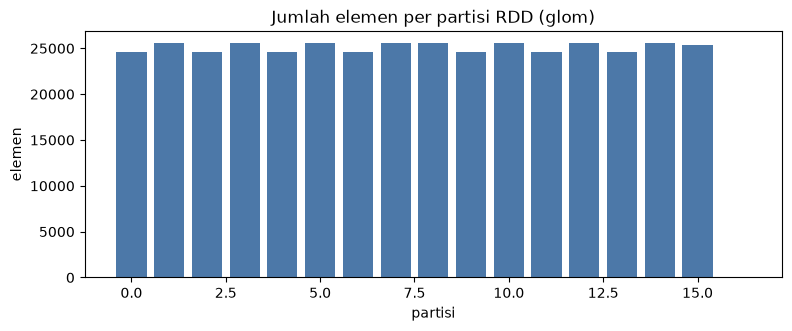

In [18]:
# ===== SOAL 2a: Parsing + accumulator + partisi =====
from operator import add
SISIPKAN_BARIS_UJI = True        # 3 baris rusak buatan untuk MEMBUKTIKAN accumulator bekerja (dilaporkan terpisah)
BARIS_UJI_RUSAK = ['{"wiki": "idwiki", "title": "Rusak"', "bukan json sama sekali", '{"type": "edit"}']
WAJIB = ("wiki", "type", "title", "timestamp")
URI_SNAPSHOT = SNAP_PATH.resolve().as_uri()

@contextlib.contextmanager
def grup_job(nama):
    """Beri nama job agar mudah dicari di Spark UI dan REST API (/api/v1/.../jobs)."""
    spark.sparkContext.setJobGroup(nama, nama)
    try:
        yield
    finally:
        spark.sparkContext.setLocalProperty("spark.jobGroup.id", None)
        spark.sparkContext.setLocalProperty("spark.job.description", None)

def baca_raw_rdd(minPartitions=TOTAL_CORE):
    if SUMBER_SNAPSHOT == "kafka":
        df_k = (spark.read.format("kafka").option("kafka.bootstrap.servers", BOOTSTRAP).option("subscribe", TOPIC_RAW)
                .option("startingOffsets", json.dumps({TOPIC_RAW: {str(p): o for p, o in SNAP_AWAL.items()}}))
                .option("endingOffsets", json.dumps({TOPIC_RAW: {str(p): o for p, o in SNAP_AKHIR.items()}})).load())
        return df_k.selectExpr("CAST(value AS STRING) AS v").rdd.map(lambda r: r.v)
    with open(SNAP_PATH, "r", encoding="utf-8") as f:
        baris = [b for b in f.read().split("\n") if b]
    return spark.sparkContext.parallelize(baris, max(minPartitions, 16))

def buat_pengurai(acc_rusak, acc_tidak_lengkap):
    def urai(baris):
        try:
            d = json.loads(baris)
        except (ValueError, TypeError):
            acc_rusak.add(1); return []                       # gagal parse: DIHITUNG, bukan dibuang diam-diam
        if not isinstance(d, dict) or any(d.get(k) is None for k in WAJIB):
            acc_tidak_lengkap.add(1); return []
        d["bot"] = bool(d.get("bot"))
        d["comment"] = d.get("comment") or ""
        return [d]
    return urai

def kunci_rdd(d):
    return f"{d['wiki']}:{d['id']}" if d.get("id") is not None else f"{d['wiki']}:uuid:{d.get('meta_id')}"

acc_rusak = spark.sparkContext.accumulator(0)
acc_tidak_lengkap = spark.sparkContext.accumulator(0)
raw = baca_raw_rdd()
if SISIPKAN_BARIS_UJI:
    raw = raw.union(spark.sparkContext.parallelize(BARIS_UJI_RUSAK, 1))
parsed = raw.flatMap(buat_pengurai(acc_rusak, acc_tidak_lengkap)).cache()
with grup_job("2a_parse"):
    n_valid = parsed.count()
with grup_job("2a_glom"):
    sebaran = parsed.glom().map(len).collect()
with grup_job("2a_dedup"):
    unik = parsed.map(lambda d: (kunci_rdd(d), d)).reduceByKey(lambda a, b: a).values().cache()
    n_unik = unik.count()

with catat("2a_parsing_partisi"):
    n_baris = sum(SNAP_AKHIR[p] - SNAP_AWAL[p] for p in SNAP_AKHIR) + (len(BARIS_UJI_RUSAK) if SISIPKAN_BARIS_UJI else 0)
    print(f"Baris dibaca            : {n_baris:,}" + (f" (termasuk {len(BARIS_UJI_RUSAK)} baris uji rusak)" if SISIPKAN_BARIS_UJI else ""))
    print(f"Valid (dict)            : {n_valid:,}")
    print(f"Gagal parse JSON        : {acc_rusak.value}   <- accumulator")
    print(f"Field wajib kosong      : {acc_tidak_lengkap.value}   <- accumulator")
    print(f"Event unik (wiki+id)    : {n_unik:,}  -> duplikat dibuang {n_valid - n_unik:,}")
    print(f"\nJumlah partisi RDD      : {raw.getNumPartitions()} (snapshot) -> parsed {parsed.getNumPartitions()}")
    print(f"Elemen per partisi glom : {sebaran}" + ("  (partisi terakhir = 3 baris uji rusak dari union, sehingga 0 elemen valid)"
                                                       if SISIPKAN_BARIS_UJI else ""))
    print(f"min/maks/rata-rata      : {min(sebaran):,} / {max(sebaran):,} / {sum(sebaran) / len(sebaran):,.0f}")
    print("\nContoh 1 elemen hasil parsing:", parsed.first())
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(range(len(sebaran)), sebaran, color="#4C78A8")
ax.set(title="Jumlah elemen per partisi RDD (glom)", xlabel="partisi", ylabel="elemen")
simpan_grafik(fig, "2a_glom"); plt.show()
RINGKASAN["2a"] = {"valid": n_valid, "rusak": acc_rusak.value, "tidak_lengkap": acc_tidak_lengkap.value, "unik": n_unik,
                   "partisi": raw.getNumPartitions(), "glom": sebaran}

## 2b · Analisis hanya dengan operasi RDD (filter, map, flatMap, reduceByKey, takeOrdered)
Data yang dipakai: `unik` (sudah bebas duplikat wiki+id). "Disunting" = `type` edit atau new.

In [19]:
# ===== SOAL 2b: Operasi RDD =====
STOPWORDS = set("""
yang dan di ke dari ini itu untuk dengan pada adalah sebagai dalam tidak akan atau juga oleh karena ada bisa dapat telah sudah
saya kami kita anda dia mereka ia nya pun lah kah para sang si bagi tentang antara serta hingga sampai agar supaya jika kalau
maka namun tetapi tapi lalu kemudian setelah sebelum saat ketika masih baru lebih paling sangat hanya bukan belum menjadi
beberapa banyak semua setiap tersebut secara yaitu yakni dll dsb the of and to in a is for on with by from at as this that be are
was an it or not http https www com org html php jpg png svg ref url amp nbsp isbn
""".split())
POLA_KATA = re.compile(r"[^\W\d_]{3,}")
DISUNTING = ("edit", "new")

def soal_i(rdd):
    return (rdd.filter(lambda d: d["type"] == "edit" and not d["bot"])               # narrow
               .map(lambda d: (d["wiki"], 1))                                       # narrow
               .reduceByKey(add))                                                   # wide (shuffle)

def soal_ii(rdd):
    return (rdd.filter(lambda d: d["wiki"] == "idwiki" and d["type"] in DISUNTING)
               .map(lambda d: (d["title"], 1))
               .reduceByKey(add))

def soal_iii(rdd):
    stop = frozenset(STOPWORDS)   # kecil (~150 kata): dikirim lewat closure, tanpa broadcast
    return (rdd.filter(lambda d: d["wiki"] == "idwiki" and d["type"] in DISUNTING and d["comment"])
               .flatMap(lambda d: POLA_KATA.findall(d["comment"].lower()))           # narrow (1 -> banyak)
               .filter(lambda k: k not in stop)
               .map(lambda k: (k, 1))
               .reduceByKey(add))

urut = lambda kv: (-kv[1], kv[0])
with grup_job("2b_i_wiki_manusia"):
    top_wiki = soal_i(unik).takeOrdered(10, key=urut)                               # action
with grup_job("2b_ii_halaman_idwiki"):
    top_halaman = soal_ii(unik).takeOrdered(10, key=urut)
with grup_job("2b_iii_kata_idwiki"):
    top_kata = soal_iii(unik).takeOrdered(15, key=urut)

with catat("2b_hasil_rdd"):
    print("(i) 10 wiki dengan edit manusia terbanyak (type=edit, bot=false):")
    print(pd.DataFrame(top_wiki, columns=["wiki", "edit_manusia"]).to_string(index=False))
    print("\n(ii) 10 halaman idwiki paling banyak disunting:")
    print(pd.DataFrame(top_halaman, columns=["judul", "jumlah_suntingan"]).to_string(index=False) if top_halaman else "  (belum ada data idwiki)")
    print("\n(iii) 15 kata terbanyak di comment suntingan idwiki (stopword dibuang):")
    print(pd.DataFrame(top_kata, columns=["kata", "frekuensi"]).to_string(index=False) if top_kata else "  (belum ada data idwiki)")

JENIS_OPERASI = pd.DataFrame([
    ("textFile / parallelize", "sumber", "membuat RDD dari berkas/koleksi"),
    ("flatMap(urai)", "narrow", "setiap partisi diolah sendiri, tanpa pertukaran data antar-executor"),
    ("filter", "narrow", "baris disaring di partisi asalnya"),
    ("map", "narrow", "transformasi 1 baris -> 1 baris di partisi yang sama"),
    ("flatMap(tokenisasi)", "narrow", "1 komentar -> banyak kata, tetap di partisi yang sama"),
    ("reduceByKey", "wide", "kunci yang sama harus berkumpul di satu partisi -> shuffle (batas stage baru); ada map-side combine"),
    ("groupByKey (2c)", "wide", "shuffle semua nilai tanpa penggabungan awal"),
    ("takeOrdered", "action", "top-N dihitung per partisi lalu digabung di driver (tanpa shuffle)"),
    ("count / collect / glom().collect()", "action", "memicu eksekusi job"),
], columns=["operasi", "jenis", "keterangan"])
display(JENIS_OPERASI)
bukti("2b_narrow_wide", JENIS_OPERASI)
RINGKASAN["2b"] = {"top_wiki": top_wiki, "top_halaman_idwiki": top_halaman, "top_kata_idwiki": top_kata}

(i) 10 wiki dengan edit manusia terbanyak (type=edit, bot=false):
        wiki  edit_manusia
wikidatawiki         66515
 commonswiki         23715
      enwiki         21338
      frwiki          3429
      dewiki          2989
      ruwiki          2030
      itwiki          2024
      eswiki          1858
     kaawiki          1142
      zhwiki          1020

(ii) 10 halaman idwiki paling banyak disunting:
                      judul  jumlah_suntingan
        D'Academy (musim 8)                14
                   Facebook                 7
Harimau Putih Terikat Cinta                 6
  Pengguna:LiškovBot/Switch                 6
                   Yan Ying                 6
                   Geo Mild                 5
       Soerjadi Soerjadarma                 5
                     Dendam                 4
Muhammad Kelvin Mardiansyah                 4
                     Tiktok                 4

(iii) 15 kata terbanyak di comment suntingan idwiki (stopword dibuang):
        k

,operasi,jenis,keterangan
0,textFile / parallelize,sumber,membuat RDD dari berkas/koleksi
1,flatMap(urai),narrow,"setiap partisi diolah sendiri, tanpa pertukaran data antar-executor"
2,filter,narrow,baris disaring di partisi asalnya
3,map,narrow,transformasi 1 baris -> 1 baris di partisi yang sama
4,flatMap(tokenisasi),narrow,"1 komentar -> banyak kata, tetap di partisi yang sama"
5,reduceByKey,wide,kunci yang sama harus berkumpul di satu partisi -> shuffle (batas stage baru); ada map...
6,groupByKey (2c),wide,shuffle semua nilai tanpa penggabungan awal
7,takeOrdered,action,top-N dihitung per partisi lalu digabung di driver (tanpa shuffle)
8,count / collect / glom().collect(),action,memicu eksekusi job


## 2c · `groupByKey().mapValues(sum)` vs `reduceByKey`: waktu dan Shuffle Write/Read
Metrik shuffle diambil dari REST API Spark UI (angka yang sama dengan tab **Stages**). Ambil juga tangkapan layar tab Stages
untuk job `2c_reduceByKey` dan `2c_groupByKey`.

In [20]:
# ===== SOAL 2c: groupByKey vs reduceByKey =====
def ringkas_grup(grup, tunggu=1.5):
    time.sleep(tunggu)                                    # REST diperbarui listener secara asinkron
    jobs = [j for j in rest("/jobs") if j.get("jobGroup") == grup]
    sid = {s for j in jobs for s in j["stageIds"]}
    stages = [s for s in rest("/stages") if s["stageId"] in sid]
    jalan = [s for s in stages if s.get("status") != "SKIPPED"]
    return {"job": len(jobs), "stage": len(sid), "stage_dilewati": sum(j.get("numSkippedStages", 0) for j in jobs),
            "task": sum(j.get("numTasks", 0) for j in jobs), "task_dilewati": sum(j.get("numSkippedTasks", 0) for j in jobs),
            "shuffle_write_kb": round(sum(s.get("shuffleWriteBytes", 0) for s in jalan) / 1024, 1),
            "shuffle_write_record": sum(s.get("shuffleWriteRecords", 0) for s in jalan),
            "shuffle_read_kb": round(sum(s.get("shuffleReadBytes", 0) for s in jalan) / 1024, 1),
            "shuffle_read_record": sum(s.get("shuffleReadRecords", 0) for s in jalan)}

def ukur(fn, ulang=3):
    w = []
    for _ in range(ulang):
        t0 = time.perf_counter(); fn(); w.append(time.perf_counter() - t0)
    return round(min(w), 3), [round(x, 3) for x in w]

pasangan = unik.filter(lambda d: d["type"] == "edit" and not d["bot"]).map(lambda d: (d["wiki"], 1)).cache()
pasangan.count()                                           # materialisasi agar yang diukur hanya agregasinya
SKALA_2C = 20                                              # uji tambahan: pasangan diperbanyak agar tren terlihat jelas
besar_2c = pasangan.flatMap(lambda kv: [kv] * SKALA_2C).cache(); besar_2c.count()

def nilai_shuffle(rdd):
    """Jumlah nilai yang benar-benar dikirim: reduceByKey = 1 per (partisi, wiki); groupByKey = semua nilai."""
    per_partisi = rdd.mapPartitions(lambda it: [len({k for k, _ in it})]).sum()
    return per_partisi, rdd.count()

hasil_2c = []
for data, label in ((pasangan, "data asli"), (besar_2c, f"diperbanyak {SKALA_2C}x")):
    n_reduce, n_group = nilai_shuffle(data)
    for nama, fn, n_nilai in (("reduceByKey", lambda d=data: d.reduceByKey(add).collect(), n_reduce),
                              ("groupByKey().mapValues(sum)", lambda d=data: d.groupByKey().mapValues(sum).collect(), n_group)):
        grup = f"2c_{nama.split('(')[0]}_{label.split()[0]}"
        with grup_job(grup + "_waktu"):
            terbaik, semua = ukur(fn)                      # waktu: terbaik dari 3 eksekusi
        with grup_job(grup):
            fn()                                           # metrik shuffle: 1 eksekusi
        r = ringkas_grup(grup)
        hasil_2c.append({"data": label, "metode": nama, "waktu_terbaik_dtk": terbaik, "nilai_dikirim_lewat_shuffle": n_nilai,
                         "shuffle_write_kb": r["shuffle_write_kb"], "shuffle_read_kb": r["shuffle_read_kb"],
                         "record_shuffle_spark_ui": r["shuffle_write_record"], "stage": r["stage"], "task": r["task"], "semua_percobaan": semua})
df_2c = pd.DataFrame(hasil_2c)
sama = dict(pasangan.reduceByKey(add).collect()) == dict(pasangan.groupByKey().mapValues(sum).collect())
with catat("2c_groupByKey_vs_reduceByKey"):
    print(df_2c.drop(columns=["semua_percobaan"]).to_string(index=False))
    print(f"\nHasil kedua metode identik: {sama} | pasangan (wiki, 1): {pasangan.count():,}")
    for label in df_2c["data"].unique():
        r, g = df_2c[df_2c["data"] == label].to_dict("records")
        print(f"[{label}] groupByKey: waktu {g['waktu_terbaik_dtk'] / max(r['waktu_terbaik_dtk'], 1e-3):.2f}x, "
              f"nilai di-shuffle {g['nilai_dikirim_lewat_shuffle'] / max(r['nilai_dikirim_lewat_shuffle'], 1):.0f}x, "
              f"shuffle write {g['shuffle_write_kb'] / max(r['shuffle_write_kb'], 0.01):.1f}x dibanding reduceByKey")
    print("\nPenyebab: reduceByKey melakukan map-side combine, yaitu menjumlah dulu di tiap partisi sehingga hanya satu angka per"
          " (partisi, wiki) yang dikirim. groupByKey harus mengirim SEMUA nilai ke executor tujuan lalu menyimpannya di memori sebelum"
          " dijumlah, sehingga byte shuffle, memori, dan waktunya tumbuh seiring jumlah data (lihat baris data yang diperbanyak).")
    print("Catatan PySpark: groupByKey di PySpark lebih dulu mengelompokkan nilai menjadi list per partisi, dan Spark UI menghitung"
          " 'record' shuffle sebagai batch hasil pickle. Karena itu jumlah record di Spark UI bisa mirip; bedanya terlihat pada"
          " byte shuffle dan jumlah nilai yang dikirim. Pada data kecil selisih byte tersamar kompresi shuffle (lz4) dan overhead tetap job.")
bukti("2c_tabel", df_2c)
besar_2c.unpersist(); pasangan.unpersist()
RINGKASAN["2c"] = df_2c.drop(columns=["semua_percobaan"]).to_dict("records")

           data                      metode  waktu_terbaik_dtk  nilai_dikirim_lewat_shuffle  shuffle_write_kb  shuffle_read_kb  record_shuffle_spark_ui  stage  task
      data asli                 reduceByKey             18.974                         2488              48.5             48.5                      289      3    51
      data asli groupByKey().mapValues(sum)             19.597                       143344              54.1             54.1                      289      3    51
diperbanyak 20x                 reduceByKey             17.964                         2488              49.2             49.2                      289      3    51
diperbanyak 20x groupByKey().mapValues(sum)             18.407                      2866880              82.0             82.0                      289      3    51

Hasil kedua metode identik: True | pasangan (wiki, 1): 143,344
[data asli] groupByKey: waktu 1.03x, nilai di-shuffle 58x, shuffle write 1.1x dibanding reduceByKey
[diperbanya

## 2d · Lineage, tabel Job–Stage–Task per action, dan pengaruh `cache()`

In [21]:
# ===== SOAL 2d: Lineage + Job-Stage-Task + cache =====
rdd_i = soal_i(unik)
with catat("2d_lineage"):
    print("Lineage (toDebugString) RDD (i). Tanda '+-' = batas shuffle/stage baru:\n")
    print(rdd_i.toDebugString().decode("utf-8"))

# Tabel Job-Stage-Task: setiap action diberi grup sendiri lalu dibaca dari REST API Spark UI
aksi_uji = {
    "raw.count()":                 lambda: raw.count(),
    "parsed.count() [cache]":      lambda: parsed.count(),
    "unik.count() [cache]":        lambda: unik.count(),
    "(i) takeOrdered":             lambda: rdd_i.takeOrdered(10, key=urut),
    "(ii) takeOrdered":            lambda: soal_ii(unik).takeOrdered(10, key=urut),
    "(iii) takeOrdered":           lambda: soal_iii(unik).takeOrdered(15, key=urut),
    "parsed.glom().map(len).collect()": lambda: parsed.glom().map(len).collect(),
}
baris_jst = []
for i, (nama, fn) in enumerate(aksi_uji.items()):
    grup = f"2d_aksi_{i}"
    with grup_job(grup):
        t0 = time.perf_counter(); fn(); dt = time.perf_counter() - t0
    r = ringkas_grup(grup)
    baris_jst.append({"action": nama, "job": r["job"], "stage": r["stage"], "stage_dilewati": r["stage_dilewati"],
                      "task": r["task"], "task_dilewati": r["task_dilewati"], "detik": round(dt, 2)})
df_jst = pd.DataFrame(baris_jst)
with catat("2d_job_stage_task"):
    print(df_jst.to_string(index=False))
    print("\nStage dilewati (skipped) = hasil shuffle sebelumnya dipakai ulang; task pada RDD yang di-cache tidak membaca ulang berkas.")
bukti("2d_tabel_job_stage_task", df_jst)

# Pengaruh cache: tiga action pada RDD hasil parsing, tanpa vs dengan cache
def tiga_aksi(rdd):
    rdd.count()
    soal_i(rdd).takeOrdered(10, key=urut)
    soal_ii(rdd).takeOrdered(10, key=urut)

acc_nc, acc_nc2 = spark.sparkContext.accumulator(0), spark.sparkContext.accumulator(0)
tanpa_cache = raw.flatMap(buat_pengurai(acc_nc, acc_nc2))
with grup_job("2d_tanpa_cache"):
    t_nc, _ = ukur(lambda: tiga_aksi(tanpa_cache), ulang=1)
acc_c, acc_c2 = spark.sparkContext.accumulator(0), spark.sparkContext.accumulator(0)
dengan_cache = raw.flatMap(buat_pengurai(acc_c, acc_c2)).cache()
with grup_job("2d_dengan_cache"):
    t_c, _ = ukur(lambda: tiga_aksi(dengan_cache), ulang=1)
with grup_job("2d_dengan_cache_ulang"):
    t_c2, _ = ukur(lambda: tiga_aksi(dengan_cache), ulang=1)
try:
    simpan = [r for r in rest("/storage/rdd") if r.get("numCachedPartitions", 0) > 0]
except Exception:
    simpan = []
df_cache = pd.DataFrame([
    {"skenario": "tanpa cache (3 action)", "detik": t_nc, "baris_rusak_terhitung_accumulator": acc_nc.value, **ringkas_grup("2d_tanpa_cache")},
    {"skenario": "dengan cache (3 action, termasuk mengisi cache)", "detik": t_c, "baris_rusak_terhitung_accumulator": acc_c.value, **ringkas_grup("2d_dengan_cache")},
    {"skenario": "dengan cache, diulang (cache sudah terisi)", "detik": t_c2, "baris_rusak_terhitung_accumulator": acc_c.value, **ringkas_grup("2d_dengan_cache_ulang")}])
with catat("2d_pengaruh_cache"):
    print(df_cache[["skenario", "detik", "job", "stage", "task", "baris_rusak_terhitung_accumulator"]].to_string(index=False))
    print(f"\nPercepatan setelah cache terisi: {t_nc / max(t_c2, 1e-3):.1f}x")
    for r in simpan:
        print(f"RDD ter-cache id={r.get('id')} ({r.get('name')}) | partisi {r.get('numCachedPartitions')}/{r.get('numPartitions')} | "
              f"memori {r.get('memoryUsed', 0) / 1e6:.1f} MB | level {r.get('storageLevel')}")
    print("Catatan: accumulator di dalam transformasi ikut bertambah setiap kali RDD dihitung ulang (tanpa cache, nilainya 3x lipat);"
          " hitungan yang tepat dibaca setelah satu action pada RDD yang di-cache.")
bukti("2d_tabel_cache", df_cache)
dengan_cache.unpersist()
RINGKASAN["2d"] = {"job_stage_task": df_jst.to_dict("records"), "cache": df_cache[["skenario", "detik"]].to_dict("records")}

Lineage (toDebugString) RDD (i). Tanda '+-' = batas shuffle/stage baru:

(17) PythonRDD[135] at RDD at PythonRDD.scala:59 []
 |   MapPartitionsRDD[134] at mapPartitions at PythonRDD.scala:171 []
 |   ShuffledRDD[133] at partitionBy at <unknown>:0 []
 +-(17) PairwiseRDD[132] at reduceByKey at C:\Users\Lenovo\AppData\Local\Temp\ipykernel_2216\648362642.py:15 []
    |   PythonRDD[131] at reduceByKey at C:\Users\Lenovo\AppData\Local\Temp\ipykernel_2216\648362642.py:15 []
    |   PythonRDD[14] at RDD at PythonRDD.scala:59 []
    |       CachedPartitions: 17; MemorySize: 55.9 MiB; DiskSize: 0.0 B
    |   MapPartitionsRDD[13] at mapPartitions at PythonRDD.scala:171 []
    |   ShuffledRDD[12] at partitionBy at NativeMethodAccessorImpl.java:0 []
    +-(17) PairwiseRDD[11] at reduceByKey at C:\Users\Lenovo\AppData\Local\Temp\ipykernel_2216\1374588874.py:55 []
       |   PythonRDD[10] at reduceByKey at C:\Users\Lenovo\AppData\Local\Temp\ipykernel_2216\1374588874.py:55 []
       |   PythonRDD[7] a

# Soal 3 — Spark DataFrame dan SQL
## 3a · DataFrame dengan skema eksplisit, kolom waktu & `selisih_byte`, temporary view

In [22]:
# ===== SOAL 3a: Skema eksplisit + kolom turunan + temp view =====
import socket
spark.catalog.clearCache()   # buang cache dari percobaan yang gagal

SKEMA = T.StructType([
    T.StructField("id", T.LongType()), T.StructField("type", T.StringType()), T.StructField("wiki", T.StringType()),
    T.StructField("server_name", T.StringType()), T.StructField("title", T.StringType()), T.StructField("namespace", T.IntegerType()),
    T.StructField("user", T.StringType()), T.StructField("anon", T.BooleanType()), T.StructField("bot", T.BooleanType()),
    T.StructField("minor", T.BooleanType()), T.StructField("timestamp", T.LongType()),
    T.StructField("length", T.StructType([T.StructField("old", T.LongType()), T.StructField("new", T.LongType())])),
    T.StructField("comment", T.StringType()), T.StructField("meta_id", T.StringType()),
])
SKEMA_BACA = T.StructType(SKEMA.fields + [T.StructField("_corrupt_record", T.StringType())])

def periksa_berkas_executor(path, ukuran_master):
    """Cek semua executor: berkas snapshot ada dan ukurannya sama dengan di Master."""
    def cek(_):
        ada = os.path.exists(path)
        yield (socket.gethostname(), ada, os.path.getsize(path) if ada else -1)
    hasil = sorted(set(spark.sparkContext.parallelize(range(400), 400).mapPartitions(cek).collect()))
    df_cek = pd.DataFrame(hasil, columns=["host", "ada", "ukuran_byte"])
    df_cek["sesuai"] = df_cek["ada"] & (df_cek["ukuran_byte"] == ukuran_master)
    return df_cek

def baca_df_snapshot():
    if SUMBER_SNAPSHOT == "kafka":
        k = (spark.read.format("kafka").option("kafka.bootstrap.servers", BOOTSTRAP).option("subscribe", TOPIC_RAW)
             .option("startingOffsets", json.dumps({TOPIC_RAW: {str(p): o for p, o in SNAP_AWAL.items()}}))
             .option("endingOffsets", json.dumps({TOPIC_RAW: {str(p): o for p, o in SNAP_AKHIR.items()}})).load())
        v = k.select(F.col("value").cast("string").alias("_v"))
        return v.select(F.from_json("_v", SKEMA).alias("e"), "_v").select(
            "e.*", F.when(F.col("e.wiki").isNull(), F.col("_v")).alias("_corrupt_record"))
    return (spark.read.schema(SKEMA_BACA).option("mode", "PERMISSIVE")
            .option("columnNameOfCorruptRecord", "_corrupt_record").json(URI_SNAPSHOT))

def siapkan(df):
    """Kolom turunan yang dipakai Soal 3 dan 4."""
    return (df.withColumn("waktu", F.timestamp_seconds("timestamp"))
              .withColumn("bot", F.coalesce("bot", F.lit(False)))
              .withColumn("selisih_byte", F.col("length.new") - F.coalesce(F.col("length.old"), F.lit(0)))
              .withColumn("kunci_dedup", F.concat_ws(":", "wiki", F.coalesce(F.col("id").cast("string"),
                                                                            F.concat(F.lit("uuid:"), F.col("meta_id"))))))

# --- Pemeriksaan sumber data sebelum membaca ---
if SUMBER_SNAPSHOT == "jsonl":
    df_cek = periksa_berkas_executor(str(SNAP_PATH), Path(SNAP_PATH).stat().st_size)
    print("Pemeriksaan berkas snapshot di executor:")
    print(df_cek.to_string(index=False))
    if not df_cek["sesuai"].all():
        if KONEKTOR_OK:
            print("\nAda PC tanpa berkas yang sesuai -> beralih ke konektor Spark-Kafka (offset snapshot yang sama).")
            SUMBER_SNAPSHOT = "kafka"
        else:
            raise RuntimeError("Berkas snapshot belum sesuai di semua PC. Lengkapi dulu salinannya "
                               "(kirim ulang perintah SNAPSHOT dari Master), lalu jalankan ulang sel ini.")

df_baca = baca_df_snapshot().cache()                     # cache wajib sebelum memfilter _corrupt_record saja
n_rusak_df = df_baca.filter(F.col("_corrupt_record").isNotNull()).count()
df_valid = df_baca.filter(F.col("_corrupt_record").isNull()).drop("_corrupt_record") \
                  .dropna(subset=list(WAJIB))
n_valid = df_valid.count()
df = siapkan(df_valid).dropDuplicates(["kunci_dedup"]).cache()
df.createOrReplaceTempView("suntingan")
with catat("3a_skema_dataframe"):
    n_df = df.count()
    print(f"Sumber: {SUMBER_SNAPSHOT} | Baris valid: {n_valid:,} | rusak: {n_rusak_df} | unik setelah dropDuplicates(kunci_dedup): {n_df:,} "
          f"(RDD 2a: {n_unik:,} -> {'KONSISTEN' if n_df == n_unik else 'BERBEDA'})")
    df.printSchema()
    df.select("wiki", "type", "title", "user", "bot", "timestamp", "waktu", "length", "selisih_byte").show(5, truncate=40)
    print("Temporary view 'suntingan' terdaftar:", [t.name for t in spark.catalog.listTables() if t.isTemporary])
RINGKASAN["3a"] = {"baris_unik": n_df, "rusak": n_rusak_df, "konsisten_dengan_rdd": n_df == n_unik, "sumber": SUMBER_SNAPSHOT}

Pemeriksaan berkas snapshot di executor:
           host   ada  ukuran_byte  sesuai
LAPTOP-4SSHBGPC False           -1   False
LAPTOP-DVI8RKSS False           -1   False
           iyee False           -1   False
        izxytzy False           -1   False

Ada PC tanpa berkas yang sesuai -> beralih ke konektor Spark-Kafka (offset snapshot yang sama).
Sumber: kafka | Baris valid: 402,171 | rusak: 0 | unik setelah dropDuplicates(kunci_dedup): 402,171 (RDD 2a: 402,171 -> KONSISTEN)
root
 |-- id: long (nullable = true)
 |-- type: string (nullable = true)
 |-- wiki: string (nullable = true)
 |-- server_name: string (nullable = true)
 |-- title: string (nullable = true)
 |-- namespace: integer (nullable = true)
 |-- user: string (nullable = true)
 |-- anon: boolean (nullable = true)
 |-- bot: boolean (nullable = false)
 |-- minor: boolean (nullable = true)
 |-- timestamp: long (nullable = true)
 |-- length: struct (nullable = true)
 |    |-- old: long (nullable = true)
 |    |-- new: long (n

## 3b · Kueri SQL (i)–(iv) dan pengecekan konsistensi dengan hasil RDD (Soal 2)

--- (i) i_edit_per_menit_top5 | 928 baris | 7.17 dtk


,wiki,menit,jumlah_edit
0,commonswiki,2026-11-17 21:38,51
1,dewiki,2026-11-17 21:38,4
2,enwiki,2026-11-17 21:38,28
3,frwiki,2026-11-17 21:38,7
4,wikidatawiki,2026-11-17 21:38,77
5,commonswiki,2026-11-17 21:39,246
6,dewiki,2026-11-17 21:39,17
7,enwiki,2026-11-17 21:39,125
8,frwiki,2026-11-17 21:39,17
9,wikidatawiki,2026-11-17 21:39,351


--- (ii) ii_persen_bot_manusia | 296 baris | 2.67 dtk


,wiki,total_edit,edit_bot,edit_manusia,persen_bot,persen_manusia
0,wikidatawiki,66959,444,66515,0.66,99.34
1,commonswiki,56459,32744,23715,58.00,42.00
2,enwiki,23034,1696,21338,7.36,92.64
3,frwiki,3812,383,3429,10.05,89.95
4,dewiki,3464,475,2989,13.71,86.29
5,arwiki,3197,2664,533,83.33,16.67
6,zhwiki,2515,1495,1020,59.44,40.56
7,ruwiki,2329,299,2030,12.84,87.16
8,itwiki,2191,167,2024,7.62,92.38
9,plwiki,2170,1402,768,64.61,35.39


--- (iii) iii_selisih_byte_per_type | 4 baris | 5.25 dtk


,type,jumlah,punya_ukuran,rata_abs_selisih_byte,median_abs_selisih_byte
0,edit,194337,194337,939.26,297.0
1,categorize,163160,0,NaN,NaN
2,new,22422,22422,1480.73,237.0
3,log,22252,0,NaN,NaN


--- (iv) iv_editor_unik_idwiki | 10 baris | 2.50 dtk


,title,editor_unik,jumlah_suntingan
0,Facebook,5,7
1,D'Academy (musim 8),3,14
2,Tiktok,3,4
3,X (media sosial),3,4
4,Carmelle Collado,3,3
5,Yan Ying,2,6
6,Dendam,2,4
7,Jonathan Mono,2,2
8,Harimau Putih Terikat Cinta,1,6
9,Pengguna:LiškovBot/Switch,1,6


Seluruh wiki: 296/296 sama | wiki berbeda: []

10 wiki teratas RDD (2b-i) vs SQL (3b-ii):
        wiki  rdd_2b_i  edit_manusia  sama
wikidatawiki     66515         66515  True
 commonswiki     23715         23715  True
      enwiki     21338         21338  True
      frwiki      3429          3429  True
      dewiki      2989          2989  True
      ruwiki      2030          2030  True
      itwiki      2024          2024  True
      eswiki      1858          1858  True
     kaawiki      1142          1142  True
      zhwiki      1020          1020  True


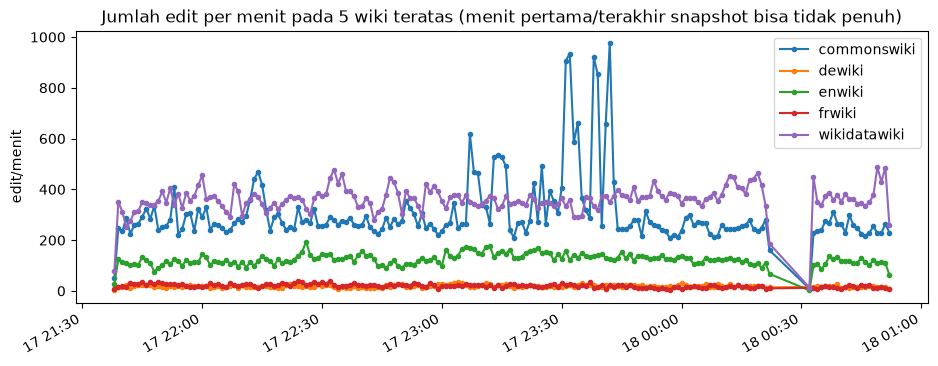

In [23]:
# ===== SOAL 3b: Kueri SQL =====
SQL = {
"i_edit_per_menit_top5": """
WITH top5 AS (
    SELECT wiki FROM suntingan WHERE type = 'edit' GROUP BY wiki ORDER BY COUNT(*) DESC LIMIT 5)
SELECT s.wiki, date_format(date_trunc('MINUTE', s.waktu), 'yyyy-MM-dd HH:mm') AS menit, COUNT(*) AS jumlah_edit
FROM suntingan s JOIN top5 t ON s.wiki = t.wiki
WHERE s.type = 'edit'
GROUP BY s.wiki, date_trunc('MINUTE', s.waktu)
ORDER BY menit, s.wiki""",
"ii_persen_bot_manusia": """
SELECT wiki,
       COUNT(*)                                   AS total_edit,
       SUM(CASE WHEN bot THEN 1 ELSE 0 END)       AS edit_bot,
       SUM(CASE WHEN NOT bot THEN 1 ELSE 0 END)   AS edit_manusia,
       ROUND(100.0 * SUM(CASE WHEN bot THEN 1 ELSE 0 END) / COUNT(*), 2)     AS persen_bot,
       ROUND(100.0 * SUM(CASE WHEN NOT bot THEN 1 ELSE 0 END) / COUNT(*), 2) AS persen_manusia
FROM suntingan WHERE type = 'edit'
GROUP BY wiki ORDER BY total_edit DESC""",
"iii_selisih_byte_per_type": """
SELECT type, COUNT(*) AS jumlah, COUNT(selisih_byte) AS punya_ukuran,
       ROUND(AVG(ABS(selisih_byte)), 2)                 AS rata_abs_selisih_byte,
       percentile_approx(ABS(selisih_byte), 0.5)        AS median_abs_selisih_byte
FROM suntingan GROUP BY type ORDER BY jumlah DESC""",
"iv_editor_unik_idwiki": """
SELECT title, COUNT(DISTINCT user) AS editor_unik, COUNT(*) AS jumlah_suntingan
FROM suntingan WHERE wiki = 'idwiki' AND type IN ('edit', 'new')
GROUP BY title ORDER BY editor_unik DESC, jumlah_suntingan DESC, title LIMIT 10""",
}
hasil_sql = {}
for nama, q in SQL.items():
    with grup_job(f"3b_{nama}"):
        t0 = time.perf_counter(); hasil_sql[nama] = spark.sql(q).toPandas(); dt = time.perf_counter() - t0
    bukti(f"3b_{nama}", hasil_sql[nama])
    print(f"--- ({nama.split('_')[0]}) {nama} | {len(hasil_sql[nama])} baris | {dt:.2f} dtk")
    display(hasil_sql[nama].head(15))

# Konsistensi (ii) SQL vs (i) RDD: edit manusia per wiki harus sama persis
manusia_rdd = dict(unik.filter(lambda d: d["type"] == "edit" and not d["bot"]).map(lambda d: (d["wiki"], 1)).reduceByKey(add).collect())
cek = hasil_sql["ii_persen_bot_manusia"][["wiki", "edit_manusia"]].copy()
cek["edit_manusia_rdd"] = cek["wiki"].map(lambda w: manusia_rdd.get(w, 0))
cek["sama"] = cek["edit_manusia"] == cek["edit_manusia_rdd"]
top10 = pd.DataFrame(top_wiki, columns=["wiki", "rdd_2b_i"]).merge(cek[["wiki", "edit_manusia"]], on="wiki", how="left")
with catat("3b_konsistensi_rdd_sql"):
    print(f"Seluruh wiki: {int(cek['sama'].sum())}/{len(cek)} sama | wiki berbeda: {cek.loc[~cek['sama'], 'wiki'].tolist()}")
    print("\n10 wiki teratas RDD (2b-i) vs SQL (3b-ii):")
    top10["sama"] = top10["rdd_2b_i"] == top10["edit_manusia"]
    print(top10.to_string(index=False))

d_i = hasil_sql["i_edit_per_menit_top5"]
if len(d_i):
    fig, ax = plt.subplots(figsize=(11, 4))
    for w, g in d_i.groupby("wiki"):
        ax.plot(pd.to_datetime(g["menit"]), g["jumlah_edit"], marker=".", label=w)
    ax.set(title="Jumlah edit per menit pada 5 wiki teratas (menit pertama/terakhir snapshot bisa tidak penuh)", ylabel="edit/menit")
    ax.legend(); fig.autofmt_xdate(); simpan_grafik(fig, "3b_i_edit_per_menit"); plt.show()
RINGKASAN["3b"] = {"konsisten_rdd_sql": bool(cek["sama"].all()), "persen_bot_top5": hasil_sql["ii_persen_bot_manusia"].head(5).to_dict("records")}

## 3c · Deteksi lonjakan: halaman dengan ≥ k edit dalam satu jendela 5 menit
`k` diambil dari distribusi jumlah edit per (halaman, jendela 5 menit), yaitu persentil ke-99 (dibulatkan ke atas, minimal 2).
Artinya hanya 1% pasangan halaman-jendela teraktif yang dianggap lonjakan, sehingga ambang menyesuaikan diri dengan data.

Pasangan (halaman, jendela 5 menit): 181,862 | maksimum 82 edit
Persentil jumlah edit: p50=1, p90=1, p95=2, p99=5, p99.9=16
Dengan k = p99 = 5: 2,284 pasangan ditandai (1.26%). Pembanding k = p99.9 = 16: 223 pasangan (0.12%).
Dasar pemilihan: sebaran sangat menceng (kebanyakan halaman hanya 1 edit per 5 menit), jadi ambang absolut (mis. 10) tidak adaptif. Persentil ke-99 menandai 1% pasangan teraktif dan otomatis menyesuaikan diri dengan volume aliran. Bila daftar terlalu panjang untuk ditinjau manual, p99.9 bisa dipakai sebagai level 'kritis'.
=> k = 5. Halaman dengan >= k edit dalam satu jendela 5 menit:
        wiki           title            mulai akhir  jumlah_edit  editor_unik  edit_bot               dugaan
wikidatawiki      Q140563905 2026-11-18 00:50 00:55           82            1         0 satu editor beruntun
wikidatawiki      Q140563810 2026-11-18 00:45 00:50           76            1         0 satu editor beruntun
wikidatawiki Lexeme:L1487852 2026-11-17 21:55 22:00        

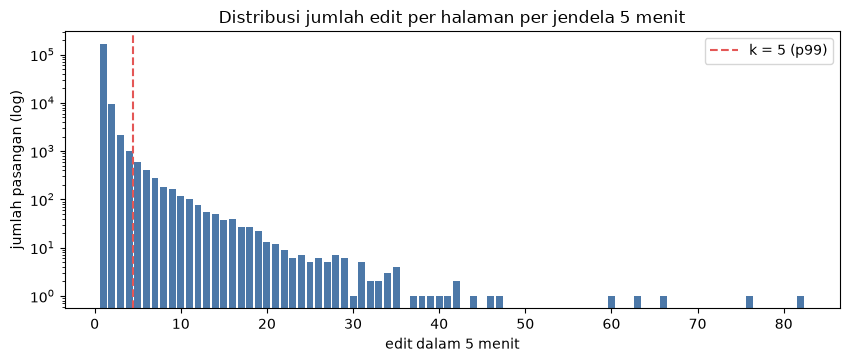

In [24]:
# ===== SOAL 3c: Deteksi lonjakan dengan window() =====
spark.sql("""
CREATE OR REPLACE TEMP VIEW hitung_5m AS
SELECT wiki, title, window(waktu, '5 minutes') AS jendela, COUNT(*) AS jumlah_edit,
       COUNT(DISTINCT user) AS editor_unik, SUM(CASE WHEN bot THEN 1 ELSE 0 END) AS edit_bot
FROM suntingan WHERE type IN ('edit', 'new')
GROUP BY wiki, title, window(waktu, '5 minutes')""")
with grup_job("3c_distribusi"):
    q = spark.sql("SELECT percentile_approx(jumlah_edit, array(0.5, 0.9, 0.95, 0.99, 0.999), 10000) AS p, "
                  "COUNT(*) AS n, MAX(jumlah_edit) AS maks FROM hitung_5m").collect()[0]
p50, p90, p95, p99, p999 = q["p"]
K_LONJAKAN = max(2, int(math.ceil(p99)))
K_999 = max(2, int(math.ceil(p999)))
n_k99 = spark.sql(f"SELECT COUNT(*) AS n FROM hitung_5m WHERE jumlah_edit >= {K_LONJAKAN}").first()["n"]
n_k999 = spark.sql(f"SELECT COUNT(*) AS n FROM hitung_5m WHERE jumlah_edit >= {K_999}").first()["n"]
with grup_job("3c_lonjakan"):
    lonjakan = spark.sql(f"""
    SELECT wiki, title, date_format(jendela.start, 'yyyy-MM-dd HH:mm') AS mulai, date_format(jendela.end, 'HH:mm') AS akhir,
           jumlah_edit, editor_unik, edit_bot,
           CASE WHEN edit_bot = jumlah_edit THEN 'bot (rutin/otomatis)'
                WHEN editor_unik - CASE WHEN edit_bot > 0 THEN 1 ELSE 0 END >= 2 THEN 'indikasi edit war/vandalisme (>=2 editor)'
                ELSE 'satu editor beruntun' END AS dugaan
    FROM hitung_5m WHERE jumlah_edit >= {K_LONJAKAN}
    ORDER BY jumlah_edit DESC, editor_unik DESC LIMIT 25""").toPandas()
with catat("3c_lonjakan"):
    print(f"Pasangan (halaman, jendela 5 menit): {q['n']:,} | maksimum {q['maks']} edit")
    print(f"Persentil jumlah edit: p50={p50}, p90={p90}, p95={p95}, p99={p99}, p99.9={p999}")
    print(f"Dengan k = p99 = {K_LONJAKAN}: {n_k99:,} pasangan ditandai ({100 * n_k99 / q['n']:.2f}%). "
          f"Pembanding k = p99.9 = {K_999}: {n_k999:,} pasangan ({100 * n_k999 / q['n']:.2f}%).")
    print("Dasar pemilihan: sebaran sangat menceng (kebanyakan halaman hanya 1 edit per 5 menit), jadi ambang absolut (mis. 10) tidak"
          " adaptif. Persentil ke-99 menandai 1% pasangan teraktif dan otomatis menyesuaikan diri dengan volume aliran. Bila daftar"
          " terlalu panjang untuk ditinjau manual, p99.9 bisa dipakai sebagai level 'kritis'.")
    print(f"=> k = {K_LONJAKAN}. Halaman dengan >= k edit dalam satu jendela 5 menit:")
    print(lonjakan.to_string(index=False) if len(lonjakan) else "  (tidak ada)")
bukti("3c_lonjakan", lonjakan)
dist = spark.sql("SELECT jumlah_edit, COUNT(*) AS n FROM hitung_5m GROUP BY jumlah_edit ORDER BY jumlah_edit").toPandas()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(dist["jumlah_edit"], dist["n"], color="#4C78A8"); ax.set_yscale("log")
ax.axvline(K_LONJAKAN - 0.5, color="#E45756", ls="--", label=f"k = {K_LONJAKAN} (p99)")
ax.set(title="Distribusi jumlah edit per halaman per jendela 5 menit", xlabel="edit dalam 5 menit", ylabel="jumlah pasangan (log)")
ax.legend(); simpan_grafik(fig, "3c_distribusi_lonjakan"); plt.show()
RINGKASAN["3c"] = {"p99": p99, "k": K_LONJAKAN, "jumlah_lonjakan": len(lonjakan)}

## 3d · `explain()`: Exchange & HashAggregate (partial/final), hubungan dengan Stage, dan optimasi

In [25]:
# ===== SOAL 3d: explain + optimasi =====
def rencana(df_):
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        df_.explain(mode="formatted")
    return buf.getvalue()

# View tanpa cache/dedup agar plan hanya berisi kueri agregasi (FileScan -> HashAggregate partial -> Exchange -> final)
siapkan(df_valid).createOrReplaceTempView("suntingan_mentah")
q_agregasi = spark.sql(SQL["ii_persen_bot_manusia"].replace("FROM suntingan", "FROM suntingan_mentah"))
teks_plan = rencana(q_agregasi)
with catat("3d_explain"):
    print(teks_plan)
    pohon = teks_plan.split("\n\n")[0]
    print("Ringkasan operator (pohon plan, dibaca dari bawah ke atas):\n" + pohon)
    for blok in teks_plan.split("\n\n"):
        judul = blok.strip().splitlines()[0] if blok.strip() else ""
        if re.match(r"\(\d+\) (HashAggregate|Exchange)", judul):
            detail = [b.strip() for b in blok.splitlines()[1:] if b.strip().startswith(("Keys", "Functions", "Arguments"))]
            print(f"  {judul}: " + " | ".join(detail)[:220])
with grup_job("3d_stage"):
    q_agregasi.collect()
r_st = ringkas_grup("3d_stage")
id_3d = {sid for j in rest("/jobs") if j.get("jobGroup") == "3d_stage" for sid in j["stageIds"]}
stages_3d = sorted([s for s in rest("/stages") if s["stageId"] in id_3d], key=lambda s: s["stageId"])
with catat("3d_stage"):
    print("Stage untuk kueri (ii) (bandingkan dengan tab Stages / SQL di Spark UI):")
    for s in stages_3d:
        print(f"  stage {s['stageId']:>3} [{s['status']:<8}] task={s['numTasks']:>3} shuffleWrite={s['shuffleWriteBytes'] / 1024:8.1f} KB "
              f"shuffleRead={s['shuffleReadBytes'] / 1024:8.1f} KB | {s['name'][:60]}")
    print("Stage pertama: scan + Filter + HashAggregate(partial) per partisi lalu shuffle write (Exchange hashpartitioning(wiki))."
          " Exchange adalah batas stage; stage berikutnya membaca shuffle dan menjalankan HashAggregate(final)."
          " Exchange kedua (rangepartitioning) muncul karena ORDER BY butuh pengurutan global, diikuti Sort."
          " Stage SKIPPED = shuffle yang sama dipakai ulang oleh job AQE berikutnya; AQE juga menggabung partisi shuffle kecil (task lebih sedikit).")

# Optimasi A: spark.sql.shuffle.partitions (AQE dimatikan agar pengaruhnya terlihat)
aqe_awal = spark.conf.get("spark.sql.adaptive.enabled")
sp_awal = spark.conf.get("spark.sql.shuffle.partitions")
opt = []
spark.conf.set("spark.sql.adaptive.enabled", "false")
for n in (200, TOTAL_CORE):
    spark.conf.set("spark.sql.shuffle.partitions", str(n))
    with grup_job(f"3d_shuffle_{n}"):
        terbaik, _ = ukur(lambda: spark.sql(SQL["ii_persen_bot_manusia"]).collect(), ulang=3)
    r = ringkas_grup(f"3d_shuffle_{n}")
    opt.append({"optimasi": f"shuffle.partitions = {n}", "waktu_terbaik_dtk": terbaik, "task_per_3_eksekusi": r["task"],
                "shuffle_read_kb_per_3": r["shuffle_read_kb"]})
spark.conf.set("spark.sql.shuffle.partitions", sp_awal)

# Optimasi B: broadcast tabel referensi wiki -> bahasa (tabel kecil)
WIKI_BAHASA = [("idwiki", "Indonesia"), ("enwiki", "Inggris"), ("wikidatawiki", "Wikidata (multibahasa)"), ("commonswiki", "Commons (multibahasa)"),
               ("dewiki", "Jerman"), ("frwiki", "Prancis"), ("eswiki", "Spanyol"), ("jawiki", "Jepang"), ("ruwiki", "Rusia"),
               ("itwiki", "Italia"), ("zhwiki", "Tionghoa"), ("ptwiki", "Portugis"), ("arwiki", "Arab"), ("nlwiki", "Belanda"),
               ("plwiki", "Polandia"), ("svwiki", "Swedia"), ("ukwiki", "Ukraina"), ("fawiki", "Persia"), ("viwiki", "Vietnam"),
               ("kowiki", "Korea"), ("trwiki", "Turki"), ("hewiki", "Ibrani"), ("jvwiki", "Jawa"), ("suwiki", "Sunda"),
               ("mswiki", "Melayu"), ("thwiki", "Thai"), ("hiwiki", "Hindi"), ("enwiktionary", "Inggris (Wiktionary)")]
ref_bahasa = spark.createDataFrame(WIKI_BAHASA, ["wiki", "bahasa"])
q_join = lambda r: (df.filter(F.col("type") == "edit").join(r, "wiki").groupBy("bahasa")
                      .agg(F.count("*").alias("edit"), F.round(100 * F.avg(F.col("bot").cast("int")), 2).alias("persen_bot")))
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")
plan_smj = rencana(q_join(ref_bahasa))
with grup_job("3d_join_sortmerge"):
    t_smj, _ = ukur(lambda: q_join(ref_bahasa).collect(), ulang=3)
r_smj = ringkas_grup("3d_join_sortmerge")
spark.conf.unset("spark.sql.autoBroadcastJoinThreshold")
plan_bhj = rencana(q_join(F.broadcast(ref_bahasa)))
with grup_job("3d_join_broadcast"):
    t_bhj, _ = ukur(lambda: q_join(F.broadcast(ref_bahasa)).collect(), ulang=3)
r_bhj = ringkas_grup("3d_join_broadcast")
spark.conf.set("spark.sql.adaptive.enabled", aqe_awal)
opt += [{"optimasi": "join tanpa broadcast (SortMergeJoin)" if "SortMergeJoin" in plan_smj else "join tanpa broadcast", "waktu_terbaik_dtk": t_smj,
         "task_per_3_eksekusi": r_smj["task"], "shuffle_read_kb_per_3": r_smj["shuffle_read_kb"]},
        {"optimasi": "join broadcast (BroadcastHashJoin)" if "BroadcastHashJoin" in plan_bhj else "join broadcast", "waktu_terbaik_dtk": t_bhj,
         "task_per_3_eksekusi": r_bhj["task"], "shuffle_read_kb_per_3": r_bhj["shuffle_read_kb"]}]
df_opt = pd.DataFrame(opt)
with catat("3d_optimasi"):
    print("(AQE dimatikan selama percobaan agar pengaruh tiap pengaturan terlihat)")
    print(df_opt.to_string(index=False))
    a, b = df_opt.iloc[0], df_opt.iloc[1]
    print(f"\nshuffle.partitions: 200 -> {TOTAL_CORE} mengubah waktu {a['waktu_terbaik_dtk']} -> {b['waktu_terbaik_dtk']} dtk "
          f"({a['waktu_terbaik_dtk'] / max(b['waktu_terbaik_dtk'], 1e-3):.1f}x) dan task {a['task_per_3_eksekusi']} -> {b['task_per_3_eksekusi']}: "
          "200 task kecil untuk hasil agregasi yang hanya ratusan baris adalah overhead penjadwalan.")
    c_, d_ = df_opt.iloc[2], df_opt.iloc[3]
    print(f"Broadcast join: shuffle read {c_['shuffle_read_kb_per_3']} -> {d_['shuffle_read_kb_per_3']} KB, waktu {c_['waktu_terbaik_dtk']} -> "
          f"{d_['waktu_terbaik_dtk']} dtk. Tabel referensi kecil dikirim ke tiap executor sehingga tabel besar tidak di-shuffle;"
          " bila waktunya setara, itu karena tabel 'besar' di snapshot ini pun masih kecil. Manfaatnya membesar saat data berukuran GB.")
    print("\nPotongan plan join tanpa broadcast:", [b.strip() for b in plan_smj.splitlines() if "Join" in b][:2])
    print("Potongan plan join broadcast     :", [b.strip() for b in plan_bhj.splitlines() if "Join" in b or "BroadcastExchange" in b][:3])
bukti("3d_optimasi", df_opt)
RINGKASAN["3d"] = df_opt.to_dict("records")

== Physical Plan ==
AdaptiveSparkPlan (14)
+- Sort (13)
   +- Exchange (12)
      +- HashAggregate (11)
         +- Exchange (10)
            +- HashAggregate (9)
               +- Project (8)
                  +- Filter (7)
                     +- InMemoryTableScan (1)
                           +- InMemoryRelation (2)
                                 +- * Project (6)
                                    +- Project (5)
                                       +- * Project (4)
                                          +- * Scan KafkaRelation(strategy=Subscribe[JOGIS-GANK-wiki-raw], start=SpecificOffsetRangeLimit(HashMap(JOGIS-GANK-wiki-raw-1 -> 0, JOGIS-GANK-wiki-raw-4 -> 0, JOGIS-GANK-wiki-raw-6 -> 0, JOGIS-GANK-wiki-raw-3 -> 0, JOGIS-GANK-wiki-raw-7 -> 0, JOGIS-GANK-wiki-raw-0 -> 0, JOGIS-GANK-wiki-raw-2 -> 0, JOGIS-GANK-wiki-raw-5 -> 0)), end=SpecificOffsetRangeLimit(HashMap(JOGIS-GANK-wiki-raw-1 -> 52776, JOGIS-GANK-wiki-raw-4 -> 48407, JOGIS-GANK-wiki-raw-6 -> 50404, JOGIS-GANK-wiki-

# Bagian 5 — Benchmark: cluster terdistribusi vs standalone
Beban kerja yang sama (parse → agregasi RDD → kueri SQL → deteksi lonjakan) dijalankan pada (a) cluster dengan 1–4 Worker
(`spark.cores.max`) dan (b) Spark lokal di PC Master saja. Data diperbesar `BENCH_FAKTOR` kali agar overhead tidak mendominasi.
Sesi Spark dibuat ulang untuk tiap konfigurasi, jadi jalankan bagian ini setelah Soal 2–3 selesai.

In [26]:
# ===== Sebar snapshot ke semua Worker lewat Spark (addFile) =====
import socket
spark = buat_spark("cluster", nama=f"{KELOMPOK}-sebar"); sc = spark.sparkContext
tunggu_executor(N_WORKER)

_snap = str(SNAP_PATH)
_nama = Path(_snap).name
_ukuran = Path(_snap).stat().st_size
sc.addFile(_snap)

def _sebar(_):
    import os, shutil, socket, random, time
    from pyspark import SparkFiles
    host = socket.gethostname()
    def ok(): return os.path.exists(_snap) and os.path.getsize(_snap) == _ukuran
    try:
        if ok():
            yield (host, "sudah ada", os.path.getsize(_snap)); return
        os.makedirs(os.path.dirname(_snap), exist_ok=True)
        tmp = f"{_snap}.{host}.{os.getpid()}.{random.randint(0, 10**6)}.tmp"
        shutil.copyfile(SparkFiles.get(_nama), tmp)
        for _ in range(10):
            try:
                os.replace(tmp, _snap); break
            except OSError:
                time.sleep(0.5 + random.random())
                if ok(): break
        try: os.remove(tmp)
        except OSError: pass
        yield (host, "disalin" if ok() else "GAGAL", os.path.getsize(_snap) if os.path.exists(_snap) else -1)
    except Exception as e:
        yield (host, f"GAGAL: {type(e).__name__}: {e}", -1)

for putaran in range(1, 6):
    hasil = sorted(set(sc.parallelize(range(40), 40).mapPartitions(_sebar).collect()))
    df_sebar = pd.DataFrame(hasil, columns=["host", "status", "ukuran_byte"])
    df_sebar["sesuai"] = df_sebar["ukuran_byte"] == _ukuran
    print(f"Putaran {putaran}:"); print(df_sebar.to_string(index=False))
    if df_sebar.groupby("host")["sesuai"].any().sum() >= N_WORKER:
        break

Putaran 1:
           host    status  ukuran_byte  sesuai
LAPTOP-DVI8RKSS   disalin    167411685    True
LAPTOP-DVI8RKSS sudah ada    167411685    True
        izxytzy   disalin    167411685    True
        izxytzy sudah ada    167411685    True
         rafaul sudah ada    167411685    True
Putaran 2:
           host    status  ukuran_byte  sesuai
LAPTOP-4SSHBGPC   disalin    167411685    True
LAPTOP-4SSHBGPC sudah ada    167411685    True
LAPTOP-DVI8RKSS sudah ada    167411685    True
        izxytzy sudah ada    167411685    True
         rafaul sudah ada    167411685    True


# Soal 4 — Spark Structured Streaming
## 4.0 · Sesi, sumber stream, dan fungsi bantu
* `MODE_STREAM = "kafka"`: `readStream.format("kafka")` (konektor `spark-sql-kafka-0-10` yang versinya sama dengan Spark/Scala).
* `MODE_STREAM = "jembatan"` (bila konektor tidak bisa dipasang): **micro-batch manual**, yaitu thread yang setiap 10 detik membaca
  offset baru dari Kafka (confluent-kafka), menulis satu berkas JSONL secara atomik, lalu commit offset. Spark Structured Streaming
  membaca folder itu (file source). Keterbatasan: ingest hanya di satu thread driver, ada tambahan latensi ±10 detik, semantik
  Kafka→berkas *at-least-once* (dedup lewat kunci wiki+id), dan folder harus bisa dibaca executor.
* **Lokasi eksekusi:** state store agregasi berjendela ditulis executor ke `checkpointLocation`. Tanpa file system bersama
  (HDFS / folder jaringan), state di disk masing-masing Worker tidak bisa dipulihkan setelah restart. Karena itu, bila
  `FOLDER_BERSAMA` kosong, streaming dijalankan di Spark lokal PC Master. Isi `FOLDER_BERSAMA` untuk menjalankannya di cluster.

In [27]:
# ===== SOAL 4.0: Sesi streaming + sumber + agregasi =====
STREAM_DI_CLUSTER = FOLDER_BERSAMA is not None
if MODE_STREAM == "kafka" and not KONEKTOR_OK:
    MODE_STREAM = "jembatan"
    print("Konektor Kafka tidak tersedia -> Soal 4 memakai micro-batch manual (jembatan Kafka -> berkas).")
for q_ in (SparkSession.getActiveSession().streams.active if SparkSession.getActiveSession() else []):
    q_.stop()
spark = buat_spark("cluster" if STREAM_DI_CLUSTER else "lokal", nama=f"{KELOMPOK}-streaming")
sc = spark.sparkContext
STREAM_DIR = (Path(FOLDER_BERSAMA) / KELOMPOK if FOLDER_BERSAMA else ROOT_DATA) / f"stream_{RUN_ID}"
CKPT_DIR, HASIL_DIR, MASUK_DIR = STREAM_DIR / "checkpoint", STREAM_DIR / "hasil", STREAM_DIR / "masuk"
for _d in (CKPT_DIR, HASIL_DIR, MASUK_DIR):
    _d.mkdir(parents=True, exist_ok=True)
WIKI_UJI = "ujiterlambat"                 # event buatan uji data terlambat (4c), tidak ditampilkan di dashboard
QUERY, LOG_BATCH = {}, []

class JembatanKafka:
    """Micro-batch manual: tiap `interval` detik baca semua offset baru dari Kafka -> satu berkas JSONL (atomik) -> commit."""
    def __init__(self, folder, interval=10):
        self.folder, self.interval, self.stat, self.manifes = Path(folder), interval, Counter(), []
        self._henti = threading.Event()
        self.c = Consumer({"bootstrap.servers": BOOTSTRAP, "group.id": f"{KELOMPOK}-jembatan-{RUN_ID}",
                           "auto.offset.reset": "latest", "enable.auto.commit": False})
        self.c.subscribe([TOPIC_RAW])
        self.t = threading.Thread(target=self._loop, daemon=True, name="jembatan"); self.t.start()

    def _loop(self):
        tmp_dir = self.folder.parent / (self.folder.name + "_tmp"); tmp_dir.mkdir(exist_ok=True)
        while not self._henti.is_set():
            t0, baris, offs = time.time(), [], {}
            while time.time() - t0 < self.interval and not self._henti.is_set():
                for m in self.c.consume(1000, timeout=0.5):
                    if not m.error():
                        baris.append(m.value()); offs[m.partition()] = m.offset() + 1
            if baris:
                nama = f"batch_{int(time.time() * 1000)}.jsonl"
                with open(tmp_dir / nama, "wb") as f:
                    f.write(b"\n".join(baris) + b"\n")
                os.replace(tmp_dir / nama, self.folder / nama)          # Spark tidak pernah melihat berkas setengah jadi
                self.c.commit(offsets=[TopicPartition(TOPIC_RAW, p, o) for p, o in offs.items()], asynchronous=False)
                self.stat["berkas"] += 1; self.stat["pesan"] += len(baris)
                self.manifes.append({"berkas": nama, "pesan": len(baris), "offset_akhir": offs, "waktu": time.time()})
        self.c.close()

    def berhenti(self):
        self._henti.set(); self.t.join(20)

if MODE_STREAM == "jembatan" and not (globals().get("jembatan") and jembatan.t.is_alive()):
    jembatan = JembatanKafka(MASUK_DIR)

def sumber_stream(mulai="latest"):
    if MODE_STREAM == "kafka":
        s = (spark.readStream.format("kafka").option("kafka.bootstrap.servers", BOOTSTRAP).option("subscribe", TOPIC_RAW)
             .option("startingOffsets", mulai).option("failOnDataLoss", "false").load())
        return s.select(F.col("value").cast("string").alias("json"), F.col("timestamp").alias("waktu_masuk"))
    s = spark.readStream.format("text").load(MASUK_DIR.resolve().as_uri())
    return s.select(F.col("value").alias("json"), F.current_timestamp().alias("waktu_masuk"))

def urai_stream(src):
    """from_json dengan skema eksplisit; kolom `timestamp` (epoch detik) menjadi event time."""
    e = src.select(F.from_json("json", SKEMA).alias("e"), "waktu_masuk").select("e.*", "waktu_masuk")
    return (e.filter(F.col("wiki").isNotNull())
             .withColumn("event_time", F.timestamp_seconds("timestamp"))
             .withColumn("bot", F.coalesce("bot", F.lit(False))))

def agregasi_per_wiki(data):
    """Soal 4a: jumlah edit per wiki & rasio bot per jendela 1 menit, watermark 2 menit."""
    return (data.filter(F.col("type") == "edit")
                .withWatermark("event_time", WATERMARK)
                .groupBy(F.window("event_time", "1 minute"), "wiki")
                .agg(F.count("*").alias("jumlah_edit"), F.sum(F.col("bot").cast("int")).alias("jumlah_bot"))
                .select(F.date_format("window.start", "yyyy-MM-dd HH:mm:ss").alias("jendela_mulai"),
                        F.date_format("window.end", "yyyy-MM-dd HH:mm:ss").alias("jendela_akhir"), "wiki",
                        "jumlah_edit", "jumlah_bot", F.round(F.col("jumlah_bot") / F.col("jumlah_edit"), 4).alias("rasio_bot")))

def agregasi_halaman(data):
    """Untuk dashboard: halaman ramai & lonjakan per jendela geser 5 menit (geser 1 menit)."""
    return (data.filter(F.col("type").isin("edit", "new")).withWatermark("event_time", WATERMARK)
                .groupBy(F.window("event_time", "5 minutes", "1 minute"), "wiki", "title")
                .agg(F.count("*").alias("jumlah_edit"), F.approx_count_distinct("user").alias("editor_unik"),
                     F.sum(F.col("bot").cast("int")).alias("edit_bot"))
                .select(F.date_format("window.start", "yyyy-MM-dd HH:mm:ss").alias("jendela_mulai"),
                        F.date_format("window.end", "yyyy-MM-dd HH:mm:ss").alias("jendela_akhir"),
                        "wiki", "title", "jumlah_edit", "editor_unik", "edit_bot"))

def simpan_batch_utama(bdf, batch_id):
    """foreachBatch: satu berkas per batch_id. Jika batch diulang setelah restart, berkas yang sama ditimpa (idempoten)."""
    t0 = time.time()
    pdf = bdf.toPandas(); pdf["batch_id"] = batch_id
    pdf.to_csv(HASIL_DIR / f"wiki_menit_batch_{batch_id:06d}.csv", index=False)
    LOG_BATCH.append({"query": "utama", "batch_id": batch_id, "baris": len(pdf), "detik_tulis": round(time.time() - t0, 3),
                      "waktu": time.strftime("%H:%M:%S")})

def simpan_batch_halaman(bdf, batch_id):
    pdf = bdf.filter("jumlah_edit >= 2").toPandas(); pdf["batch_id"] = batch_id
    pdf.to_csv(HASIL_DIR / f"halaman_batch_{batch_id:06d}.csv", index=False)

def baca_hasil(pola, kunci):
    bagian = []
    for f in sorted(HASIL_DIR.glob(pola)):
        try:
            d = pd.read_csv(f)
        except pd.errors.EmptyDataError:
            continue
        if len(d):                                     # batch tanpa baris (hanya header) dilewati
            bagian.append(d)
    if not bagian:
        return pd.DataFrame()
    d = pd.concat(bagian, ignore_index=True)
    for k in ("jumlah_edit", "jumlah_bot", "editor_unik", "edit_bot", "batch_id", "rasio_bot"):
        if k in d:
            d[k] = pd.to_numeric(d[k], errors="coerce")
    d = d.sort_values("batch_id").drop_duplicates(kunci, keep="last")         # upsert: nilai terbaru per kunci
    for k in ("jendela_mulai", "jendela_akhir"):
        d[k] = pd.to_datetime(d[k])
    return d

hasil_utama = lambda: baca_hasil("wiki_menit_batch_*.csv", ["jendela_mulai", "wiki"])
hasil_halaman = lambda: baca_hasil("halaman_batch_*.csv", ["jendela_mulai", "wiki", "title"])

def mulai_query(nama, df_hasil, fungsi=None, trigger="10 seconds", ckpt=None, mode="update", sink=None):
    w = df_hasil.writeStream.outputMode(mode).trigger(processingTime=trigger).queryName(nama)
    if sink == "memory":
        w = w.format("memory")
    else:
        w = w.foreachBatch(fungsi).option("checkpointLocation", (ckpt or CKPT_DIR / nama).resolve().as_uri())
    QUERY[nama] = w.start()
    return QUERY[nama]

def ringkas_progres(q, n=5):
    rows = []
    for p in q.recentProgress[-n:]:
        so = p.get("stateOperators") or [{}]
        rows.append({"batch": p["batchId"], "input": p["numInputRows"], "input/dtk": round(p.get("inputRowsPerSecond") or 0, 1),
                     "proses/dtk": round(p.get("processedRowsPerSecond") or 0, 1), "durasi_ms": p.get("durationMs", {}).get("triggerExecution"),
                     "watermark": (p.get("eventTime") or {}).get("watermark"), "state_rows": so[0].get("numRowsTotal"),
                     "dibuang_watermark": so[0].get("numRowsDroppedByWatermark")})
    return pd.DataFrame(rows)

print(f"Mode stream: {MODE_STREAM} | Spark: {sc.master} | checkpoint: {CKPT_DIR}")

Mode stream: kafka | Spark: local[*] | checkpoint: C:\Users\Public\uts_bigdata\JOGIS-GANK\stream_51bb3e\checkpoint


## 4a · Query streaming: jumlah edit per wiki & rasio bot per jendela 1 menit (watermark 2 menit)
Tiga query berjalan: **utama** (foreachBatch → berkas per batch untuk dashboard, dengan checkpoint), **memory sink**
(`edit_per_wiki_mem`, bisa di-query dengan SQL dari notebook; console sink tercetak di terminal Jupyter, bukan di sel),
dan **halaman** (halaman ramai/lonjakan untuk dashboard).

In [28]:
# ===== SOAL 4a: Mulai query streaming =====
data_stream = urai_stream(sumber_stream())
q_utama = mulai_query("utama", agregasi_per_wiki(data_stream), simpan_batch_utama)
q_mem = mulai_query("edit_per_wiki_mem", agregasi_per_wiki(urai_stream(sumber_stream())), mode="complete", sink="memory")
q_hal = mulai_query("halaman", agregasi_halaman(urai_stream(sumber_stream())), simpan_batch_halaman, trigger="20 seconds")
print("Query aktif:", [q.name for q in spark.streams.active])

t0 = time.time()
while time.time() - t0 < 75:
    time.sleep(5)
    clear_output(wait=True)
    print(f"Mengisi stream ... {time.time() - t0:.0f} dtk | batch tersimpan: {len(LOG_BATCH)}")
    if q_utama.recentProgress:
        display(ringkas_progres(q_utama, 3))
with catat("4a_streaming"):
    print("Contoh progres query utama (lastProgress):")
    print(ringkas_progres(q_utama, 6).to_string(index=False))
    print("\nMemory sink - 12 baris terbaru:")
    print(spark.sql("SELECT jendela_mulai, wiki, jumlah_edit, jumlah_bot, rasio_bot FROM edit_per_wiki_mem "
                    "ORDER BY jendela_mulai DESC, jumlah_edit DESC LIMIT 12").toPandas().to_string(index=False))
    du = hasil_utama()
    print(f"\nBerkas hasil foreachBatch: {len(list(HASIL_DIR.glob('wiki_menit_batch_*.csv')))} | baris unik (jendela, wiki): {len(du)}")
    print(du.sort_values(["jendela_mulai", "jumlah_edit"], ascending=[False, False]).head(10).to_string(index=False) if len(du) else "-")
    print("\nCheckpoint:", sorted(p.name for p in (CKPT_DIR / "utama").iterdir()))

Mengisi stream ... 76 dtk | batch tersimpan: 4


,batch,input,input/dtk,proses/dtk,durasi_ms,watermark,state_rows,dibuang_watermark
0,1,1123,43.8,83.5,13443,2026-11-17T18:26:02.000Z,44,0
1,2,498,37.0,35.7,13936,2026-11-17T18:26:27.000Z,51,0
2,3,486,34.9,34.6,14041,2026-11-17T18:26:40.000Z,60,0


Contoh progres query utama (lastProgress):
 batch  input  input/dtk  proses/dtk  durasi_ms                watermark  state_rows  dibuang_watermark
     0     17        0.0         0.7      25649 1970-01-01T00:00:00.000Z           2                  0
     1   1123       43.8        83.5      13443 2026-11-17T18:26:02.000Z          44                  0
     2    498       37.0        35.7      13936 2026-11-17T18:26:27.000Z          51                  0
     3    486       34.9        34.6      14041 2026-11-17T18:26:40.000Z          60                  0

Memory sink - 12 baris terbaru:
      jendela_mulai         wiki  jumlah_edit  jumlah_bot  rasio_bot
2026-11-18 01:28:00 wikidatawiki          459          74     0.1612
2026-11-18 01:28:00  commonswiki          359         197     0.5487
2026-11-18 01:28:00       enwiki          132          10     0.0758
2026-11-18 01:28:00       bnwiki           27           0     0.0000
2026-11-18 01:28:00       arwiki           18          14  

## 4b · Kinerja query: trigger 10 detik vs 30 detik (`lastProgress` / `recentProgress`)

Uji trigger 30 seconds: 240/240 dtk | batch 9
   trigger  batch  input_baris  inputRowsPerSecond  processedRowsPerSecond  durasi_batch_ms  lag_event_max_dtk
10 seconds      1          148                30.0                    18.6             7973              0.688
10 seconds      2          353                42.5                    55.6             6354              1.001
10 seconds      3          383                38.3                    42.2             9069              1.001
10 seconds      4          436                43.6                    56.1             7764              1.002
10 seconds      5          519                51.9                    47.5            10924              1.005
10 seconds      6          476                43.6                    63.2             7532              0.929
10 seconds      7          334                36.8                    39.0             8573              0.000
10 seconds      8          321                32.1                

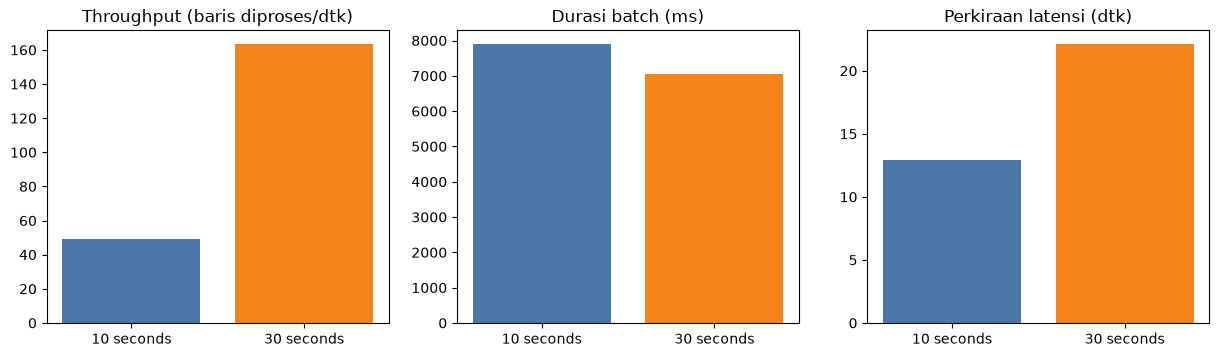

In [29]:
# ===== SOAL 4b: Ukur trigger 10 dtk vs 30 dtk =====
def ukur_trigger(interval, durasi):
    nama = f"uji_trigger_{interval.split()[0]}s"
    hitung = []
    q = mulai_query(nama, agregasi_per_wiki(urai_stream(sumber_stream())), lambda b, i: hitung.append(b.count()),
                    trigger=interval, ckpt=CKPT_DIR / f"{nama}_{uuid.uuid4().hex[:4]}")
    t0 = time.time()
    while time.time() - t0 < durasi:
        time.sleep(5)
        clear_output(wait=True); print(f"Uji trigger {interval}: {time.time() - t0:.0f}/{durasi} dtk | batch {len(hitung)}")
    prog = list(q.recentProgress); q.stop()
    rows, pemanasan = [], True
    for p in prog:
        if not p.get("numInputRows"):
            continue
        if pemanasan:                     # batch berisi data pertama = pemanasan (inisialisasi/backlog), tidak dihitung
            pemanasan = False; continue
        et = p.get("eventTime") or {}
        lag = (pd.Timestamp(p["timestamp"]) - pd.Timestamp(et["max"])).total_seconds() if et.get("max") else None
        rows.append({"trigger": interval, "batch": p["batchId"], "input_baris": p["numInputRows"],
                     "inputRowsPerSecond": round(p.get("inputRowsPerSecond") or 0, 1),
                     "processedRowsPerSecond": round(p.get("processedRowsPerSecond") or 0, 1),
                     "durasi_batch_ms": p.get("durationMs", {}).get("triggerExecution"), "lag_event_max_dtk": lag})
    return pd.DataFrame(rows)

df_trigger = pd.concat([ukur_trigger(i, d) for i, d in DETIK_UJI_TRIGGER.items()], ignore_index=True)
if df_trigger.empty:
    raise RuntimeError("Tidak ada batch berisi data selama uji trigger. Pastikan producer masih berjalan, lalu ulangi sel ini.")
ring = (df_trigger.groupby("trigger", sort=False)
        .agg(batch=("batch", "count"), input_per_batch=("input_baris", "mean"), inputRowsPerSecond=("inputRowsPerSecond", "mean"),
             processedRowsPerSecond=("processedRowsPerSecond", "mean"), durasi_batch_ms=("durasi_batch_ms", "mean")).round(1))
ring["perkiraan_latensi_dtk"] = [round(int(t.split()[0]) / 2 + ms / 1000, 1) for t, ms in zip(ring.index, ring["durasi_batch_ms"])]
with catat("4b_trigger"):
    print(df_trigger.to_string(index=False))
    print("\nRingkasan (rata-rata per batch berisi data):")
    print(ring.to_string())
    print("\nBatch berisi data pertama tiap uji dianggap pemanasan dan tidak dihitung.")
    print("perkiraan_latensi = rata-rata waktu tunggu sampai trigger (interval/2) + durasi batch.")
    print("Trade-off: trigger 10 dtk memberi hasil lebih segar (latensi rendah) tetapi lebih banyak batch kecil, sehingga overhead"
          " tetap per batch (perencanaan, commit offset/state) lebih sering dibayar. Trigger 30 dtk menampung lebih banyak baris per batch,"
          " processedRowsPerSecond biasanya lebih tinggi (throughput lebih efisien), dengan harga data di dashboard lebih basi.")
bukti("4b_trigger_detail", df_trigger); bukti("4b_trigger_ringkas", ring.reset_index())
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for i, (kol, judul) in enumerate([("processedRowsPerSecond", "Throughput (baris diproses/dtk)"), ("durasi_batch_ms", "Durasi batch (ms)"),
                                   ("perkiraan_latensi_dtk", "Perkiraan latensi (dtk)")]):
    ax[i].bar(ring.index, ring[kol], color=["#4C78A8", "#F58518"]); ax[i].set_title(judul)
simpan_grafik(fig, "4b_trigger"); plt.show()
RINGKASAN["4b"] = ring.reset_index().to_dict("records")

## 4c · Hentikan lalu mulai kembali dengan checkpoint yang sama
Bukti: (1) offset awal batch pertama setelah restart = offset akhir sebelum berhenti, (2) hasil per (jendela, wiki) sama
dengan perhitungan batch ulang atas input yang sama (tidak ganda, tidak terlewat), (3) uji data terlambat terhadap watermark.

In [30]:
# ===== Persiapan ulang Soal 4: mode lokal + checkpoint baru =====
import shutil, time
from pathlib import Path

# 1) Hentikan semua query dan pindah ke mode lokal (state & checkpoint di satu disk)
for q in spark.streams.active:
    q.stop()
spark.stop()
spark = buat_spark("lokal", nama=f"{KELOMPOK}-stream-lokal"); sc = spark.sparkContext

# 2) Pindahkan checkpoint lama yang rusak (state tersebar di disk Worker)
ckpt = Path(ROOT_DATA) / f"stream_{RUN_ID}" / "checkpoint" / "utama"
if ckpt.exists():
    lama = ckpt.with_name(f"utama_lama_{int(time.time())}")
    shutil.move(str(ckpt), str(lama))
    print(f"Checkpoint lama dipindah ke: {lama}")
else:
    print(f"Folder {ckpt} tidak ditemukan; query akan membuat yang baru.")

# 3) Mulai query utama dengan checkpoint baru (pemanggilan sama seperti di sel 4c)
q_utama = mulai_query("utama", agregasi_per_wiki(urai_stream(sumber_stream())), simpan_batch_utama)

# 4) Tunggu sampai query benar-benar memproses data
t0 = time.time()
while time.time() - t0 < 240:
    if not q_utama.isActive:
        raise RuntimeError(f"q_utama mati: {str(q_utama.exception())[:600]}")
    if [p for p in q_utama.recentProgress if p["numInputRows"] > 0]:
        print(f"q_utama aktif dan memproses data (batch {q_utama.lastProgress['batchId']}). Lanjut ke sel 4c.")
        break
    time.sleep(3)
else:
    raise RuntimeError(f"Belum ada data dalam 240 dtk. Pesan di topic: {total_pesan():,}. Cek producer Soal 1b.")

Checkpoint lama dipindah ke: C:\Users\Public\uts_bigdata\JOGIS-GANK\stream_51bb3e\checkpoint\utama_lama_1794940759
q_utama aktif dan memproses data (batch 0). Lanjut ke sel 4c.


In [31]:
# ===== SOAL 4c: Verifikasi tidak ganda / tidak terlewat (bandingkan dengan perhitungan batch atas input yang sama) =====
import ast

def offset_teks(o):
    """dict / JSON / repr-dict Python -> JSON terurut (kutip ganda); None/kosong/'None'/'null' -> 'earliest'; 'earliest'/'latest' apa adanya."""
    if o is None:
        return "earliest"
    if isinstance(o, str):
        s = o.strip()
        if s.lower() in ("", "none", "null"):
            return "earliest"
        if s.lower() in ("earliest", "latest"):
            return s.lower()
        try:
            o = json.loads(s)
        except ValueError:
            try:
                o = ast.literal_eval(s)
            except (ValueError, SyntaxError):
                return s
    if o is None:
        return "earliest"
    if isinstance(o, str):
        return o
    return json.dumps(o, sort_keys=True)

time.sleep(25)
lp = q_utama.lastProgress
akhir_run2 = lp["sources"][0]["endOffset"]
wm_stream = pd.Timestamp((lp.get("eventTime") or {}).get("watermark") or "1970-01-01T00:00:00Z")
if MODE_STREAM == "kafka":
    _awal, _akhir = "earliest", offset_teks(akhir_run2)     # baca semua, lalu hanya jendela yang dilihat stream yang dibandingkan
    if not _akhir.startswith("{"):
        raise ValueError(f"endOffset query bukan JSON offset yang valid: {akhir_run2!r}. Pastikan q_utama sudah memproses batch.")
    print("Baca ulang dari Kafka | startingOffsets:", _awal, "| endingOffsets:", _akhir[:80])
    input_batch = (spark.read.format("kafka").option("kafka.bootstrap.servers", BOOTSTRAP).option("subscribe", TOPIC_RAW)
                   .option("startingOffsets", _awal).option("endingOffsets", _akhir).load()
                   .select(F.col("value").cast("string").alias("json"), F.col("timestamp").alias("waktu_masuk")))
else:                                                       # berkas yang benar-benar dibaca stream, dari log checkpoint
    berkas = set()
    for f in (CKPT_DIR / "utama" / "sources" / "0").iterdir():
        if not (f.name.isdigit() or f.name.endswith(".compact")):
            continue
        for b in f.read_text(encoding="utf-8").splitlines():
            if b.startswith("{"):
                berkas.add(json.loads(b)["path"])
    input_batch = spark.read.text(sorted(berkas)).select(F.col("value").alias("json"), F.current_timestamp().alias("waktu_masuk"))
benar = (urai_stream(input_batch).filter(F.col("type") == "edit")
         .groupBy(F.window("event_time", "1 minute"), "wiki").agg(F.count("*").alias("jumlah_edit_batch"))
         .select(F.date_format("window.start", "yyyy-MM-dd HH:mm:ss").alias("jendela_mulai"), F.date_format("window.end", "yyyy-MM-dd HH:mm:ss").alias("jendela_akhir"),
                 "wiki", "jumlah_edit_batch")).toPandas()
for k in ("jendela_mulai", "jendela_akhir"):
    benar[k] = pd.to_datetime(benar[k])
st = hasil_utama()
if st.empty:
    raise RuntimeError("hasil_utama() kosong: stream belum menyimpan hasil. Tunggu beberapa batch lalu jalankan ulang sel ini.")
gab = benar.merge(st[["jendela_mulai", "wiki", "jumlah_edit"]], on=["jendela_mulai", "wiki"], how="outer")
batas_final = wm_stream.tz_convert("Asia/Jakarta").tz_localize(None)       # jendela berupa waktu lokal WIB (date_format)
awal_stream = st["jendela_mulai"].min()                                    # jendela pertama yang dilihat stream (masuk di tengah jendela)
sudah_final = gab["jendela_akhir"] <= batas_final
final = gab[sudah_final & (gab["jendela_mulai"] > awal_stream)]
n_sebelum_stream = int((sudah_final & (gab["jendela_mulai"] <= awal_stream)).sum())
beda = final[final["jumlah_edit"].fillna(-1) != final["jumlah_edit_batch"].fillna(-1)]
dibuang = sum((p.get("stateOperators") or [{}])[0].get("numRowsDroppedByWatermark", 0) or 0 for p in q_utama.recentProgress)
with catat("4c_verifikasi"):
    print(f"Stream mulai melihat data pada jendela {awal_stream}; {n_sebelum_stream:,} baris jendela sebelum itu dikecualikan (di luar jangkauan stream).")
    print(f"Jendela yang dibandingkan (jendela_mulai > {awal_stream} dan jendela_akhir <= watermark {wm_stream}): {len(final)}")
    print(f"Total edit di jendela itu - streaming: {int(final['jumlah_edit'].fillna(0).sum()):,} | batch ulang: {int(final['jumlah_edit_batch'].fillna(0).sum()):,}")
    print(f"Jendela berbeda: {len(beda)} | baris dibuang watermark (sejak restart): {dibuang}")
    if len(beda):
        print(beda.head(10).to_string(index=False))
    print("Kesimpulan:", "tidak ada hitungan ganda maupun data terlewat pada jendela yang diamati stream." if len(beda) == 0 else
          "selisih berasal dari baris yang datang setelah watermark (dibuang) atau batas jendela; periksa baris di atas.")
bukti("4c_verifikasi", final)
try:
    offset_lanjut = offset_teks(akhir_sebelum) == offset_teks(pertama["sources"][0]["startOffset"])
except (NameError, KeyError, TypeError, IndexError):
    offset_lanjut = None
    print("PERINGATAN: sel stop/restart 4c belum selesai pada query ini, jadi 'offset_lanjut_tepat' dikosongkan. "
          "Jalankan sel itu dulu, lalu ulangi sel ini.")
RINGKASAN["4c"] = {"offset_lanjut_tepat": offset_lanjut, "jendela_final": len(final), "jendela_beda": len(beda)}

Baca ulang dari Kafka | startingOffsets: earliest | endingOffsets: {"JOGIS-GANK-wiki-raw": {"0": 62129, "1": 68928, "2": 61358, "3": 62341, "4": 63
Stream mulai melihat data pada jendela 2026-11-18 01:28:00; 13,796 baris jendela sebelum itu dikecualikan (di luar jangkauan stream).
Jendela yang dibandingkan (jendela_mulai > 2026-11-18 01:28:00 dan jendela_akhir <= watermark 2026-11-17 18:37:49+00:00): 476
Total edit di jendela itu - streaming: 11,048 | batch ulang: 11,056
Jendela berbeda: 8 | baris dibuang watermark (sejak restart): 0
      jendela_mulai       jendela_akhir         wiki  jumlah_edit_batch  jumlah_edit
2026-11-18 01:29:00 2026-11-18 01:30:00       bnwiki                1.0          NaN
2026-11-18 01:29:00 2026-11-18 01:30:00       cswiki                1.0          NaN
2026-11-18 01:29:00 2026-11-18 01:30:00  enwikiquote                1.0          NaN
2026-11-18 01:29:00 2026-11-18 01:30:00 frwikisource                1.0          NaN
2026-11-18 01:29:00 2026-11-18 01:3

In [32]:
# ===== SOAL 4c: Uji data terlambat vs watermark (event buatan wiki 'ujiterlambat') =====
def kirim_event_uji(umur_detik, judul):
    ts = int(time.time() - umur_detik)
    ev = {"id": random.randint(10**9, 2 * 10**9), "type": "edit", "wiki": WIKI_UJI, "server_name": "uji.lokal", "title": judul,
          "namespace": 0, "user": "UjiTerlambat", "anon": False, "bot": False, "minor": False, "timestamp": ts,
          "length": {"old": 10, "new": 20}, "comment": "uji data terlambat", "meta_id": str(uuid.uuid4())}
    prod_kontrol.produce(TOPIC_RAW, key=f"{WIKI_UJI}|{judul}".encode(), value=json.dumps(ev).encode("utf-8"))
    prod_kontrol.flush(10)
    return pd.Timestamp(ts, unit="s", tz="UTC").tz_convert("Asia/Jakarta")

dibuang_awal = sum((p.get("stateOperators") or [{}])[0].get("numRowsDroppedByWatermark", 0) or 0 for p in q_utama.recentProgress)
batch_awal = q_utama.lastProgress["batchId"]
waktu_telat = kirim_event_uji(600, "TERLAMBAT_10_MENIT")     # lebih tua dari watermark -> dibuang
waktu_masih = kirim_event_uji(45, "TERLAMBAT_45_DETIK")      # masih dalam batas watermark 2 menit -> dihitung
t0 = time.time()
while time.time() - t0 < 90 and q_utama.lastProgress["batchId"] < batch_awal + 3:
    time.sleep(3)
uji = hasil_utama()
uji = uji[uji["wiki"] == WIKI_UJI]
dibuang_akhir = sum((p.get("stateOperators") or [{}])[0].get("numRowsDroppedByWatermark", 0) or 0 for p in q_utama.recentProgress)
with catat("4c_data_terlambat"):
    print(f"Watermark saat uji: {(q_utama.lastProgress.get('eventTime') or {}).get('watermark')}")
    print(f"Event A (10 menit lalu, {waktu_telat:%H:%M:%S}) dan event B (45 detik lalu, {waktu_masih:%H:%M:%S}) dikirim ke {TOPIC_RAW}.")
    print("Baris hasil streaming untuk wiki uji:")
    print(uji.to_string(index=False) if len(uji) else "  (kosong)")
    print(f"numRowsDroppedByWatermark bertambah: {dibuang_akhir - dibuang_awal}")
    print("Penjelasan: watermark = event time maksimum yang sudah terlihat dikurangi 2 menit. Baris dengan event time lebih tua dari"
          " watermark dianggap terlambat: dibuang dan jendelanya tidak diubah lagi (state jendela lama sudah dihapus). Baris yang masih"
          " di dalam batas watermark tetap memperbarui jendelanya; mode update mengeluarkan versi terbaru jendela itu.")
    print("Peran: OFFSET = posisi baca di Kafka per partisi; CHECKPOINT = log offset tiap batch + commit + state store, sehingga restart"
          " melanjutkan tepat dari batch terakhir dan batch yang belum di-commit diulang dengan offset yang sama (foreachBatch ditulis"
          " per batch_id sehingga pengulangan tidak menggandakan hasil); WATERMARK = batas toleransi keterlambatan sekaligus penentu kapan"
          " state jendela boleh dibuang.")
RINGKASAN["4c_terlambat"] = {"dibuang": dibuang_akhir - dibuang_awal, "baris_uji": len(uji)}

Watermark saat uji: 2026-11-17T18:38:49.000Z
Event A (10 menit lalu, 01:30:35) dan event B (45 detik lalu, 01:39:50) dikirim ke JOGIS-GANK-wiki-raw.
Baris hasil streaming untuk wiki uji:
      jendela_mulai       jendela_akhir         wiki  jumlah_edit  jumlah_bot  rasio_bot  batch_id
2026-11-18 01:39:00 2026-11-18 01:40:00 ujiterlambat            1           0        0.0         8
numRowsDroppedByWatermark bertambah: 1
Penjelasan: watermark = event time maksimum yang sudah terlihat dikurangi 2 menit. Baris dengan event time lebih tua dari watermark dianggap terlambat: dibuang dan jendelanya tidak diubah lagi (state jendela lama sudah dihapus). Baris yang masih di dalam batas watermark tetap memperbarui jendelanya; mode update mengeluarkan versi terbaru jendela itu.
Peran: OFFSET = posisi baca di Kafka per partisi; CHECKPOINT = log offset tiap batch + commit + state store, sehingga restart melanjutkan tepat dari batch terakhir dan batch yang belum di-commit diulang dengan offset yang s

# Dashboard pemantauan (hasil foreachBatch)
Halaman ramai (indikasi peristiwa terkini), bot vs manusia per wiki, dan lonjakan (k dari Soal 3c). Diperbarui tiap 15 detik.

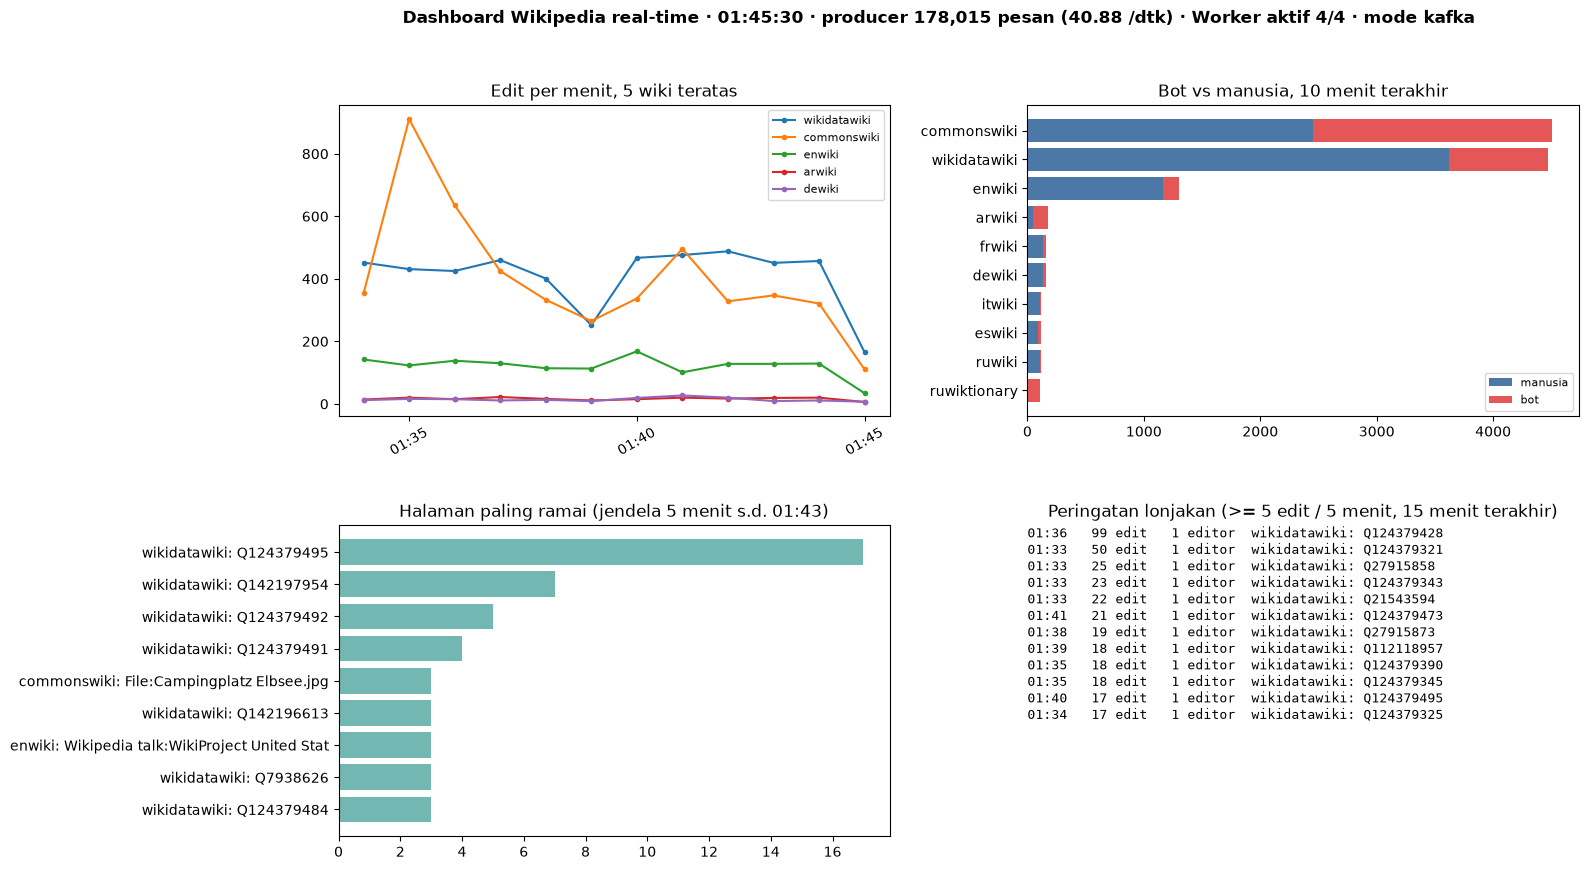

query  aktif  batch  input/dtk
utama   True     37       39.1


In [ ]:
# ===== DASHBOARD =====
import base64
K_DASH = globals().get("K_LONJAKAN", 5)

def gambar_dashboard():
    du, dh = hasil_utama(), hasil_halaman()
    if len(du):
        du = du[du["wiki"] != WIKI_UJI]
    if len(dh):
        dh = dh[dh["wiki"] != WIKI_UJI]
    fig = plt.figure(figsize=(16, 9.5)); g = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.25)
    a1, a2, a3, a4 = fig.add_subplot(g[0, 0]), fig.add_subplot(g[0, 1]), fig.add_subplot(g[1, 0]), fig.add_subplot(g[1, 1])
    if len(du):
        top = du.groupby("wiki")["jumlah_edit"].sum().nlargest(5).index
        for w in top:
            s = du[du["wiki"] == w].sort_values("jendela_mulai").tail(30)
            a1.plot(s["jendela_mulai"], s["jumlah_edit"], marker=".", label=w)
        a1.legend(fontsize=8); a1.tick_params(axis="x", rotation=30)
        a1.xaxis.set_major_formatter(__import__("matplotlib.dates", fromlist=["DateFormatter"]).DateFormatter("%H:%M"))
        batas = du["jendela_mulai"].max() - pd.Timedelta(minutes=10)
        b = du[du["jendela_mulai"] >= batas].groupby("wiki")[["jumlah_edit", "jumlah_bot"]].sum().nlargest(10, "jumlah_edit")
        a2.barh(b.index, b["jumlah_edit"] - b["jumlah_bot"], color="#4C78A8", label="manusia")
        a2.barh(b.index, b["jumlah_bot"], left=b["jumlah_edit"] - b["jumlah_bot"], color="#E45756", label="bot")
        a2.invert_yaxis(); a2.legend(fontsize=8)
    a1.set_title("Edit per menit, 5 wiki teratas"); a2.set_title("Bot vs manusia, 10 menit terakhir")
    if len(dh):
        lengkap = dh.loc[dh["jendela_akhir"] <= pd.Timestamp.now(), "jendela_akhir"]     # jendela yang sudah selesai
        akhir = lengkap.max() if len(lengkap) else dh["jendela_akhir"].max()
        terbaru = dh[dh["jendela_akhir"] == akhir].nlargest(10, "jumlah_edit")
        a3.barh([f"{w}: {t[:38]}" for w, t in zip(terbaru["wiki"], terbaru["title"])], terbaru["jumlah_edit"], color="#72B7B2")
        a3.invert_yaxis(); a3.set_title(f"Halaman paling ramai (jendela 5 menit s.d. {akhir:%H:%M})")
        lj = dh[(dh["jumlah_edit"] >= K_DASH) & (dh["jendela_akhir"] >= akhir - pd.Timedelta(minutes=15))]
        lj = lj.sort_values("jumlah_edit", ascending=False).drop_duplicates(["wiki", "title"]).head(12)
        teks = "\n".join(f"{r.jendela_akhir:%H:%M}  {r.jumlah_edit:>3} edit  {int(r.editor_unik):>2} editor  {r.wiki}: {str(r.title)[:34]}"
                         for r in lj.itertuples()) or "(belum ada lonjakan)"
    else:
        teks = "(belum ada data)"; a3.set_title("Halaman paling ramai")
    a4.axis("off"); a4.set_title(f"Peringatan lonjakan (>= {K_DASH} edit / 5 menit, 15 menit terakhir)")
    a4.text(0, 1, teks, va="top", family="monospace", fontsize=9)
    s = produsen.ringkas()
    fig.suptitle(f"Dashboard Wikipedia real-time · {time.strftime('%H:%M:%S')} · producer {s.get('terkirim', 0):,} pesan "
                 f"({s['laju_rata']} /dtk) · Worker aktif {len(pemantau.aktif())}/{N_WORKER} · mode {MODE_STREAM}", fontsize=12, fontweight="bold")
    return fig

def jalankan_dashboard(menit=MENIT_DASHBOARD, refresh=15):
    t0 = time.time()
    try:
        while True:
            fig = gambar_dashboard()
            clear_output(wait=True); display(fig)
            print(pd.DataFrame([{"query": q.name, "aktif": q.isActive, "batch": (q.lastProgress or {}).get("batchId"),
                                 "input/dtk": round((q.lastProgress or {}).get("inputRowsPerSecond") or 0, 1)} for q in spark.streams.active]).to_string(index=False))
            if time.time() - t0 >= menit * 60:
                break
            plt.close(fig); time.sleep(refresh)
    except KeyboardInterrupt:
        print("Dashboard dihentikan.")
    p = simpan_grafik(fig, "dashboard"); plt.close(fig)
    html = (f"<html><head><meta charset='utf-8'><title>Dashboard {KELOMPOK}</title></head><body>"
            f"<h2>Dashboard pemantauan Wikipedia - {KELOMPOK}</h2><p>Disimpan {time.strftime('%Y-%m-%d %H:%M:%S')}</p>"
            f"<img style='max-width:100%' src='data:image/png;base64,{base64.b64encode(p.read_bytes()).decode()}'/></body></html>")
    (LAPORAN_DIR / "dashboard.html").write_text(html, encoding="utf-8")
    print("Dashboard disimpan:", p, "dan", LAPORAN_DIR / "dashboard.html")

jalankan_dashboard()

# Penutup: hentikan semua komponen dan simpan ringkasan
Jalankan setelah semua bukti terkumpul. Worker menerima perintah `BERHENTI` dan mematikan Spark Worker-nya.

In [ ]:
# ===== PENUTUP =====
#HENTIKAN_SPARK_MASTER = True
#for q in list(spark.streams.active):
#    q.stop()
#if globals().get("jembatan"):
#    jembatan.berhenti()
#produsen.berhenti()
#RINGKASAN["producer_akhir"] = {k: v for k, v in produsen.ringkas().items() if k != "galat_terakhir"}
#RINGKASAN["selesai"] = time.strftime("%Y-%m-%d %H:%M:%S")
#bukti("ringkasan", RINGKASAN)
#(LAPORAN_DIR / "ringkasan.json").write_text(json.dumps(RINGKASAN, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
#bukti("log_status_worker", pemantau.log[-5000:])
#kirim_kontrol("BERHENTI", hentikan_spark=True)
#time.sleep(5)
#spark.stop()
#if HENTIKAN_SPARK_MASTER:
    hentikan_proses(PROSES.get("spark_master"))
pemantau.berhenti()
print("Ringkasan:", json.dumps({k: RINGKASAN[k] for k in ("1b", "1c", "snapshot") if k in RINGKASAN}, default=str)[:800])
print(f"\nBerkas bukti di {LAPORAN_DIR.resolve()}:")
for f in sorted(LAPORAN_DIR.rglob("*")):
    if f.is_file():
        print(f"  {f.relative_to(LAPORAN_DIR)}  ({f.stat().st_size / 1024:.1f} KB)")

In [ ]:
cid = kirim_kontrol("CEK_FILE", path=str(SNAP_PATH), topic=TOPIC_RAW,
                    awal={str(p): o for p, o in SNAP_AWAL.items()},
                    akhir={str(p): o for p, o in SNAP_AKHIR.items()})
bal = pemantau.tunggu_balasan(cid, N_WORKER, timeout=600)
df = pd.DataFrame([{"pc": "MASTER", **info_master}] +
                  [{"pc": w, **{k: d.get(k) for k in ("baris", "md5", "galat")}} for w, d in sorted(bal.items())])
df["md5_sama"] = df["md5"] == info_master["md5"]
print(df.to_string(index=False))

In [ ]:
import os, socket, getpass
p = str(SNAP_PATH)
hasil = (spark.sparkContext.parallelize(range(200), 200)
         .map(lambda _: (socket.gethostname(), getpass.getuser(), os.path.exists(p)))
         .distinct().collect())
for h in sorted(hasil): print(h)